# ECE 3715 Mini-Project 3

## Random Vectors and the Multivariate Gaussian
Professor: Dr. Nir Regev

Team Members: Brandon Chie, Octavio Reyna, William Hsu

Start Date: November 14, 2026

Due Date: November 23, 2026

## Objective
Use joint, marginal and conditional densities, covariance matrices, linear transformations and the multivariate Gaussian to study several correlated random variables at once. We will use eigendecomposition and whitening to remove correlation, and then fuse two sensors with correlated noise into one linear MMSE estimate.

In [1]:
import time #Used for the timer function
import numpy #Used for easy array manipulation functions & RNG
import scipy #Used for numerical integration and the multivariate normal check
import matplotlib.pyplot as plt #Used for plotting graphs
import mp3lib as func #Functions from mp3lib.py file

T_START = time.time()     #Timer begins for total notebook time

SEED = 295929189          #Drawn 2026-11-14, do not change
rng = numpy.random.default_rng(SEED)
rng1, rng2, rng3, rng4, rng5, rng6, rng7, rng8, rngA = rng.spawn(9)   #rngA is for Bonus A, adding it does not change rng1 to rng8

In [2]:
#Handcheckable Test
#Assert confirms that the comparison is true, if not assert error will pop up

#Sample Mean and Covariance Test
#Three samples of two variables, the mean is [2, 4] and the covariance can be done by hand
X_test = numpy.array([[1, 2], [2, 4], [3, 6]])
mean_test, cov_test = func.sample_mean_cov(X_test)
assert numpy.allclose(mean_test, [2, 4])
assert numpy.allclose(cov_test, [[1, 2], [2, 4]]) #Var(x) = 1, Var(y) = 4, Cov = 2
print(f"Sample Mean Test:       {mean_test}")
print(f"Sample Covariance Test: {cov_test[0]}")
print(f"                        {cov_test[1]}")

#Valid Covariance Test
#Identity matrix is valid, a non symmetric matrix is not, and [[1, 2], [2, 1]] has eigenvalues 3 and -1 so it is not
assert func.is_valid_covariance(numpy.eye(2)) == True
assert func.is_valid_covariance([[1, 2], [0, 1]]) == False
assert func.is_valid_covariance([[1, 2], [2, 1]]) == False
print("\nValid Covariance Test:")
print(f"Identity:              {func.is_valid_covariance(numpy.eye(2))}")
print(f"Non symmetric:         {func.is_valid_covariance([[1, 2], [0, 1]])}")
print(f"Negative eigenvalue:   {func.is_valid_covariance([[1, 2], [2, 1]])}")

#Gaussian PDF Test
#For a 2D standard Gaussian the density at the mean is 1/(2pi)
assert numpy.isclose(func.gaussian_pdf([0, 0], [0, 0], numpy.eye(2)), 1 / (2 * numpy.pi))
print("\nGaussian PDF Test:")
print(f"f(0, 0): {func.gaussian_pdf([0, 0], [0, 0], numpy.eye(2)):.6f}   1/(2pi): {1 / (2 * numpy.pi):.6f}")

#Whitening Matrix Test
#For Sigma = diag(4, 9) the whitening matrix should give W Sigma W^T = I
Sigma_test = numpy.diag([4.0, 9.0])
W_test = func.whitening_matrix(Sigma_test)
assert numpy.allclose(W_test @ Sigma_test @ W_test.T, numpy.eye(2))
print("\nWhitening Test:")
print(f"W Sigma W^T: {(W_test @ Sigma_test @ W_test.T)[0]}")
print(f"             {(W_test @ Sigma_test @ W_test.T)[1]}")

#LMMSE Weights Test
#Sigma_xx = 2I and Sigma_sx = [1, 1] should give equal weights of 0.5
assert numpy.allclose(func.lmmse_weights(2 * numpy.eye(2), [1, 1]), [0.5, 0.5])
print("\nLMMSE Weights Test:")
print(f"w: {func.lmmse_weights(2 * numpy.eye(2), [1, 1])}")

print("\nAll functions work as expected!")

Sample Mean Test:       [2. 4.]
Sample Covariance Test: [1. 2.]
                        [2. 4.]

Valid Covariance Test:
Identity:              True
Non symmetric:         False
Negative eigenvalue:   False

Gaussian PDF Test:
f(0, 0): 0.159155   1/(2pi): 0.159155

Whitening Test:
W Sigma W^T: [1. 0.]
             [0. 1.]

LMMSE Weights Test:
w: [0.5 0.5]

All functions work as expected!


## Step 1: Two Variables at Once

**Objective:** Find the joint, marginal and conditional densities of two random variables by hand and confirm them numerically.

$$f_{XY}(x,y)=x+y \qquad 0\leq x\leq 1,\; 0\leq y\leq 1$$

**Process:** We will verify the density, find the marginals, the conditional density and the moments by hand, then check each one with quadrature. Then we will generate a million samples by rejection sampling and compare the sample statistics with the exact values.

### Valid Density

$$x\geq 0,\; y\geq 0 \;\Rightarrow\; f_{XY}(x,y)=x+y\geq 0$$

From 0 to 1:

$$\int_0^1\int_0^1 (x+y)\,dx\,dy=\int_0^1\left[\frac{x^2}{2}+xy\right]_0^1dy$$

$$=\int_0^1\left(\frac{1}{2}+y\right)dy=\left[\frac{y}{2}+\frac{y^2}{2}\right]_0^1$$

$$=\frac{1}{2}+\frac{1}{2}=1$$

### Marginal Densities

Marginal of X:

$$f_X(x)=\int_0^1 (x+y)\,dy=\left[xy+\frac{y^2}{2}\right]_0^1$$

$$f_X(x)=x+\frac{1}{2} \qquad 0\leq x\leq 1$$

Marginal of Y:

$$f_Y(y)=\int_0^1 (x+y)\,dx=\left[\frac{x^2}{2}+xy\right]_0^1$$

$$f_Y(y)=y+\frac{1}{2} \qquad 0\leq y\leq 1$$

@ $x=0.3$:

$$f_X(0.3)=0.3+0.5=0.8$$

### Conditional Density of Y given X = x

$$f_{Y|X}(y\mid x)=\frac{f_{XY}(x,y)}{f_X(x)}=\frac{x+y}{x+\frac{1}{2}}$$

@ $x=0.3$:

$$f_{Y|X}(y\mid 0.3)=\frac{0.3+y}{0.8}$$

From 0 to 1:

$$\int_0^1\frac{0.3+y}{0.8}\,dy=\frac{1}{0.8}\left[0.3y+\frac{y^2}{2}\right]_0^1=\frac{0.3+0.5}{0.8}=1$$

### Moments

The density is the same if we swap x and y, f(x, y) = f(y, x), so every result for X is also true for Y. This means E[Y] = E[X] and Var(Y) = Var(X).

Mean:

$$E[X]=\int_0^1 x\left(x+\frac{1}{2}\right)dx=\left[\frac{x^3}{3}+\frac{x^2}{4}\right]_0^1=\frac{1}{3}+\frac{1}{4}$$

$$E[X]=E[Y]=\frac{7}{12}=0.583333$$

Variance:

$$E[X^2]=\int_0^1 x^2\left(x+\frac{1}{2}\right)dx=\left[\frac{x^4}{4}+\frac{x^3}{6}\right]_0^1=\frac{1}{4}+\frac{1}{6}=\frac{5}{12}$$

$$\text{Var}(X)=E[X^2]-E[X]^2=\frac{5}{12}-\frac{49}{144}=\frac{60}{144}-\frac{49}{144}$$

$$\text{Var}(X)=\frac{11}{144}=0.0763889$$

E[XY]:

$$E[XY]=\int_0^1\int_0^1 xy(x+y)\,dx\,dy=\int_0^1\int_0^1 x^2y\,dx\,dy+\int_0^1\int_0^1 xy^2\,dx\,dy$$

$$=\frac{1}{3}\cdot\frac{1}{2}+\frac{1}{2}\cdot\frac{1}{3}=\frac{1}{6}+\frac{1}{6}$$

$$E[XY]=\frac{1}{3}$$

Covariance:

$$\text{Cov}(X,Y)=E[XY]-E[X]E[Y]=\frac{1}{3}-\frac{49}{144}=\frac{48}{144}-\frac{49}{144}$$

$$\text{Cov}(X,Y)=-\frac{1}{144}=-0.00694444$$

Correlation coefficient:

$$\rho=\frac{\text{Cov}(X,Y)}{\sqrt{\text{Var}(X)\text{Var}(Y)}}=\frac{-1/144}{11/144}$$

$$\rho=-\frac{1}{11}=-0.0909091$$

In [3]:
#Step 1: Two variables at once

#Joint density f(x, y) = x + y on the unit square, 0 everywhere else
def joint_pdf(x, y):
    x = numpy.asarray(x, dtype=float)
    y = numpy.asarray(y, dtype=float)
    inside = (x >= 0) & (x <= 1) & (y >= 0) & (y <= 1)
    return numpy.where(inside, x + y, 0)

#Analytical marginal of X: f_X(x) = x + 1/2
def marginal_x(x):
    return x + 0.5

#Analytical marginal of Y: f_Y(y) = y + 1/2
def marginal_y(y):
    return y + 0.5

#Analytical conditional of Y given X = x: f(y|x) = (x + y)/(x + 1/2)
def conditional_y_given_x(y, x):
    return (x + y) / (x + 0.5)

#Part 1: Valid density

#Integrates the joint density over the whole unit square to check that it equals 1
#dblquad wants the function written with y first, because y is the variable it integrates first
total_probability = scipy.integrate.dblquad(lambda y, x: x + y, 0, 1, 0, 1)[0]

#Grid of x and y values used for the numerical marginals and the plots
x_grid = numpy.linspace(0, 1, 1001)
y_grid = numpy.linspace(0, 1, 1001)
X_grid, Y_grid = numpy.meshgrid(x_grid, y_grid, indexing="ij") #Each row of the grid has one x value and each column has one y value
joint_grid = joint_pdf(X_grid, Y_grid)

print("Part 1: Valid Density")
print(f"Smallest value of f(x, y) on the grid: {joint_grid.min():.6f}")
print(f"Largest value of f(x, y) on the grid:  {joint_grid.max():.6f}")
print(f"2D quadrature of f(x, y):              {total_probability:.10f}")
print(f"Difference from 1:                     {abs(total_probability - 1):.2e}")

#Part 2: Marginals

#Adds up the joint density across each row (over y) to get f_X, and down each column (over x) to get f_Y
fx_numerical = scipy.integrate.simpson(joint_grid, x=y_grid, axis=1)
fy_numerical = scipy.integrate.simpson(joint_grid, x=x_grid, axis=0)

#Largest difference between the numerical and analytical marginals
fx_max_diff = numpy.max(numpy.abs(fx_numerical - marginal_x(x_grid)))
fy_max_diff = numpy.max(numpy.abs(fy_numerical - marginal_y(y_grid)))

print("\nPart 2: Marginals")
print(f"Largest difference f_X numerical vs analytical: {fx_max_diff:.2e}")
print(f"Largest difference f_Y numerical vs analytical: {fy_max_diff:.2e}")
print(f"f_X(0.3) analytical: {marginal_x(0.3):.6f}   numerical: {fx_numerical[300]:.6f}")

#Part 3: Conditional density at x = 0.3

x0 = 0.3

#Analytical conditional on the y grid
conditional_analytical = conditional_y_given_x(y_grid, x0)

#Numerical conditional: joint density along x = 0.3 divided by the numerical marginal at x = 0.3
fx0_numerical = scipy.integrate.simpson(joint_pdf(x0, y_grid), x=y_grid)
conditional_numerical = joint_pdf(x0, y_grid) / fx0_numerical

#Integral of the conditional density over y
conditional_integral = scipy.integrate.quad(lambda y: conditional_y_given_x(y, x0), 0, 1)[0]

print("\nPart 3: Conditional Density at x = 0.3")
print(f"Integral of f(y | 0.3):                      {conditional_integral:.10f}")
print(f"Largest difference numerical vs analytical:  {numpy.max(numpy.abs(conditional_numerical - conditional_analytical)):.2e}")
print(f"f(y | 0.3) at y = 0: {conditional_y_given_x(0, x0):.4f}   at y = 1: {conditional_y_given_x(1, x0):.4f}")

#Part 4: Moments

#Hand calculated values
E_X_exact = 7 / 12
E_Y_exact = 7 / 12
E_XY_exact = 1 / 3
Var_X_exact = 11 / 144
Cov_XY_exact = -1 / 144
rho_exact = -1 / 11

#Quadrature values. Each one multiplies a quantity by the density and integrates it over the unit square.
E_X_quad = scipy.integrate.dblquad(lambda y, x: x * (x + y), 0, 1, 0, 1)[0]
E_Y_quad = scipy.integrate.dblquad(lambda y, x: y * (x + y), 0, 1, 0, 1)[0]
E_XY_quad = scipy.integrate.dblquad(lambda y, x: x * y * (x + y), 0, 1, 0, 1)[0]
E_X2_quad = scipy.integrate.dblquad(lambda y, x: x**2 * (x + y), 0, 1, 0, 1)[0]
E_Y2_quad = scipy.integrate.dblquad(lambda y, x: y**2 * (x + y), 0, 1, 0, 1)[0]

#Variance, covariance and correlation from the quadrature moments
Var_X_quad = E_X2_quad - E_X_quad**2
Var_Y_quad = E_Y2_quad - E_Y_quad**2
Cov_XY_quad = E_XY_quad - E_X_quad * E_Y_quad
rho_quad = Cov_XY_quad / numpy.sqrt(Var_X_quad * Var_Y_quad)

#Array of hand calculated values
exact_moments = numpy.array([E_X_exact, E_Y_exact, E_XY_exact, Var_X_exact, Cov_XY_exact, rho_exact])

#Array of quadrature values
quad_moments = numpy.array([E_X_quad, E_Y_quad, E_XY_quad, Var_X_quad, Cov_XY_quad, rho_quad])

#Difference between the quadrature and hand calculated values
diff_moments = numpy.abs(quad_moments - exact_moments)

print("\nPart 4: Moments")
print("Quantity      By Hand      Exact          Quadrature     Difference")
print(f"E[X]:         7/12         {exact_moments[0]:<15.6f}{quad_moments[0]:<15.6f}{diff_moments[0]:.2e}")
print(f"E[Y]:         7/12         {exact_moments[1]:<15.6f}{quad_moments[1]:<15.6f}{diff_moments[1]:.2e}")
print(f"E[XY]:        1/3          {exact_moments[2]:<15.6f}{quad_moments[2]:<15.6f}{diff_moments[2]:.2e}")
print(f"Var(X):       11/144       {exact_moments[3]:<15.6f}{quad_moments[3]:<15.6f}{diff_moments[3]:.2e}")
print(f"Cov(X,Y):     -1/144       {exact_moments[4]:<15.6f}{quad_moments[4]:<15.6f}{diff_moments[4]:.2e}")
print(f"rho:          -1/11        {exact_moments[5]:<15.6f}{quad_moments[5]:<15.6f}{diff_moments[5]:.2e}")
print(f"\nLargest difference between quadrature and hand values: {diff_moments.max():.2e}")

Part 1: Valid Density
Smallest value of f(x, y) on the grid: 0.000000
Largest value of f(x, y) on the grid:  2.000000
2D quadrature of f(x, y):              1.0000000000
Difference from 1:                     0.00e+00

Part 2: Marginals
Largest difference f_X numerical vs analytical: 4.44e-16
Largest difference f_Y numerical vs analytical: 1.11e-15
f_X(0.3) analytical: 0.800000   numerical: 0.800000

Part 3: Conditional Density at x = 0.3
Integral of f(y | 0.3):                      1.0000000000
Largest difference numerical vs analytical:  0.00e+00
f(y | 0.3) at y = 0: 0.3750   at y = 1: 1.6250

Part 4: Moments
Quantity      By Hand      Exact          Quadrature     Difference
E[X]:         7/12         0.583333       0.583333       1.11e-16
E[Y]:         7/12         0.583333       0.583333       1.11e-16
E[XY]:        1/3          0.333333       0.333333       1.11e-16
Var(X):       11/144       0.076389       0.076389       5.55e-17
Cov(X,Y):     -1/144       -0.006944      -0.0069

### Rejection Sampling

We pick random points on the unit square, where every spot has the same chance of being picked. We keep each point only if it meets the criteria below. 
$$U\cdot M\leq f_{XY}(x,y)$$

- $U$ = uniform random number between 0 and 1
- $M$ = bounding constant

The bounding constant we chose for the simulation is 2 because it is the largest value on the unit square. Using a smaller bounding constant will generate the wrong samples, using a larger value than 2 will generate the correct samples but it'll cost us the speed of the notebook. 

In [4]:
#Part 5: Rejection sampling

N_1 = 10**6 #One million samples

#Bounding constant. The density x + y is largest at (1, 1), where it equals 2.
M = 2

#Number of proposals. About half get accepted, so we propose a little more than 2 million.
N_proposals = int(2.2 * N_1)

#Proposals from the uniform density on the unit square
x_proposals = rng1.random(N_proposals)
y_proposals = rng1.random(N_proposals)

#Uniform numbers used to decide if each proposal is accepted
u_accept = rng1.random(N_proposals)

#Accept the proposal if U * M is less than or equal to f(x, y)
accepted = u_accept * M <= joint_pdf(x_proposals, y_proposals)

#Acceptance rate and its standard error
acceptance_rate = accepted.mean()
acceptance_se = numpy.sqrt(acceptance_rate * (1 - acceptance_rate) / N_proposals)

#Makes sure that we have at least one million accepted samples. If not, an assert error will pop up.
assert accepted.sum() >= N_1

#Keeps the first one million accepted samples
x_samples = x_proposals[accepted][:N_1]
y_samples = y_proposals[accepted][:N_1]

print("Rejection Sampling")
print(f"Proposals:          {N_proposals}")
print(f"Accepted:           {accepted.sum()}")
print(f"Acceptance rate:    {acceptance_rate:.5f}   Standard Error: {acceptance_se:.5f}")
print(f"Expected rate 1/M:  {1 / M}")
print(f"Difference:         {abs(acceptance_rate - 1 / M):.5f}")

#Sample statistics
E_X_sim = numpy.mean(x_samples)
E_Y_sim = numpy.mean(y_samples)
E_XY_sim = numpy.mean(x_samples * y_samples)
Var_X_sim = numpy.var(x_samples)
Cov_XY_sim = numpy.mean((x_samples - E_X_sim) * (y_samples - E_Y_sim))
rho_sim = numpy.corrcoef(x_samples, y_samples)[0, 1]

#Standard errors
#For an average, the standard error is the standard deviation divided by sqrt(N)
#Var and Cov are also averages of squared distances from the mean, so the same formula works
se_E_X = numpy.std(x_samples) / numpy.sqrt(N_1)
se_E_Y = numpy.std(y_samples) / numpy.sqrt(N_1)
se_E_XY = numpy.std(x_samples * y_samples) / numpy.sqrt(N_1)
se_Var_X = numpy.std((x_samples - E_X_sim)**2) / numpy.sqrt(N_1)
se_Cov_XY = numpy.std((x_samples - E_X_sim) * (y_samples - E_Y_sim)) / numpy.sqrt(N_1)

#The correlation is not a simple average. The usual formula for its standard error only works for Gaussian data.
#So we split the samples into 100 groups of 10^4 and find rho in each group.
#The standard error is the standard deviation of those 100 values divided by sqrt(100).
n_batches = 100
x_batches = x_samples.reshape(n_batches, -1)
y_batches = y_samples.reshape(n_batches, -1)
rho_batches = numpy.array([numpy.corrcoef(x_batches[i], y_batches[i])[0, 1] for i in range(n_batches)])
se_rho = numpy.std(rho_batches, ddof=1) / numpy.sqrt(n_batches)

#Array of sample values
sim_moments = numpy.array([E_X_sim, E_Y_sim, E_XY_sim, Var_X_sim, Cov_XY_sim, rho_sim])

#Array of standard errors
standard_errors = numpy.array([se_E_X, se_E_Y, se_E_XY, se_Var_X, se_Cov_XY, se_rho])

#Difference between the sample and exact values
diff_sim = numpy.abs(sim_moments - exact_moments)

#Checks if the difference is within 3 standard errors
within_three_SE = diff_sim <= 3 * standard_errors

print("\nQuantity      Exact          Sample         Difference     SE             Within 3 SE")
print(f"E[X]:         {exact_moments[0]:<15.6f}{sim_moments[0]:<15.6f}{diff_sim[0]:<15.6f}{standard_errors[0]:<15.6f}{within_three_SE[0]}")
print(f"E[Y]:         {exact_moments[1]:<15.6f}{sim_moments[1]:<15.6f}{diff_sim[1]:<15.6f}{standard_errors[1]:<15.6f}{within_three_SE[1]}")
print(f"E[XY]:        {exact_moments[2]:<15.6f}{sim_moments[2]:<15.6f}{diff_sim[2]:<15.6f}{standard_errors[2]:<15.6f}{within_three_SE[2]}")
print(f"Var(X):       {exact_moments[3]:<15.6f}{sim_moments[3]:<15.6f}{diff_sim[3]:<15.6f}{standard_errors[3]:<15.6f}{within_three_SE[3]}")
print(f"Cov(X,Y):     {exact_moments[4]:<15.6f}{sim_moments[4]:<15.6f}{diff_sim[4]:<15.6f}{standard_errors[4]:<15.6f}{within_three_SE[4]}")
print(f"rho:          {exact_moments[5]:<15.6f}{sim_moments[5]:<15.6f}{diff_sim[5]:<15.6f}{standard_errors[5]:<15.6f}{within_three_SE[5]}")

#Conditional mean of Y given X = x, used for Part 6
#E[Y | X = x] = (x/2 + 1/3)/(x + 1/2)
def conditional_mean_y(x):
    return (x / 2 + 1 / 3) / (x + 0.5)

#Samples of Y when X is small (below 0.1) and when X is large (above 0.9)
y_in_small_x = y_samples[x_samples < 0.1]
y_in_large_x = y_samples[x_samples > 0.9]

#Sample mean of Y in each bin
y_small_x = y_in_small_x.mean()
y_large_x = y_in_large_x.mean()

#Standard error of each bin mean, SE = s/sqrt(N)
se_small_x = y_in_small_x.std() / numpy.sqrt(len(y_in_small_x))
se_large_x = y_in_large_x.std() / numpy.sqrt(len(y_in_large_x))

#Difference between the sample mean and the analytical value at the bin center
diff_small_x = abs(y_small_x - conditional_mean_y(0.05))
diff_large_x = abs(y_large_x - conditional_mean_y(0.95))

print("\nPart 6: Conditional Mean of Y")
print(f"E[Y | X = 0] analytical: {conditional_mean_y(0):.4f}    E[Y | X = 1] analytical: {conditional_mean_y(1):.4f}")
print("Bin            Sample Mean of Y     Analytical at Bin Center     Difference     SE")
print(f"X < 0.1:       {y_small_x:<21.4f}{conditional_mean_y(0.05):<29.4f}{diff_small_x:<15.4f}{se_small_x:.4f}")
print(f"X > 0.9:       {y_large_x:<21.4f}{conditional_mean_y(0.95):<29.4f}{diff_large_x:<15.4f}{se_large_x:.4f}")

Rejection Sampling
Proposals:          2200000
Accepted:           1099467
Acceptance rate:    0.49976   Standard Error: 0.00034
Expected rate 1/M:  0.5
Difference:         0.00024

Quantity      Exact          Sample         Difference     SE             Within 3 SE
E[X]:         0.583333       0.583035       0.000298       0.000277       True
E[Y]:         0.583333       0.583865       0.000531       0.000276       True
E[XY]:        0.333333       0.333554       0.000221       0.000236       True
Var(X):       0.076389       0.076502       0.000113       0.000076       True
Cov(X,Y):     -0.006944      -0.006859      0.000085       0.000075       True
rho:          -0.090909      -0.089741      0.001168       0.001097       True

Part 6: Conditional Mean of Y
E[Y | X = 0] analytical: 0.6667    E[Y | X = 1] analytical: 0.5556
Bin            Sample Mean of Y     Analytical at Bin Center     Difference     SE
X < 0.1:       0.6510               0.6515                       0.0005      

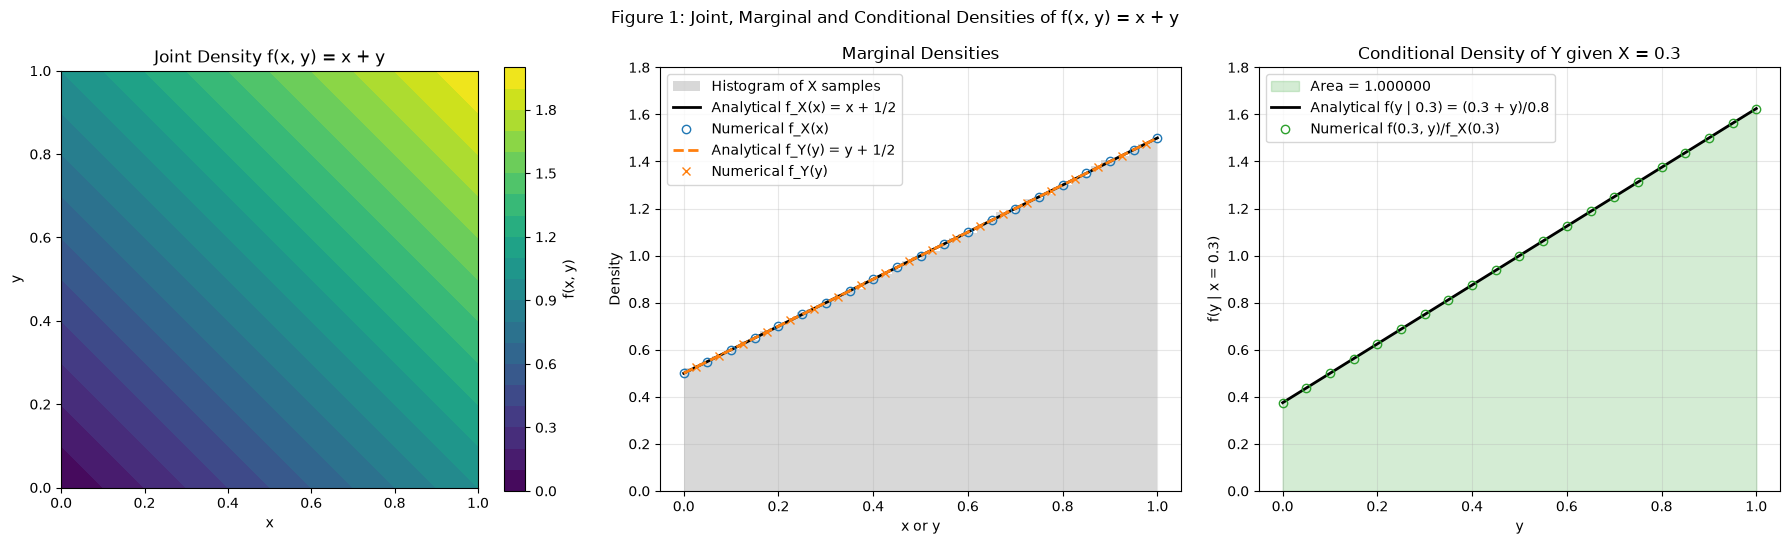

In [5]:
#Figure 1: joint density, marginals and conditional density

plt.figure(figsize=(18, 5.5))

#Joint density heatmap
plt.subplot(1, 3, 1)
plt.contourf(X_grid, Y_grid, joint_grid, levels=20, cmap="viridis")
plt.colorbar(label="f(x, y)")
plt.gca().set_aspect("equal")
plt.title("Joint Density f(x, y) = x + y")
plt.xlabel("x")
plt.ylabel("y")

#Marginals. The analytical ones are lines and the numerical ones are markers.
#Only every 50th grid point gets a marker so the line is still visible.
plt.subplot(1, 3, 2)
plt.hist(x_samples, bins=50, range=(0, 1), density=True, alpha=0.3, color="gray", label="Histogram of X samples")
plt.plot(x_grid, marginal_x(x_grid), "black", linewidth=2, label="Analytical f_X(x) = x + 1/2")
plt.plot(x_grid[::50], fx_numerical[::50], "o", color="tab:blue", markerfacecolor="none", label="Numerical f_X(x)")
plt.plot(y_grid, marginal_y(y_grid), "--", color="tab:orange", linewidth=2, label="Analytical f_Y(y) = y + 1/2")
plt.plot(y_grid[25::50], fy_numerical[25::50], "x", color="tab:orange", label="Numerical f_Y(y)")
plt.ylim(0, 1.8)
plt.title("Marginal Densities")
plt.xlabel("x or y")
plt.ylabel("Density")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

#Conditional density at x = 0.3
plt.subplot(1, 3, 3)
plt.fill_between(y_grid, conditional_analytical, color="tab:green", alpha=0.2, label=f"Area = {conditional_integral:.6f}")
plt.plot(y_grid, conditional_analytical, "black", linewidth=2, label="Analytical f(y | 0.3) = (0.3 + y)/0.8")
plt.plot(y_grid[::50], conditional_numerical[::50], "o", color="tab:green", markerfacecolor="none", label="Numerical f(0.3, y)/f_X(0.3)")
plt.ylim(0, 1.8)
plt.title("Conditional Density of Y given X = 0.3")
plt.xlabel("y")
plt.ylabel("f(y | x = 0.3)")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.suptitle("Figure 1: Joint, Marginal and Conditional Densities of f(x, y) = x + y")
plt.tight_layout()
plt.show()

### Figure 1 Explanation

    The left graph shows the joint density. The brigther the color the higher the density so as you move up diagonally from the origina to 1,1 you will notice an increase in density. The middle graph shows the mariginal desnities. You will notice that the numerical marginals land right on the analytical lines x + 1/2 and y + 1/2 with a largest difference of 1.11e-15. The gray histogram of the X samples follows the same line. Both marginals are the same because the density stays the same if we swap x and y. The right graph depicts the conditional density of Y given X = 0.3, which goes from 0.3750 at y = 0 to 1.6250 at y = 1. Its area is 1. The quadrature of the joint density was also 1. The quadrature values matched all of our hand calculations with a largest difference of 2.58e-15, which means our hand calculations are correct.

    For rejection sampling the acceptance rate was 0.49976 with a difference of 0.00024 and a standard error of 0.00034. This is close to the expected 0.5, which is 1 divided by our bounding constant of 2. All of the sample statistics were within 3 standard errors of the exact values. For example, the sample correlation was -0.089741 compared to the exact -0.090909 with a standard error of 0.001097. This means the samples from our rejection sampling follow the correct density.

### Correlation is Negative Explanation
    Correlation is small and negative because when x is a small value near zero, the density is mostly made of y, so larger values of Y are more likely. When x is a large value near 1, x adds the same amount to every value of y, so Y is spread out more evenly and the average value of Y decreases.

## Step 2: Uncorrelated Does Not Mean Independent

**Objective:** Show that two variables can have a correlation of 0 and still depend completely on each other, and that this can't happen for a jointly Gaussian pair.

$$X\sim\text{Uniform}(-1,1) \qquad Y=X^2$$

**Process:** We will show by hand that Cov(X, Y) = 0 and check it with 10 million samples. Then we will show that Y depends completely on X with a scatter plot and with the variance of Y in narrow bins of x. Finally, we will generate a jointly Gaussian pair with rho = 0 and check that its joint probabilities equal the product of its marginals.

### Covariance of X and Y = X²

PDF of X:

$$f_X(x)=\frac{1}{2} \qquad -1<x<1$$

Mean of X:

$$E[X]=\int_{-1}^{1}\frac{x}{2}\,dx=\left[\frac{x^2}{4}\right]_{-1}^{1}=\frac{1}{4}-\frac{1}{4}=0$$

Mean of Y:

$$E[Y]=E[X^2]=\int_{-1}^{1}\frac{x^2}{2}\,dx=\left[\frac{x^3}{6}\right]_{-1}^{1}=\frac{1}{6}+\frac{1}{6}=\frac{1}{3}$$

Covariance:

$$\text{Cov}(X,Y)=E[XY]-E[X]E[Y]=E[X^3]-0\cdot\frac{1}{3}$$

$$E[X^3]=\int_{-1}^{1}\frac{x^3}{2}\,dx=\left[\frac{x^4}{8}\right]_{-1}^{1}=\frac{1}{8}-\frac{1}{8}=0$$

$$\text{Cov}(X,Y)=0$$

In [6]:
#Step 2: Uncorrelated does not mean independent

#Part 2: Numerical check with 10^7 samples

N_2 = 10**7 #Ten million samples

#X is uniform on (-1, 1) and Y = X^2
x_step2 = rng2.uniform(-1, 1, N_2)
y_step2 = x_step2**2

#Hand calculated values
E_Y_exact_2 = 1 / 3
Var_X_exact_2 = 1 / 3
Var_Y_exact_2 = 4 / 45
Cov_exact_2 = 0
rho_exact_2 = 0

#Sample values
E_X_sim_2 = numpy.mean(x_step2)
E_Y_sim_2 = numpy.mean(y_step2)
Var_X_sim_2 = numpy.var(x_step2)
Var_Y_sim_2 = numpy.var(y_step2)
Cov_sim_2 = numpy.mean((x_step2 - E_X_sim_2) * (y_step2 - E_Y_sim_2))
rho_sim_2 = numpy.corrcoef(x_step2, y_step2)[0, 1]

#Standard errors. For an average, the standard error is the standard deviation divided by sqrt(N)
#Var and Cov are also averages of squared distances from the mean, so the same formula works
se_E_Y_2 = numpy.std(y_step2) / numpy.sqrt(N_2)
se_Var_X_2 = numpy.std((x_step2 - E_X_sim_2)**2) / numpy.sqrt(N_2)
se_Var_Y_2 = numpy.std((y_step2 - E_Y_sim_2)**2) / numpy.sqrt(N_2)
se_Cov_2 = numpy.std((x_step2 - E_X_sim_2) * (y_step2 - E_Y_sim_2)) / numpy.sqrt(N_2)

#The correlation is not a simple average, so we use 100 groups like Step 1
#We split the samples into 100 groups of 10^5 and find rho in each group.
#The standard error is the standard deviation of those 100 values divided by sqrt(100).
n_batches_2 = 100
x_batches_2 = x_step2.reshape(n_batches_2, -1)
y_batches_2 = y_step2.reshape(n_batches_2, -1)
rho_batches_2 = numpy.array([numpy.corrcoef(x_batches_2[i], y_batches_2[i])[0, 1] for i in range(n_batches_2)])
se_rho_2 = numpy.std(rho_batches_2, ddof=1) / numpy.sqrt(n_batches_2)

#Arrays of exact values, sample values and standard errors
exact_2 = numpy.array([E_Y_exact_2, Var_X_exact_2, Var_Y_exact_2, Cov_exact_2, rho_exact_2])
sim_2 = numpy.array([E_Y_sim_2, Var_X_sim_2, Var_Y_sim_2, Cov_sim_2, rho_sim_2])
se_2 = numpy.array([se_E_Y_2, se_Var_X_2, se_Var_Y_2, se_Cov_2, se_rho_2])

#Difference between the sample and exact values
diff_2 = numpy.abs(sim_2 - exact_2)

#Checks if the difference is within 3 standard errors
within_three_SE_2 = diff_2 <= 3 * se_2

print(f"Step 2, N = {N_2}")
print("Quantity      Exact          Sample         Difference     SE             Within 3 SE")
print(f"E[Y]:         {exact_2[0]:<15.6f}{sim_2[0]:<15.6f}{diff_2[0]:<15.6f}{se_2[0]:<15.6f}{within_three_SE_2[0]}")
print(f"Var(X):       {exact_2[1]:<15.6f}{sim_2[1]:<15.6f}{diff_2[1]:<15.6f}{se_2[1]:<15.6f}{within_three_SE_2[1]}")
print(f"Var(Y):       {exact_2[2]:<15.6f}{sim_2[2]:<15.6f}{diff_2[2]:<15.6f}{se_2[2]:<15.6f}{within_three_SE_2[2]}")
print(f"Cov(X,Y):     {exact_2[3]:<15.6f}{sim_2[3]:<15.6f}{diff_2[3]:<15.6f}{se_2[3]:<15.6f}{within_three_SE_2[3]}")
print(f"rho:          {exact_2[4]:<15.6f}{sim_2[4]:<15.6f}{diff_2[4]:<15.6f}{se_2[4]:<15.6f}{within_three_SE_2[4]}")

#The correlation should be within a few times 1/sqrt(N) of zero
print(f"\nSample correlation: {rho_sim_2:.2e}   Standard Error: {se_rho_2:.2e}")
print(f"1/sqrt(N):          {1 / numpy.sqrt(N_2):.2e}")
print(f"|rho| / (1/sqrt(N)): {abs(rho_sim_2) * numpy.sqrt(N_2):.2f}")

Step 2, N = 10000000
Quantity      Exact          Sample         Difference     SE             Within 3 SE
E[Y]:         0.333333       0.333173       0.000161       0.000094       True
Var(X):       0.333333       0.333173       0.000161       0.000094       True
Var(Y):       0.088889       0.088857       0.000032       0.000030       True
Cov(X,Y):     0.000000       0.000078       0.000078       0.000068       True
rho:          0.000000       0.000456       0.000456       0.000394       True

Sample correlation: 4.56e-04   Standard Error: 3.94e-04
1/sqrt(N):          3.16e-04
|rho| / (1/sqrt(N)): 1.44


Part 3: Conditional Variance of Y in Bins of X
Bin Width     Bin Center     Largest Var(Y | X in bin)     Expected x^2 h^2/3     Difference     SE             Within 3 SE
0.0200        0.9900         1.312e-04                     1.312e-04              5.12e-08       3.71e-07       True
0.0020        -0.9990        1.367e-06                     1.382e-06              1.51e-08       1.23e-08       True


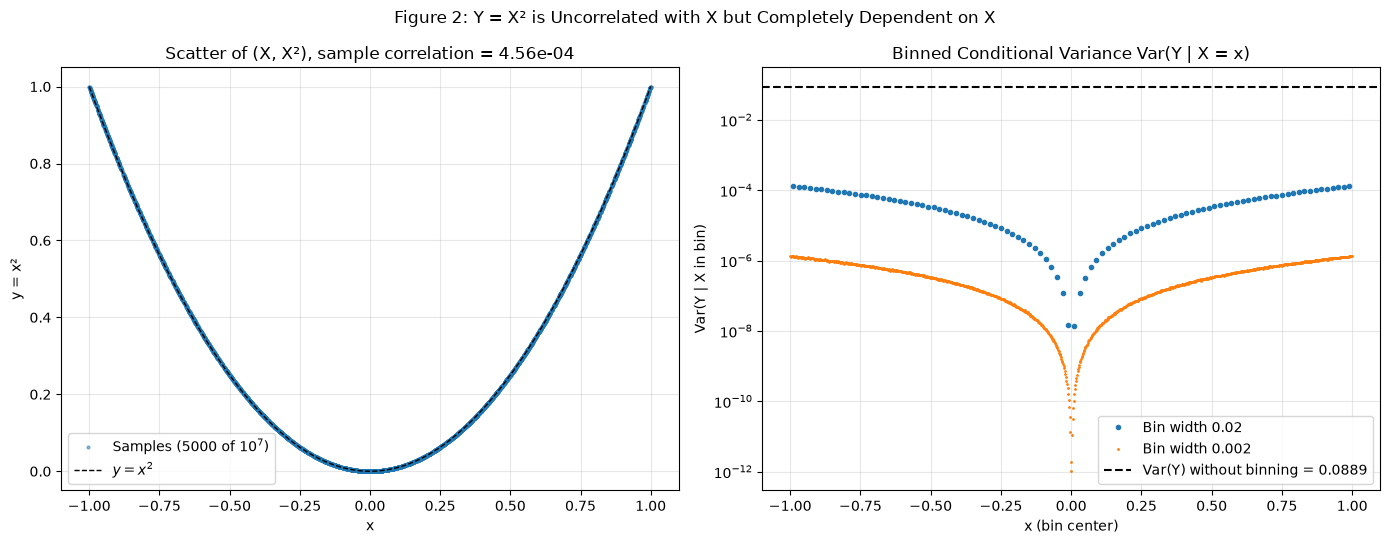

In [7]:
#Part 3: Conditional variance of Y in narrow bins of x

#Sorts the samples by x so that samples next to each other have almost the same x
order = numpy.argsort(x_step2)
x_sorted = x_step2[order]
y_sorted = y_step2[order]

#100 bins, each row holds 10^5 samples with x values next to each other (bin width about 0.02)
x_bins_100 = x_sorted.reshape(100, -1)
y_bins_100 = y_sorted.reshape(100, -1)
centers_100 = x_bins_100.mean(axis=1) #Middle of each bin
vars_100 = y_bins_100.var(axis=1) #Variance of y in each bin

#1000 bins, each row holds 10^4 samples (bin width about 0.002)
x_bins_1000 = x_sorted.reshape(1000, -1)
y_bins_1000 = y_sorted.reshape(1000, -1)
centers_1000 = x_bins_1000.mean(axis=1)
vars_1000 = y_bins_1000.var(axis=1)

#Bin with the largest variance for each bin width
k_100 = numpy.argmax(vars_100)
k_1000 = numpy.argmax(vars_1000)

#Width h of that bin (largest x minus smallest x in the bin)
h_100 = x_bins_100[k_100].max() - x_bins_100[k_100].min()
h_1000 = x_bins_1000[k_1000].max() - x_bins_1000[k_1000].min()

#Expected leftover variance x^2 h^2/3 at the center of that bin
leftover_100 = centers_100[k_100]**2 * h_100**2 / 3
leftover_1000 = centers_1000[k_1000]**2 * h_1000**2 / 3

#Standard error of a variance. A variance is an average of squared distances from the mean, so SE = s/sqrt(N) works.
y_big_100 = y_bins_100[k_100]
y_big_1000 = y_bins_1000[k_1000]
se_var_100 = numpy.std((y_big_100 - y_big_100.mean())**2) / numpy.sqrt(len(y_big_100))
se_var_1000 = numpy.std((y_big_1000 - y_big_1000.mean())**2) / numpy.sqrt(len(y_big_1000))

#Difference between the largest binned variance and the expected leftover
diff_var_100 = abs(vars_100[k_100] - leftover_100)
diff_var_1000 = abs(vars_1000[k_1000] - leftover_1000)

print("Part 3: Conditional Variance of Y in Bins of X")
print("Bin Width     Bin Center     Largest Var(Y | X in bin)     Expected x^2 h^2/3     Difference     SE             Within 3 SE")
print(f"{h_100:<14.4f}{centers_100[k_100]:<15.4f}{vars_100[k_100]:<30.3e}{leftover_100:<23.3e}{diff_var_100:<15.2e}{se_var_100:<15.2e}{diff_var_100 <= 3 * se_var_100}")
print(f"{h_1000:<14.4f}{centers_1000[k_1000]:<15.4f}{vars_1000[k_1000]:<30.3e}{leftover_1000:<23.3e}{diff_var_1000:<15.2e}{se_var_1000:<15.2e}{diff_var_1000 <= 3 * se_var_1000}")

#Figure 2: scatter of (X, X^2) and the binned conditional variance
plt.figure(figsize=(14, 5.5))

#Scatter. Only 5000 points are plotted so the graph is readable. The correlation uses all 10^7.
plt.subplot(1, 2, 1)
plt.plot(x_step2[:5000], y_step2[:5000], ".", markersize=4, alpha=0.5, label="Samples (5000 of $10^7$)")
x_curve = numpy.linspace(-1, 1, 500)
plt.plot(x_curve, x_curve**2, "black", linestyle="--", linewidth=1, label="$y = x^2$")
plt.title(f"Scatter of (X, X²), sample correlation = {rho_sim_2:.2e}")
plt.xlabel("x")
plt.ylabel("y = x²")
plt.legend()
plt.grid(alpha=0.3)

#Binned conditional variance on a log axis so the small values can be seen next to Var(Y)
plt.subplot(1, 2, 2)
plt.semilogy(centers_100, vars_100, "o", markersize=3, label="Bin width 0.02")
plt.semilogy(centers_1000, vars_1000, ".", markersize=2, label="Bin width 0.002")
plt.axhline(Var_Y_sim_2, color="black", linestyle="--", label=f"Var(Y) without binning = {Var_Y_sim_2:.4f}")
plt.title("Binned Conditional Variance Var(Y | X = x)")
plt.xlabel("x (bin center)")
plt.ylabel("Var(Y | X in bin)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3, which="both")

plt.suptitle("Figure 2: Y = X² is Uncorrelated with X but Completely Dependent on X")
plt.tight_layout()
plt.show()

### Figure 2 Explanation

    The left graph shows the scatter of (X, X²). Every sample lands on the curve y = x², so if we know X we know Y. The sample correlation was only 4.56e-04 with a standard error of 3.94e-04. This is 1.44 times 1/sqrt(N) = 3.16e-04, so it is within a few times 1/sqrt(N) of zero. All of our sample values (E[Y], Var(X), Var(Y), Cov(X,Y) and rho) were within 3 standard errors of our hand calculations.

    The right graph shows the variance of Y inside each bin of x. You will notice that it is much smaller than the variance of Y without binning, which is the dashed line. The largest binned variance was 1.312e-04 for bins of width 0.0200 and 1.367e-06 for bins of width 0.0020. The variance can't be exactly 0 because x² still changes a little inside each bin, so we compare it to the expected leftover of x²h²/3, where h is the bin width. Both bins match it within 3 standard errors. This means the variance of Y at a fixed x goes to 0 as the bins get narrower.

### What Correlation Measures

    The correlation coefficient only measures how well Y follows a straight line in X, so it misses Y = X^2 because the left side goes down and the right side goes up, and the two sides cancel out to a correlation of 0.

In [8]:
#Part 5: Jointly Gaussian pair with rho = 0

N_gauss = 10**6 #One million samples

#Jointly Gaussian pair with zero mean, variances of 1 and rho = 0
gauss_pair = rng2.multivariate_normal([0, 0], [[1, 0], [0, 1]], size=N_gauss)
g1 = gauss_pair[:, 0]
g2 = gauss_pair[:, 1]

#Bin edges that split each variable into 10 bins with 10% of the samples in each
edges_g1 = numpy.quantile(g1, numpy.linspace(0, 1, 11))
edges_g2 = numpy.quantile(g2, numpy.linspace(0, 1, 11))

#Number of samples in each of the 10 x 10 cells
counts_gauss = numpy.histogram2d(g1, g2, bins=[edges_g1, edges_g2])[0]

#Empirical joint probability of each cell
joint_gauss = counts_gauss / N_gauss

#Product of the marginals, each row and column holds 10% of the samples
product_gauss = numpy.outer(joint_gauss.sum(axis=1), joint_gauss.sum(axis=0))

#Largest difference between the joint and the product over all 100 cells
max_diff_gauss = numpy.max(numpy.abs(joint_gauss - product_gauss))

#Standard error of a cell probability of 0.01 (10% x 10%)
se_cell = numpy.sqrt(0.01 * (1 - 0.01) / N_gauss)

#Number of cells within 3 standard errors of the product
cells_within_gauss = numpy.sum(numpy.abs(joint_gauss - product_gauss) <= 3 * se_cell)

print("Part 5: Joint vs Product of Marginals, 10 x 10 cells, N = 1000000")
print("Pair                Largest Difference     Cell SE        Difference / SE     Cells Within 3 SE")
print(f"Gaussian, rho = 0   {max_diff_gauss:<23.2e}{se_cell:<15.2e}{max_diff_gauss / se_cell:<20.2f}{cells_within_gauss} of 100")

Part 5: Joint vs Product of Marginals, 10 x 10 cells, N = 1000000
Pair                Largest Difference     Cell SE        Difference / SE     Cells Within 3 SE
Gaussian, rho = 0   2.67e-04               9.95e-05       2.68                100 of 100


### Independence Results

    We split each variable into 10 bins creating 100 cells. All of the 100 cells were within 3 standard errors of the product of the marginals. We saw the largest difference of 2.67e-04 and a standard error of 9.95e-05, which tells us the Gaussian pair is independent.

### Why Uncorrelated implies Independent Only for Gaussians

    Uncorrelated means independent only for Gaussians because when the Gaussian pair has 0 correlation, the joint density splits into separate parts for X and Y, so even if we know what X is it doesn't give us the value of Y. For other distributions correlation only looks at a straight line, so Y = X^2 gets a correlation of 0 even when knowing one variable tells us the value of the other. This means that the Gaussian assumption is load bearing, because if we start treating uncorrelated noise as independent and the noise isn't Gaussian, then our results will be wrong.

## Step 3: The Covariance Matrix and How Well We Can Estimate It

**Objective:** Check that a 4 x 4 covariance matrix is valid and find out how many samples we need to estimate it.

$$\Sigma=\begin{bmatrix}4&2&1&0\\2&5&2&1\\1&2&3&1\\0&1&1&2\end{bmatrix}$$

**Process:** We will check that Sigma is symmetric and that all of its eigenvalues are 0 or larger, then test is_valid_covariance. Then we will generate samples with this covariance, estimate Sigma with sample_mean_cov from N = 10^2 to 10^6, and see how fast the error falls as N gets bigger.

In [9]:
#Step 3: The covariance matrix and how well we can estimate it

#Part 1: Valid covariance matrix

#4 x 4 covariance matrix
Sigma_3 = numpy.array([[4, 2, 1, 0],
                       [2, 5, 2, 1],
                       [1, 2, 3, 1],
                       [0, 1, 1, 2]], dtype=float)

#Symmetric: Sigma should equal its transpose, so the largest difference should be 0
sym_diff_3 = numpy.max(numpy.abs(Sigma_3 - Sigma_3.T))

#Eigenvalues. We use eigvalsh instead of eig because Sigma is symmetric, so the eigenvalues come out real.
eigenvalues_3 = numpy.linalg.eigvalsh(Sigma_3)

#Determinant of Sigma, should equal the product of the eigenvalues
det_3 = numpy.linalg.det(Sigma_3)

print("Part 1: Valid Covariance Matrix")
print(f"Largest |Sigma - Sigma^T|:  {sym_diff_3:.1f}")
print(f"Eigenvalues:                {eigenvalues_3[0]:.4f}, {eigenvalues_3[1]:.4f}, {eigenvalues_3[2]:.4f}, {eigenvalues_3[3]:.4f}")
print(f"Determinant:                {det_3:.4f}")

#Non symmetric matrix: Sigma with the top right entry changed from 0 to 1, the bottom left entry stays 0
non_symmetric_3 = Sigma_3.copy()
non_symmetric_3[0, 3] = 1

#Symmetric matrix with a negative eigenvalue: [[1, 2], [2, 1]] has eigenvalues 3 and -1
negative_eig_3 = numpy.array([[1, 2], [2, 1]], dtype=float)

#Tests is_valid_covariance on all three matrices
valid_sigma_3 = func.is_valid_covariance(Sigma_3)
valid_non_symmetric_3 = func.is_valid_covariance(non_symmetric_3)
valid_negative_eig_3 = func.is_valid_covariance(negative_eig_3)

print("\nis_valid_covariance Test")
print("Matrix                        Smallest Eigenvalue     Valid")
print(f"Sigma:                        {eigenvalues_3.min():<24.4f}{valid_sigma_3}")
print(f"Non symmetric:                {'not symmetric':<24}{valid_non_symmetric_3}")
print(f"Symmetric [[1, 2], [2, 1]]:   {numpy.linalg.eigvalsh(negative_eig_3).min():<24.4f}{valid_negative_eig_3}")

Part 1: Valid Covariance Matrix
Largest |Sigma - Sigma^T|:  0.0
Eigenvalues:                1.2649, 1.7882, 3.0981, 7.8488
Determinant:                55.0000

is_valid_covariance Test
Matrix                        Smallest Eigenvalue     Valid
Sigma:                        1.2649                  True
Non symmetric:                not symmetric           False
Symmetric [[1, 2], [2, 1]]:   -1.0000                 False


Frobenius Norm of Sigma_hat - Sigma
N          Reps   Single Draw    Averaged       SE of Average  Expected   Difference     sqrt(N) x Single   sqrt(N) x Averaged
100        200    1.4018         1.5711         0.0364         1.56       0.0111         14.02              15.71
1000       200    0.6774         0.5114         0.0127         0.49       0.0214         21.42              16.17
10000      100    0.1357         0.1499         0.0044         0.16       0.0101         13.57              14.99
100000     30     0.0466         0.0501         0.0029         0.046      0.0041         14.75              15.86
1000000    10     0.0214         0.0168         0.0013         0.016      0.0008         21.42              16.81

Averaged error drop each time N is 10 times bigger: 3.07, 3.41, 2.99, 2.98   sqrt(10) = 3.16

N          sqrt(N) x Averaged   Difference from 15   SE
100        15.71                0.71                 0.36
1000       16.17                1.17                 0.40


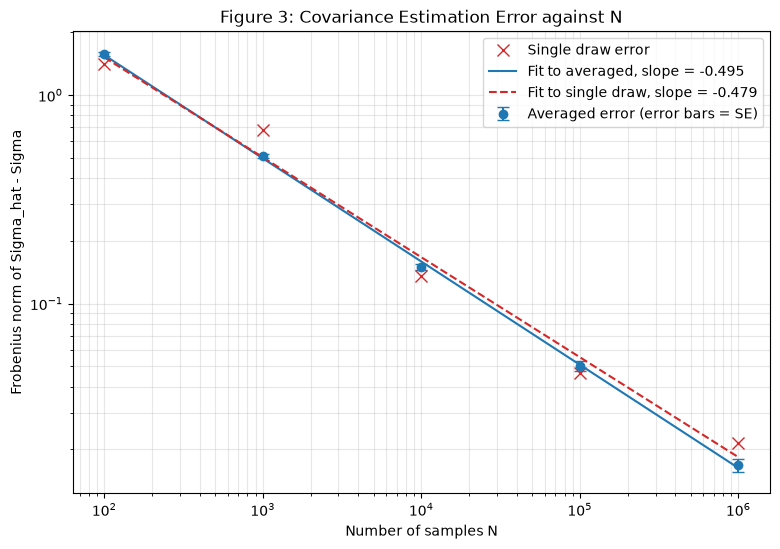

In [10]:
#Parts 2 to 4: Estimation error against N

#Sample sizes and the number of repetitions at each one
N_list_3 = numpy.array([10**2, 10**3, 10**4, 10**5, 10**6])
reps_3 = numpy.array([200, 200, 100, 30, 10])

#Zero mean for the samples
mu_3 = numpy.zeros(4)

#Expected averaged errors
expected_3 = numpy.array([1.56, 0.49, 0.16, 0.046, 0.016])

#Arrays to hold the results at each N
single_error_3 = numpy.zeros(5) #Error of the first repetition (single draw)
average_error_3 = numpy.zeros(5) #Average error over all repetitions
se_error_3 = numpy.zeros(5) #Standard error of the average

#Repeats the estimate at each N and saves the Frobenius norm of Sigma_hat - Sigma each time
for k in range(5):
    errors = numpy.zeros(reps_3[k])
    for r in range(reps_3[k]):
        #Generates N samples with covariance Sigma
        X_3 = rng3.multivariate_normal(mu_3, Sigma_3, size=N_list_3[k])
        #Estimates Sigma with our function
        Sigma_hat_3 = func.sample_mean_cov(X_3)[1]
        #Frobenius norm of the difference
        errors[r] = numpy.linalg.norm(Sigma_hat_3 - Sigma_3, "fro")
    single_error_3[k] = errors[0]
    average_error_3[k] = errors.mean()
    se_error_3[k] = errors.std(ddof=1) / numpy.sqrt(reps_3[k])

#Difference between the averaged and expected errors
diff_3 = numpy.abs(average_error_3 - expected_3)

#sqrt(N) x error should stay the same if the error falls like 1/sqrt(N)
sqrtN_single_3 = numpy.sqrt(N_list_3) * single_error_3
sqrtN_average_3 = numpy.sqrt(N_list_3) * average_error_3

print("Frobenius Norm of Sigma_hat - Sigma")
print("N          Reps   Single Draw    Averaged       SE of Average  Expected   Difference     sqrt(N) x Single   sqrt(N) x Averaged")
for k in range(5):
    print(f"{N_list_3[k]:<11}{reps_3[k]:<7}{single_error_3[k]:<15.4f}{average_error_3[k]:<15.4f}{se_error_3[k]:<15.4f}{expected_3[k]:<11}{diff_3[k]:<15.4f}{sqrtN_single_3[k]:<19.2f}{sqrtN_average_3[k]:.2f}")

#How much the averaged error drops each time N is 10 times bigger, should be about sqrt(10)
drop_3 = average_error_3[:-1] / average_error_3[1:]
print(f"\nAveraged error drop each time N is 10 times bigger: {drop_3[0]:.2f}, {drop_3[1]:.2f}, {drop_3[2]:.2f}, {drop_3[3]:.2f}   sqrt(10) = {numpy.sqrt(10):.2f}")

#Difference from 15 and standard error of sqrt(N) x averaged error at each N
diff_15_3 = numpy.abs(sqrtN_average_3 - 15)
se_sqrtN_3 = numpy.sqrt(N_list_3) * se_error_3
print("\nN          sqrt(N) x Averaged   Difference from 15   SE")
for k in range(5):
    print(f"{N_list_3[k]:<11}{sqrtN_average_3[k]:<21.2f}{diff_15_3[k]:<21.2f}{se_sqrtN_3[k]:.2f}")

#Range and mean of sqrt(N) x error, the averaged one should stay near 15 (within about 10%)
mean_sqrtN_average_3 = sqrtN_average_3.mean()
mean_sqrtN_single_3 = sqrtN_single_3.mean()
print("\n                             Lowest    Highest   Mean      Mean Difference from 15")
print(f"sqrt(N) x averaged error:    {sqrtN_average_3.min():<10.2f}{sqrtN_average_3.max():<10.2f}{mean_sqrtN_average_3:<10.2f}{100 * abs(mean_sqrtN_average_3 / 15 - 1):.1f}%")
print(f"sqrt(N) x single draw error: {sqrtN_single_3.min():<10.2f}{sqrtN_single_3.max():<10.2f}{mean_sqrtN_single_3:<10.2f}{100 * abs(mean_sqrtN_single_3 / 15 - 1):.1f}%")

#Straight line fit of log10(error) against log10(N), the slope is the rate
#cov=True also gives the standard error of the slope
log_N_3 = numpy.log10(N_list_3)
fit_average_3, fit_cov_average_3 = numpy.polyfit(log_N_3, numpy.log10(average_error_3), 1, cov=True)
fit_single_3, fit_cov_single_3 = numpy.polyfit(log_N_3, numpy.log10(single_error_3), 1, cov=True)
slope_average_3 = fit_average_3[0]
slope_single_3 = fit_single_3[0]
slope_se_average_3 = numpy.sqrt(fit_cov_average_3[0, 0])
slope_se_single_3 = numpy.sqrt(fit_cov_single_3[0, 0])

print("\nFitted Slopes          Slope       Standard Error     Difference from -0.5")
print(f"Averaged:              {slope_average_3:<12.4f}{slope_se_average_3:<19.4f}{abs(slope_average_3 + 0.5):.4f}")
print(f"Single draw:           {slope_single_3:<12.4f}{slope_se_single_3:<19.4f}{abs(slope_single_3 + 0.5):.4f}")

#Figure 3: estimation error against N on log scales
plt.figure(figsize=(9, 6))
N_line_3 = numpy.logspace(2, 6, 100)
plt.errorbar(N_list_3, average_error_3, yerr=se_error_3, fmt="o", color="tab:blue", capsize=4, label="Averaged error (error bars = SE)")
plt.plot(N_list_3, single_error_3, "x", color="tab:red", markersize=9, label="Single draw error")
plt.plot(N_line_3, 10**fit_average_3[1] * N_line_3**slope_average_3, color="tab:blue", label=f"Fit to averaged, slope = {slope_average_3:.3f}")
plt.plot(N_line_3, 10**fit_single_3[1] * N_line_3**slope_single_3, "--", color="tab:red", label=f"Fit to single draw, slope = {slope_single_3:.3f}")
plt.xscale("log")
plt.yscale("log")
plt.title("Figure 3: Covariance Estimation Error against N")
plt.xlabel("Number of samples N")
plt.ylabel("Frobenius norm of Sigma_hat - Sigma")
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.show()

### Figure 3 Explanation
The graph shows covaraicne estimation error against N. It is put in log scale for both axes so taht we could see the data more clear. You will notice that the averaged errors (in blue) fall on a straight line. The averaged errors were 1.5711, 0.5114, 0.1499, 0.0501 and 0.0168, which are close to the expected 1.56, 0.49, 0.16, 0.046 and 0.016. The largest difference from our results is 0.0214. The fitted slop is -0.495 with a standard error of 0.006 which is 0.005 difference from -0.5. This means the error falls like 1/sqrt(N), so it gets about 3.16 times smaller every time N is 10 times bigger. (Our results showed 3.07, 3.41, 2.99 and 2.98).

Multiplying the averaged errors by sqrt(N) gives us values between 14.99 and 16.81 with a mean of 15.91, so the product stays roughly constant. The percent different is 6.1% from the exptected at 15. The highest value is 16.81 at N = 1 million, is a bit more than 10% above 15 but the difference is within 3 standard errors (SE = 1.26). The single draw errors are depicted in red with 1.4018, 0.6774, 0.1357, 0.0466 and 0.0214, and their sqrt(N) times error moved around between 13.57 and 21.42. The single draw slope was -0.4794 with a standard error of 0.0346.The single draw curve is not good enough to fit a slope to because each point is one random try so a bad point can move the slope off course.

In [11]:
#Part 5: Free parameters and samples needed in 100 dimensions

#Number of free parameters d(d + 1)/2
p_4 = 4 * (4 + 1) // 2
p_100 = 100 * (100 + 1) // 2

#Relative accuracy at N = 10^4 in four dimensions (averaged error divided by the size of Sigma)
relative_error_3 = average_error_3[2] / numpy.linalg.norm(Sigma_3, "fro")

#Samples needed with our measured slope from Figure 3
N_needed_3 = 10**4 * (p_100 / p_4) ** (1 / (2 * abs(slope_average_3)))

print("Part 5: Free Parameters")
print(f"d = 4:     {p_4}")
print(f"d = 100:   {p_100}")
print(f"\nRelative accuracy at N = 10^4 (d = 4): {relative_error_3:.4f}")
print(f"Free parameter ratio:                  {p_100 / p_4:.0f}")
print(f"\nSamples needed for d = 100, measured slope of {slope_average_3:.4f}: {N_needed_3:.0f}")

Part 5: Free Parameters
d = 4:     10
d = 100:   5050

Relative accuracy at N = 10^4 (d = 4): 0.0172
Free parameter ratio:                  505

Samples needed for d = 100, measured slope of -0.4950: 5379947


### Why This Is a Problem for a Radar

    A radar with 100 array elements would need roughly 5379947 samples to estimate its covariance as well as we did in four dimensions, but the targets and noise around the radar change long before it can collect that many. A designer can add a small amount to the diagonal of the estimated covariance, which keeps the estimate usable with far fewer samples.

## Step 4: Linear Transformations of Random Vectors

**Objective:** Derive how the mean and covariance change under $\mathbf{y}=A\mathbf{x}+\mathbf{b}$, and see what happens when the output covariance is singular.

**Process:** In order to accomplish this objective we will start with a random varible and then use our computed values of $\mu_y$ and $\Sigma_y$ by hand for a $3\times2$ matrix $A$, and check them using a million samples. Then we will look at the rank of $\Sigma_y$, repeat with a rank deficient $2\times2$ matrix, and show that a singular covariance breaks the Gaussian density. 

### The Two Transformation Rules

Mean, using linearity of expectation:

$$\boldsymbol\mu_y=E[A\mathbf{x}+\mathbf{b}]=A\,E[\mathbf{x}]+\mathbf{b}=A\boldsymbol\mu_x+\mathbf{b}$$

Covariance, $\mathbf{b}$ cancels because $\mathbf{y}-\boldsymbol\mu_y=A\mathbf{x}+\mathbf{b}-A\boldsymbol\mu_x-\mathbf{b}=A(\mathbf{x}-\boldsymbol\mu_x)$:

$$\Sigma_y=E\left[(\mathbf{y}-\boldsymbol\mu_y)(\mathbf{y}-\boldsymbol\mu_y)^T\right]=E\left[A(\mathbf{x}-\boldsymbol\mu_x)(\mathbf{x}-\boldsymbol\mu_x)^TA^T\right]$$

$$=A\,E\left[(\mathbf{x}-\boldsymbol\mu_x)(\mathbf{x}-\boldsymbol\mu_x)^T\right]A^T$$

$$\Sigma_y=A\Sigma_xA^T$$

### By Hand

$$\boldsymbol\mu_x=\begin{bmatrix}1\\-2\end{bmatrix} \qquad \Sigma_x=\begin{bmatrix}4&2\\2&4\end{bmatrix} \qquad A=\begin{bmatrix}1&2\\0&1\\1&-1\end{bmatrix}$$

Mean:

$$\boldsymbol\mu_y=A\boldsymbol\mu_x=\begin{bmatrix}1(1)+2(-2)\\0(1)+1(-2)\\1(1)-1(-2)\end{bmatrix}=\begin{bmatrix}-3\\-2\\3\end{bmatrix}$$

Covariance, first $A\Sigma_x$:

$$A\Sigma_x=\begin{bmatrix}1(4)+2(2)&1(2)+2(4)\\0(4)+1(2)&0(2)+1(4)\\1(4)-1(2)&1(2)-1(4)\end{bmatrix}=\begin{bmatrix}8&10\\2&4\\2&-2\end{bmatrix}$$

Then multiply by $A^T=\begin{bmatrix}1&0&1\\2&1&-1\end{bmatrix}$:

$$\Sigma_y=\begin{bmatrix}8+20&0+10&8-10\\2+8&0+4&2-4\\2-4&0-2&2+2\end{bmatrix}=\begin{bmatrix}28&10&-2\\10&4&-2\\-2&-2&4\end{bmatrix}$$

Determinant:

$$\det\Sigma_y=28(16-4)-10(40-4)+(-2)(-20+8)=336-360+24=0$$

### Standard Errors

Each entry of $\boldsymbol\mu_y$ is a sample mean, so $SE=s/\sqrt{N}$. Each entry of $\hat\Sigma_y$ is a sample mean of $(y_i-\bar y_i)(y_j-\bar y_j)$, so its standard error is the standard deviation of that product divided by $\sqrt{N}$, the same method as Steps 1 and 2.

In [12]:
#Step 4: Linear transformations of random vectors

N_4 = 10**6 #One million samples

mu_x_4 =    numpy.array([1, -2], dtype=float)
Sigma_x_4 = numpy.array([[4, 2], [2, 4]], dtype=float)
A_4 = numpy.array([[1, 2], [0, 1], [1, -1]], dtype=float)

#Hand calculated values
mu_y_exact_4 = numpy.array([-3, -2, 3], dtype=float)
Sigma_y_exact_4 = numpy.array([[28, 10, -2], [10, 4, -2], [-2, -2, 4]], dtype=float)

#The same values from the transformation rules
assert numpy.allclose(A_4 @ mu_x_4, mu_y_exact_4)
assert numpy.allclose(A_4 @ Sigma_x_4 @ A_4.T, Sigma_y_exact_4)

#Compares the sample mean and covariance of y against the exact values, with standard errors
def compare_mean_cov(y, mu_exact, Sigma_exact):
    N = y.shape[0]
    d = y.shape[1]
    mean_sim, cov_sim = func.sample_mean_cov(y)
    se_mean = numpy.std(y, axis=0) / numpy.sqrt(N)

    #Products (y_i - mean_i)(y_j - mean_j) for every pair (i, j), shaped (N, d, d)
    middle = y - mean_sim
    products = middle[:, :, None] * middle[:, None, :]
    se_cov = numpy.std(products, axis=0) / numpy.sqrt(N)

    print("Entry        Exact          Sample         Difference     SE             Within 3 SE")
    for i in range(d):
        diff = abs(mean_sim[i] - mu_exact[i])
        print(f"mu[{i}]:       {mu_exact[i]:<15.4f}{mean_sim[i]:<15.4f}{diff:<15.4f}{se_mean[i]:<15.4f}{diff <= 3 * se_mean[i]}")
    for i in range(d):
        for j in range(i, d):
            diff = abs(cov_sim[i, j] - Sigma_exact[i, j])
            print(f"Sigma[{i},{j}]:  {Sigma_exact[i, j]:<15.4f}{cov_sim[i, j]:<15.4f}{diff:<15.4f}{se_cov[i, j]:<15.4f}{diff <= 3 * se_cov[i, j]}")

    #Largest difference measured in standard errors
    z_mean = numpy.abs(mean_sim - mu_exact) / se_mean #compares our simulated resutls with theory for the z
    z_cov = numpy.abs(cov_sim - Sigma_exact) / se_cov #same as the above function but for covariance matrix
    print(f"Largest |difference| / SE: mean = {z_mean.max():.2f}, covariance = {z_cov.max():.2f}")
    return mean_sim, cov_sim

#Part 2: Simulate x and apply y = A x 
x_4 = rng4.multivariate_normal(mu_x_4, Sigma_x_4, size=N_4)
y_4 = x_4 @ A_4.T

print(f"Part 2: y = A x, N = {N_4}")
mean_y_4, cov_y_4 = compare_mean_cov(y_4, mu_y_exact_4, Sigma_y_exact_4)

#Part 3: Rank of Sigma_y
print("\nPart 3: Rank of Sigma_y")
print(f"Rank of exact Sigma_y:          {numpy.linalg.matrix_rank(Sigma_y_exact_4)}")
print(f"Rank of sample Sigma_y:         {numpy.linalg.matrix_rank(cov_y_4)}")
print(f"Eigenvalues of exact Sigma_y:   {numpy.round(numpy.linalg.eigvalsh(Sigma_y_exact_4), 4)}")
print(f"Eigenvalues of sample Sigma_y:  {numpy.round(numpy.linalg.eigvalsh(cov_y_4), 4)}")

#n = [1, -3, -1] solves A^T n = 0, so n . y = n . A x = 0 for every sample
normal_4 = numpy.array([1, -3, -1], dtype=float)
print(f"\nA^T n for n = [1, -3, -1]:      {A_4.T @ normal_4}")
print(f"Largest |n . y| over all samples: {numpy.max(numpy.abs(y_4 @ normal_4)):.2e}")
print(f"Largest |y| over all samples:     {numpy.max(numpy.abs(y_4)):.2f}")

Part 2: y = A x, N = 1000000
Entry        Exact          Sample         Difference     SE             Within 3 SE
mu[0]:       -3.0000        -3.0002        0.0002         0.0053         True
mu[1]:       -2.0000        -1.9992        0.0008         0.0020         True
mu[2]:       3.0000         2.9973         0.0027         0.0020         True
Sigma[0,0]:  28.0000        27.9430        0.0570         0.0396         True
Sigma[0,1]:  10.0000        9.9879         0.0121         0.0146         True
Sigma[0,2]:  -2.0000        -2.0207        0.0207         0.0108         True
Sigma[1,1]:  4.0000         3.9988         0.0012         0.0057         True
Sigma[1,2]:  -2.0000        -2.0084        0.0084         0.0045         True
Sigma[2,2]:  4.0000         4.0045         0.0045         0.0057         True
Largest |difference| / SE: mean = 1.36, covariance = 1.92

Part 3: Rank of Sigma_y
Rank of exact Sigma_y:          2
Rank of sample Sigma_y:         2
Eigenvalues of exact Sigma_y:   [

### Simulation Results

    All 3 entries of the sample mean and all 6 unique entries of the sample covariance were within 3 standard errors of the hand values mu_y = [-3, -2, 3] and Sigma_y = [[28, 10, -2], [10, 4, -2], [-2, -2, 4]]. The largest |difference| / SE was 1.36 for the mean and 1.92 for the covariance, so the transformation rules are confirmed.

### Rank of Sigma_y

    Sigma_y has rank 2 (eigenvalues 0, 4.1436 and 31.8564) because y = A x is built from only the 2 random numbers in x, so the rank of A Sigma_x A^T can be no larger than the rank of A, which is 2. Geometrically, every sample of y lives on a plane through the origin in 3D, the column space of A, which is the plane y1 - 3 y2 - y3 = 0. The largest |n . y| over all samples was at rounding level (below 1e-13) while the samples reach values as large as 28.56, so the samples sit on that plane up to rounding error.

### Rank Deficient A

$$A=\begin{bmatrix}1&1\\2&2\end{bmatrix}$$

Mean:

$$\boldsymbol\mu_y=\begin{bmatrix}1-2\\2-4\end{bmatrix}=\begin{bmatrix}-1\\-2\end{bmatrix}$$

Covariance:

$$A\Sigma_x=\begin{bmatrix}4+2&2+4\\8+4&4+8\end{bmatrix}=\begin{bmatrix}6&6\\12&12\end{bmatrix}$$

$$\Sigma_y=A\Sigma_xA^T=\begin{bmatrix}6&6\\12&12\end{bmatrix}\begin{bmatrix}1&2\\1&2\end{bmatrix}=\begin{bmatrix}12&24\\24&48\end{bmatrix}$$

$$\det\Sigma_y=12(48)-24(24)=576-576=0$$

The second row of $A$ is 2 times the first, so $y_2=2(x_1+x_2)=2y_1$ for every sample. The outputs lie on the line $y_2=2y_1$ through the origin, which also passes through $\boldsymbol\mu_y=[-1,-2]^T$.

Part 4: y = A x with rank deficient A, N = 1000000
Entry        Exact          Sample         Difference     SE             Within 3 SE
mu[0]:       -1.0000        -1.0010        0.0010         0.0035         True
mu[1]:       -2.0000        -2.0020        0.0020         0.0069         True
Sigma[0,0]:  12.0000        11.9660        0.0340         0.0169         True
Sigma[0,1]:  24.0000        23.9320        0.0680         0.0339         True
Sigma[1,1]:  48.0000        47.8639        0.1361         0.0678         True
Largest |difference| / SE: mean = 0.29, covariance = 2.01

Rank of exact Sigma_y:            1
Rank of sample Sigma_y:           1
Eigenvalues of exact Sigma_y:     [ 0. 60.]
Largest |y2 - 2 y1| over samples: 0.00e+00

Part 5: Determinant of the Singular Covariances
Matrix                    det              det / product of diagonal
Exact 3 x 3 Sigma_y       4.87e-14         1.09e-16
Sample 3 x 3 Sigma_y      -2.44e-12        -5.45e-15
Exact 2 x 2 Sigma_y       0.00e+0

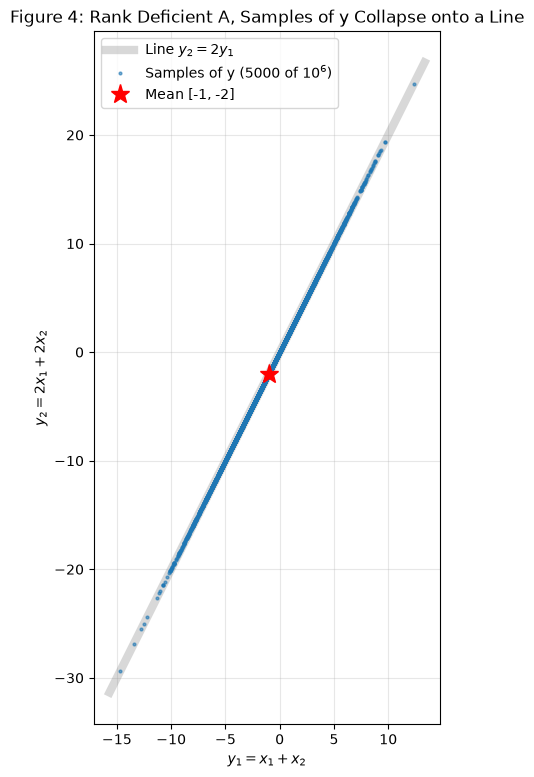

In [13]:
#Part 4: Rank deficient A

A2_4 = numpy.array([[1, 1], [2, 2]], dtype=float)
mu_y2_exact_4 = numpy.array([-1, -2], dtype=float)
Sigma_y2_exact_4 = numpy.array([[12, 24], [24, 48]], dtype=float)
assert numpy.allclose(A2_4 @ mu_x_4, mu_y2_exact_4)
assert numpy.allclose(A2_4 @ Sigma_x_4 @ A2_4.T, Sigma_y2_exact_4)

#Same x samples as Part 2
y2_4 = x_4 @ A2_4.T

print(f"Part 4: y = A x with rank deficient A, N = {N_4}")
mean_y2_4, cov_y2_4 = compare_mean_cov(y2_4, mu_y2_exact_4, Sigma_y2_exact_4)
print(f"\nRank of exact Sigma_y:            {numpy.linalg.matrix_rank(Sigma_y2_exact_4)}")
print(f"Rank of sample Sigma_y:           {numpy.linalg.matrix_rank(cov_y2_4)}")
print(f"Eigenvalues of exact Sigma_y:     {numpy.round(numpy.linalg.eigvalsh(Sigma_y2_exact_4), 4)}")
print(f"Largest |y2 - 2 y1| over samples: {numpy.max(numpy.abs(y2_4[:, 1] - 2 * y2_4[:, 0])):.2e}")

#Part 5: A singular covariance breaks the Gaussian density
#det / (product of the diagonal) is 1 for uncorrelated variables and 0 for a singular matrix, so it shows the size of det on a fair scale
print("\nPart 5: Determinant of the Singular Covariances")
print("Matrix                    det              det / product of diagonal")
for name, S in [("Exact 3 x 3 Sigma_y", Sigma_y_exact_4), ("Sample 3 x 3 Sigma_y", cov_y_4),
                ("Exact 2 x 2 Sigma_y", Sigma_y2_exact_4), ("Sample 2 x 2 Sigma_y", cov_y2_4)]:
    det_S = numpy.linalg.det(S)
    print(f"{name:<26}{det_S:<17.2e}{det_S / numpy.prod(numpy.diag(S)):.2e}")

#Try to evaluate our Gaussian density at the mean with the singular covariance
print("\nEvaluating gaussian_pdf at the mean with the exact singular Sigma_y:")
for name, mu_S, S in [("2 x 2", mu_y2_exact_4, Sigma_y2_exact_4), ("3 x 3", mu_y_exact_4, Sigma_y_exact_4)]:
    try:
        value = func.gaussian_pdf(mu_S, mu_S, S)
        print(f"{name}: returned {value:.3e}")
    except (ValueError, numpy.linalg.LinAlgError) as error:
        print(f"{name}: {type(error).__name__}: {error}")

#Figure 4: rank deficient output samples and the line they lie on
plt.figure(figsize=(6, 9))
y1_line_4 = numpy.linspace(y2_4[:5000, 0].min() - 1, y2_4[:5000, 0].max() + 1, 100)
plt.plot(y1_line_4, 2 * y1_line_4, color="gray", linewidth=6, alpha=0.3, label="Line $y_2 = 2y_1$")
plt.plot(y2_4[:5000, 0], y2_4[:5000, 1], ".", color="tab:blue", markersize=4, alpha=0.6, label="Samples of y (5000 of $10^6$)")
plt.plot(mu_y2_exact_4[0], mu_y2_exact_4[1], "r*", markersize=14, label="Mean [-1, -2]")
plt.gca().set_aspect("equal")
plt.title("Figure 4: Rank Deficient A, Samples of y Collapse onto a Line")
plt.xlabel("$y_1 = x_1 + x_2$")
plt.ylabel("$y_2 = 2x_1 + 2x_2$")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.show()

### Figure 4 Explanation
    This figure confirms our simulation agaisnt the exact values we expct to get with 1 million trials we do have some diffrence because our random simulations have sampling error. This difference in our covarience is given by the number 2.01 which is about 2 standard erros from the exact value whihc is accepatable because it is within 3 standard errors. While the number .29 is the difference for our mean values which is well within our values so we can confirm that simulation agrees with theory. We can see that this figure only displays 5000 of our 1,000,000 samples and that the ones it does display fit well within our y2 = 2 y1. This line passes thorugh the orgin and our mean [1, 2]. We can see that this datat becomes a line so the ordinary gaussian formula breaks. From our function to get the determinate we can see we got a zero which means our data has collasped into fewer dimension. Dispite the fact er got a small value for the 3x3 determinate the number is so small we can say that it is insignficant and becomes zero.The negative number and very small positive number for our 3x3 can be attributed to the floating point roundoff. 

## Step 5: The Multivariate Gaussian

**Objective:** Build the multivariate Gaussian density ourselves and learn to read its contours.

$$\boldsymbol\mu=\mathbf{0} \qquad \Sigma=\begin{bmatrix}4&2\\2&4\end{bmatrix}$$

**Process:** We will write out the density, check `gaussian_pdf` against scipy, integrate it over a large region, then plot the contours that hold 50%, 90% and 99% of the probability over $10^4$ samples and count how many samples fall inside each. Finally we sweep $\rho$ from 0 to 0.99.

### The Density

$$f(\mathbf{x})=\frac{1}{(2\pi)^{d/2}\,|\Sigma|^{1/2}}\exp\!\left(-\frac{1}{2}(\mathbf{x}-\boldsymbol\mu)^T\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu)\right)$$

- $\mathbf{x}$ = the point where the density is evaluated, a $d\times1$ vector
- $\boldsymbol\mu$ = mean vector, the center of the density
- $\Sigma$ = covariance matrix, sets the size, shape and tilt of the contours
- $d$ = dimension, here $d=2$
- $|\Sigma|$ = determinant of $\Sigma$, the squared volume scale of the spread
- $(2\pi)^{d/2}|\Sigma|^{1/2}$ = normalizing constant that makes the density integrate to 1
- $r^2=(\mathbf{x}-\boldsymbol\mu)^T\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu)$ = squared Mahalanobis distance, the distance from the mean measured in units of the spread in each direction

`gaussian_pdf` finds $\mathbf{z}=\Sigma^{-1}(\mathbf{x}-\boldsymbol\mu)$ by solving $\Sigma\mathbf{z}=\mathbf{x}-\boldsymbol\mu$ with `numpy.linalg.solve`, which is faster and more accurate than forming $\Sigma^{-1}$, and then $r^2=(\mathbf{x}-\boldsymbol\mu)^T\mathbf{z}$.

By hand for this $\Sigma$:

$$|\Sigma|=4(4)-2(2)=12 \qquad \Sigma^{-1}=\frac{1}{12}\begin{bmatrix}4&-2\\-2&4\end{bmatrix} \qquad \rho=\frac{\sigma_{12}}{\sigma_1\sigma_2}=\frac{2}{\sqrt{4\cdot4}}=0.5$$

$$f(x_1,x_2)=\frac{1}{2\pi\sqrt{12}}\exp\!\left(-\frac{4x_1^2-4x_1x_2+4x_2^2}{24}\right)=\frac{1}{4\pi\sqrt{3}}\exp\!\left(-\frac{x_1^2-x_1x_2+x_2^2}{6}\right)$$

In [14]:
#Step 5: The multivariate Gaussian

mu_5 = numpy.zeros(2)  #creates a vector 2x1 of zeros

Sigma_5 = numpy.array([[4, 2], [2, 4]], dtype=float)

det_5 = numpy.linalg.det(Sigma_5) #gets the determinate of sigma 5

#Compare gaussian_pdf with scipy at five scattered points
points_5 = numpy.array([[0, 0], [1, -2], [3, 3], [-4, 1], [2.5, -5]], dtype=float)
pdf_ours_5 = func.gaussian_pdf(points_5, mu_5, Sigma_5)
pdf_scipy_5 = scipy.stats.multivariate_normal.pdf(points_5, mean=mu_5, cov=Sigma_5)
rel_diff_5 = numpy.abs(pdf_ours_5 - pdf_scipy_5) / pdf_scipy_5

print("Part 1: gaussian_pdf vs scipy.stats.multivariate_normal.pdf")
print("Point            Ours               Scipy              Relative Difference")
for i in range(len(points_5)):
    print(f"{str(points_5[i]):<17}{pdf_ours_5[i]:<19.10e}{pdf_scipy_5[i]:<19.10e}{rel_diff_5[i]:.2e}")
print(f"Largest relative difference: {rel_diff_5.max():.2e}")
print(f"\ndet(Sigma) = {det_5:.6f}   f(0, 0) = 1/(2 pi sqrt(12)) = {1 / (2 * numpy.pi * numpy.sqrt(12)):.10f}")

#Part 2: Integrate the density over a large square
#The ellipse r^2 = c extends r * sigma = 2r along each axis, so the square [-15, 15]^2 holds the ellipse with r = 7.5
#and the probability left outside the square is less than exp(-7.5^2/2)

L_5 = 15
grid_5 = numpy.linspace(-L_5, L_5, 1201)
G1_5, G2_5 = numpy.meshgrid(grid_5, grid_5, indexing="ij")
grid_points_5 = numpy.column_stack([G1_5.ravel(), G2_5.ravel()])
pdf_grid_5 = func.gaussian_pdf(grid_points_5, mu_5, Sigma_5).reshape(G1_5.shape)
integral_5 = scipy.integrate.simpson(scipy.integrate.simpson(pdf_grid_5, x=grid_5, axis=1), x=grid_5)
r_box_5 = L_5 / numpy.sqrt(Sigma_5[0, 0])

print("\nPart 2: Integral of the Density")
print(f"Region: [-{L_5}, {L_5}] x [-{L_5}, {L_5}], 1201 x 1201 grid, Simpson's rule")
print(f"Mahalanobis radius held by the square: {r_box_5:.2f}")
print(f"Upper bound on probability outside:    {numpy.exp(-r_box_5**2 / 2):.2e}")
print(f"Integral:                              {integral_5:.12f}")
print(f"Difference from 1:                     {abs(integral_5 - 1):.2e}")

Part 1: gaussian_pdf vs scipy.stats.multivariate_normal.pdf
Point            Ours               Scipy              Relative Difference
[0. 0.]          4.5944074618e-02   4.5944074618e-02   1.51e-16
[ 1. -2.]        1.4307132956e-02   1.4307132956e-02   2.42e-16
[3. 3.]          1.0251508727e-02   1.0251508727e-02   3.38e-16
[-4.  1.]        1.3873908372e-03   1.3873908372e-03   3.13e-16
[ 2.5 -5. ]      3.1296726268e-05   3.1296726268e-05   2.17e-15
Largest relative difference: 2.17e-15

det(Sigma) = 12.000000   f(0, 0) = 1/(2 pi sqrt(12)) = 0.0459440746

Part 2: Integral of the Density
Region: [-15, 15] x [-15, 15], 1201 x 1201 grid, Simpson's rule
Mahalanobis radius held by the square: 7.50
Upper bound on probability outside:    6.10e-13
Integral:                              1.000000000000
Difference from 1:                     1.28e-13


### Finding the Contour Levels

A contour of constant density is a set where $r^2$ is constant, so it is an ellipse. For a $d=2$ Gaussian, $r^2$ is a chi square random variable with 2 degrees of freedom, which has the CDF

$$P(r^2\leq k)=1-e^{-k/2}$$

Setting this equal to the probability $p$ we want inside the contour:

$$1-e^{-k/2}=p \;\Rightarrow\; k=-2\ln(1-p)$$

$$p=0.5:\;k=1.3863 \qquad p=0.9:\;k=4.6052 \qquad p=0.99:\;k=9.2103$$

The density on that contour is

$$f_k=\frac{1}{2\pi|\Sigma|^{1/2}}e^{-k/2}$$

which is the level we pass to `contour`. We check the fraction inside by counting the samples with $r^2\leq k$, and the standard error of that fraction is $\sqrt{p(1-p)/N}$.

### Ellipse Axes

With $\Sigma=V\Lambda V^T$, the contour $r^2=k$ is an ellipse whose axes point along the eigenvectors, with semi axis lengths $\sqrt{k\lambda_i}$.

Part 3: Probability Contours, N = 10000
Contour    k = -2 ln(1 - p)    chi2 ppf      Density Level    Fraction Inside    Difference    SE         Within 3 SE
50%       1.3863              1.3863        0.022972         0.5028             0.0028        0.0050     True
90%       4.6052              4.6052        0.004594         0.9024             0.0024        0.0030     True
99%       9.2103              9.2103        0.000459         0.9902             0.0002        0.0010     True

Part 4: Correlation and Ellipse Axes
rho = 0.5000   det(Sigma) = 12.0000
Eigenvalue 2.0000   eigenvector [-0.7071  0.7071]   direction 135.0 degrees
Eigenvalue 6.0000   eigenvector [0.7071 0.7071]   direction 45.0 degrees

Contour             Semi Axis along Eigenvalue 2     Semi Axis along Eigenvalue 6
r^2 = 1 (1 sigma)   1.4142                           2.4495
50%                 1.6651                           2.8841
90%                 3.0349                           5.2565
99%                 4.2919

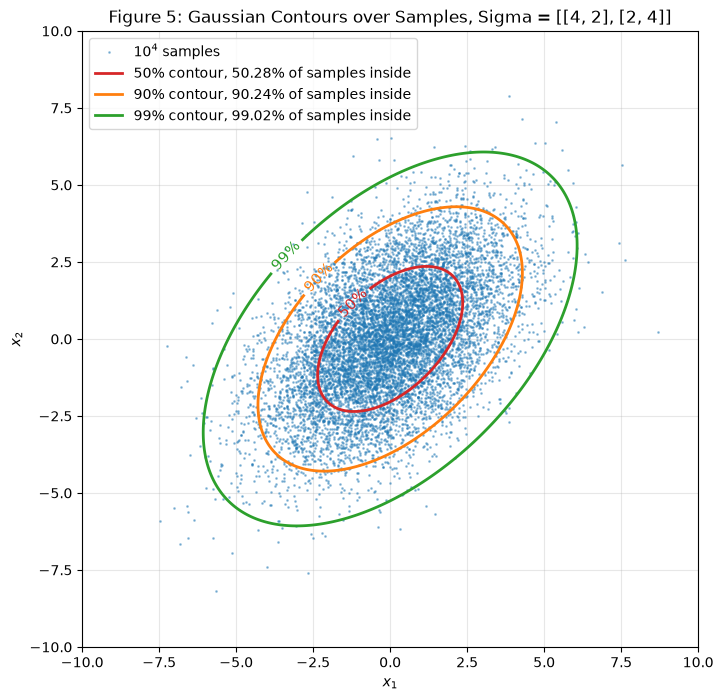

In [15]:
#Part 3: Contours that hold 50%, 90% and 99% of the probability

N_5 = 10**4
samples_5 = rng5.multivariate_normal(mu_5, Sigma_5, size=N_5) #Kept for Step 6

probs_5 = numpy.array([0.5, 0.9, 0.99])
k_5 = -2 * numpy.log(1 - probs_5)                    #Mahalanobis radius squared of each contour
k_chi2_5 = scipy.stats.chi2.ppf(probs_5, df=2)       #Same values from the chi square distribution
levels_5 = numpy.exp(-k_5 / 2) / (2 * numpy.pi * numpy.sqrt(det_5)) #Density on each contour

#Squared Mahalanobis distance of every sample, using solve instead of the inverse
mahal_sq_5 = numpy.sum(samples_5 * numpy.linalg.solve(Sigma_5, samples_5.T).T, axis=1)

fraction_5 = numpy.array([numpy.mean(mahal_sq_5 <= k) for k in k_5])
se_fraction_5 = numpy.sqrt(probs_5 * (1 - probs_5) / N_5)
diff_fraction_5 = numpy.abs(fraction_5 - probs_5)

print(f"Part 3: Probability Contours, N = {N_5}")
print("Contour    k = -2 ln(1 - p)    chi2 ppf      Density Level    Fraction Inside    Difference    SE         Within 3 SE")
for i in range(3):
    print(f"{100 * probs_5[i]:.0f}%{'':<7}{k_5[i]:<20.4f}{k_chi2_5[i]:<14.4f}{levels_5[i]:<17.6f}{fraction_5[i]:<19.4f}{diff_fraction_5[i]:<14.4f}{se_fraction_5[i]:<11.4f}{diff_fraction_5[i] <= 3 * se_fraction_5[i]}")

#Part 4: Correlation and ellipse axes
rho_5 = Sigma_5[0, 1] / numpy.sqrt(Sigma_5[0, 0] * Sigma_5[1, 1])
eigenvalues_5, V_5 = numpy.linalg.eigh(Sigma_5)
angles_5 = numpy.degrees(numpy.arctan2(V_5[1], V_5[0]))

print("\nPart 4: Correlation and Ellipse Axes")
print(f"rho = {rho_5:.4f}   det(Sigma) = {det_5:.4f}")
for i in range(2):
    print(f"Eigenvalue {eigenvalues_5[i]:.4f}   eigenvector {numpy.round(V_5[:, i], 4)}   direction {angles_5[i]:.1f} degrees")
print("\nContour             Semi Axis along Eigenvalue 2     Semi Axis along Eigenvalue 6")
for name, k in [("r^2 = 1 (1 sigma)", 1.0), ("50%", k_5[0]), ("90%", k_5[1]), ("99%", k_5[2])]:
    print(f"{name:<20}{numpy.sqrt(k * eigenvalues_5[0]):<33.4f}{numpy.sqrt(k * eigenvalues_5[1]):.4f}")

#Figure 5: contours over a scatter of the samples
plot_grid_5 = numpy.linspace(-10, 10, 801)
P1_5, P2_5 = numpy.meshgrid(plot_grid_5, plot_grid_5)
pdf_plot_5 = func.gaussian_pdf(numpy.column_stack([P1_5.ravel(), P2_5.ravel()]), mu_5, Sigma_5).reshape(P1_5.shape)
colors_5 = ["tab:red", "tab:orange", "tab:green"]

plt.figure(figsize=(8, 8))
plt.plot(samples_5[:, 0], samples_5[:, 1], ".", color="tab:blue", markersize=2, alpha=0.4, label="$10^4$ samples")
for i in range(3):
    contour = plt.contour(P1_5, P2_5, pdf_plot_5, levels=[levels_5[i]], colors=colors_5[i], linewidths=2)
    plt.clabel(contour, fmt={levels_5[i]: f"{100 * probs_5[i]:.0f}%"}, fontsize=11)
    plt.plot([], [], color=colors_5[i], linewidth=2, label=f"{100 * probs_5[i]:.0f}% contour, {100 * fraction_5[i]:.2f}% of samples inside")
plt.gca().set_aspect("equal")
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.title("Figure 5: Gaussian Contours over Samples, Sigma = [[4, 2], [2, 4]]")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.show()

### Figure 5 Explanation

    Figure 5 depicts 10^4 samples with the contours that should hold 50%, 90% and 99% of the probability. From our results in part 3 we can that the fractions inside are 0.5028, 0.9024 and 0.9902 which are very close to the expected value of .50, .90, .99 these are all within 3 standard errors. The covariance matrix gives a correlation of \(0.5\), so the variables tend to increase together and the Gaussian ellipse tilts upward. The eigenvalues 2 and 6 determine the ellipse’s short and long axes, while the eigenvectors give their directions. Our Gaussian PDF matched SciPy’s result almost perfectly, with only a tiny rounding difference. Integrating the PDF over the region \([-15,15]\times[-15,15]\) gave approximately 1, confirming that the density was implemented correctly.

Part 5: Correlation Sweep
rho      det(Sigma)    16(1 - rho^2)    Eigenvalues 4(1 - rho), 4(1 + rho)    90% Semi Axes (short, long)    Var(X2 | X1) = 4(1 - rho^2)
0        16.0000       16.0000          [4. 4.]                               [4.2919 4.2919]                4.0000
0.5      12.0000       12.0000          [2. 6.]                               [3.0349 5.2565]                3.0000
0.9      3.0400        3.0400           [0.4 7.6]                             [1.3572 5.916 ]                0.7600
0.99     0.3184        0.3184           [0.04 7.96]                           [0.4292 6.0545]                0.0796


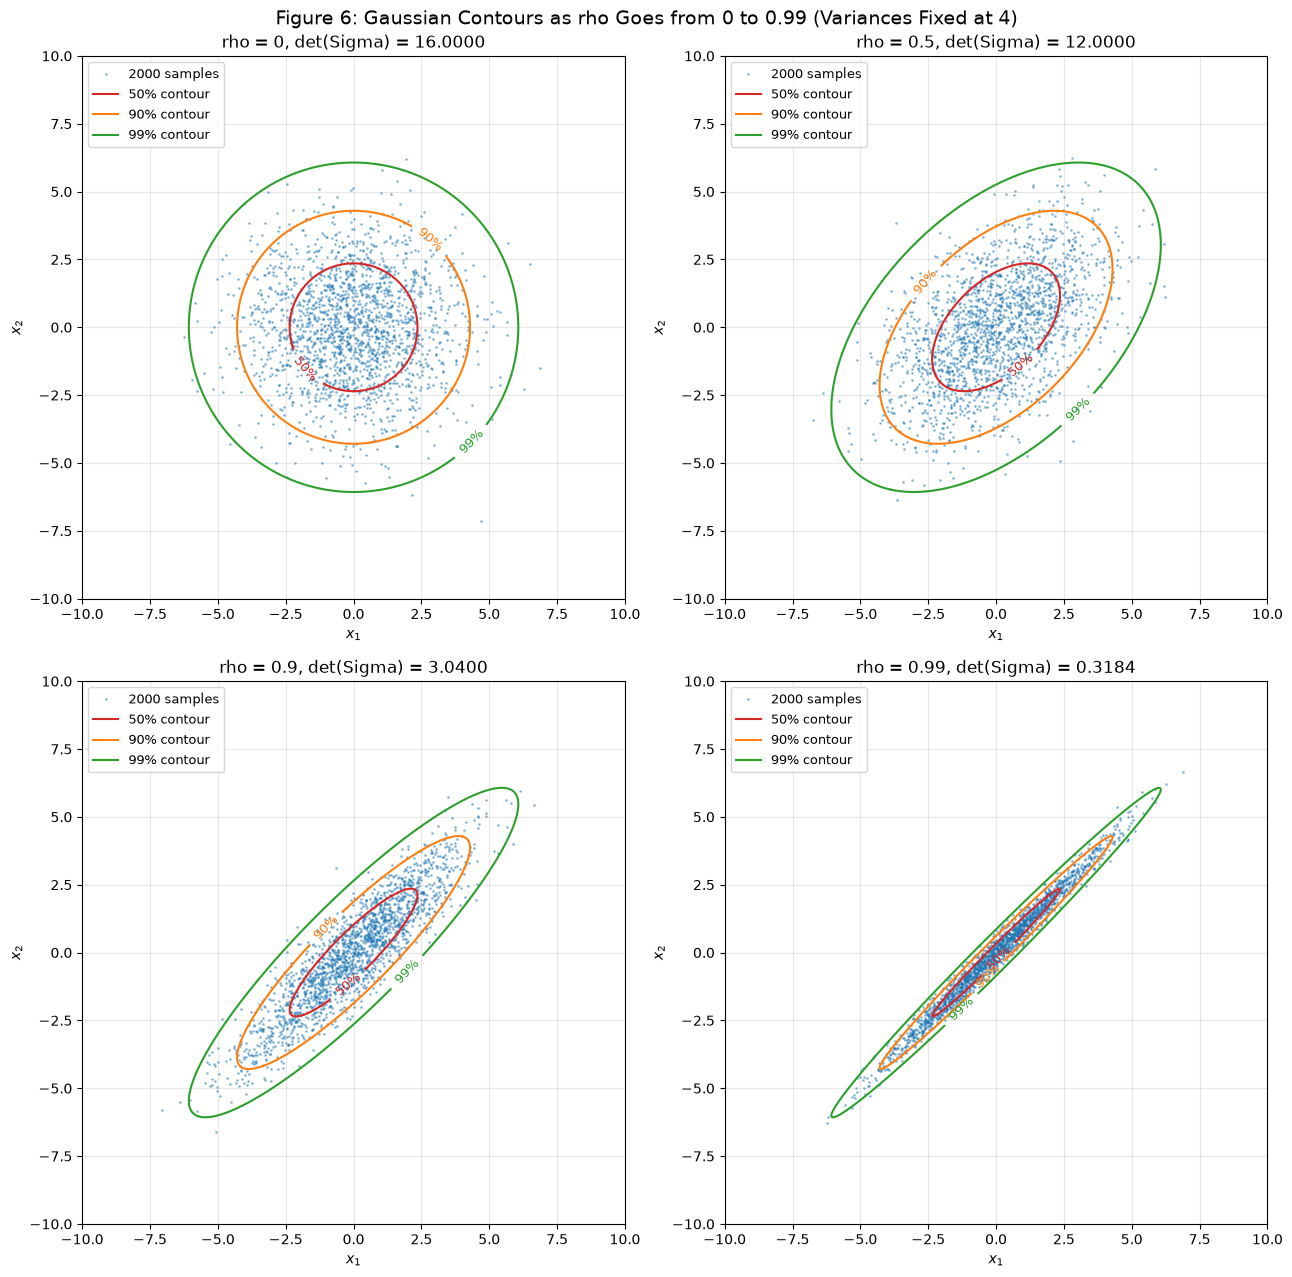

In [16]:
#Part 5: Correlation sweep with the variances held at 4

rhos_5 = [0, 0.5, 0.9, 0.99]
N_sweep_5 = 2000 #Samples drawn for each panel

print("Part 5: Correlation Sweep")
print("rho      det(Sigma)    16(1 - rho^2)    Eigenvalues 4(1 - rho), 4(1 + rho)    90% Semi Axes (short, long)    Var(X2 | X1) = 4(1 - rho^2)")

plt.figure(figsize=(13, 13))
for p, rho in enumerate(rhos_5):
    Sigma_r = 4 * numpy.array([[1, rho], [rho, 1]])
    det_r = numpy.linalg.det(Sigma_r)
    eig_r = numpy.linalg.eigvalsh(Sigma_r)
    print(f"{rho:<9}{det_r:<14.4f}{16 * (1 - rho**2):<17.4f}{str(numpy.round(eig_r, 4)):<38}{str(numpy.round(numpy.sqrt(k_5[1] * eig_r), 4)):<31}{4 * (1 - rho**2):.4f}")

    samples_r = rng5.multivariate_normal(mu_5, Sigma_r, size=N_sweep_5)
    pdf_r = func.gaussian_pdf(numpy.column_stack([P1_5.ravel(), P2_5.ravel()]), mu_5, Sigma_r).reshape(P1_5.shape)
    levels_r = numpy.exp(-k_5 / 2) / (2 * numpy.pi * numpy.sqrt(det_r))

    plt.subplot(2, 2, p + 1)
    plt.plot(samples_r[:, 0], samples_r[:, 1], ".", color="tab:blue", markersize=2, alpha=0.4, label=f"{N_sweep_5} samples")
    for i in range(3):
        contour = plt.contour(P1_5, P2_5, pdf_r, levels=[levels_r[i]], colors=colors_5[i], linewidths=1.5)
        plt.clabel(contour, fmt={levels_r[i]: f"{100 * probs_5[i]:.0f}%"}, fontsize=9)
        plt.plot([], [], color=colors_5[i], label=f"{100 * probs_5[i]:.0f}% contour")
    plt.gca().set_aspect("equal")
    plt.xlim(-10, 10)
    plt.ylim(-10, 10)
    plt.title(f"rho = {rho}, det(Sigma) = {det_r:.4f}")
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")
    plt.legend(loc="upper left", fontsize=9)
    plt.grid(alpha=0.3)

plt.suptitle("Figure 6: Gaussian Contours as rho Goes from 0 to 0.99 (Variances Fixed at 4)", fontsize=14)
plt.tight_layout()
plt.show()

### Figure 6 Explanation
    These graphs show what happens when the correlation rho increases while both variances stay fixed at 4. When rho=0, the variables are independent, so the contours are circular; as rho increases to 0.5, 0.9, and 0.99, the variables become more similar, so the contours tilt upward and become thinner. At the same time, the determinant decreases from 16 to 0.3184, meaning the distribution has less independent spread and is almost collapsed onto a line when rho=0.99. The 50%, 90%, and 99% contours are simply increasingly larger regions that contain approximately those percentages of the samples.
 

## Step 6: Eigendecomposition, Decorrelation and Whitening

**Objective:** See that the covariance matrix is a geometric object, and find the transformation that makes correlation go away.

$$\boldsymbol\mu=\mathbf{0} \qquad \Sigma=\begin{bmatrix}4&2\\2&4\end{bmatrix}$$

**Process:** We will eigendecompose $\Sigma$ by hand and with `eigh`, draw the eigenvectors on the Step 5 samples, then rotate the samples onto the eigenvectors (decorrelation) and rescale each direction to variance 1 (whitening). Then we will show that any rotation of a whitening matrix is still a whitening matrix, and apply `whitening_matrix` to the $4\times4$ $\Sigma$ from Step 3.

### Eigendecomposition by Hand

The eigenvalues solve $\det(\Sigma-\lambda I)=0$:

$$\det\begin{bmatrix}4-\lambda&2\\2&4-\lambda\end{bmatrix}=(4-\lambda)^2-4=0 \;\Rightarrow\; 4-\lambda=\pm2 \;\Rightarrow\; \lambda_1=2,\;\lambda_2=6$$

Eigenvector for $\lambda_1=2$:

$$(\Sigma-2I)\mathbf{v}=\begin{bmatrix}2&2\\2&2\end{bmatrix}\mathbf{v}=\mathbf{0} \;\Rightarrow\; v_1=-v_2 \;\Rightarrow\; \mathbf{v}_1=\frac{1}{\sqrt2}\begin{bmatrix}1\\-1\end{bmatrix}$$

Eigenvector for $\lambda_2=6$:

$$(\Sigma-6I)\mathbf{v}=\begin{bmatrix}-2&2\\2&-2\end{bmatrix}\mathbf{v}=\mathbf{0} \;\Rightarrow\; v_1=v_2 \;\Rightarrow\; \mathbf{v}_2=\frac{1}{\sqrt2}\begin{bmatrix}1\\1\end{bmatrix}$$

So $\Sigma=V\Lambda V^T$ with

$$V=\frac{1}{\sqrt2}\begin{bmatrix}1&1\\-1&1\end{bmatrix} \qquad \Lambda=\begin{bmatrix}2&0\\0&6\end{bmatrix} \qquad V^TV=I$$

An eigenvector is only defined up to sign, so $-\mathbf{v}_1=[-1,1]^T/\sqrt2$ is the same axis.

### Decorrelation

Let $\mathbf{y}=V^T\mathbf{x}$. Using the Step 4 rule with $A=V^T$:

$$\Sigma_y=V^T\Sigma V=V^T(V\Lambda V^T)V=(V^TV)\Lambda(V^TV)=\Lambda$$

$\Lambda$ is diagonal, so the components of $\mathbf{y}$ are uncorrelated, and their variances are the eigenvalues 2 and 6. Since $V$ is orthogonal this is a pure rotation, it does not stretch anything.

### Whitening

Let $W=\Lambda^{-1/2}V^T$, which rotates onto the eigenvectors and then divides each direction by its standard deviation $\sqrt{\lambda_i}$:

$$W\Sigma W^T=\Lambda^{-1/2}V^T(V\Lambda V^T)V\Lambda^{-1/2}=\Lambda^{-1/2}\Lambda\Lambda^{-1/2}=I$$

$$W=\begin{bmatrix}\frac{1}{\sqrt2}&0\\0&\frac{1}{\sqrt6}\end{bmatrix}\frac{1}{\sqrt2}\begin{bmatrix}1&-1\\1&1\end{bmatrix}=\begin{bmatrix}\frac12&-\frac12\\\frac{1}{2\sqrt3}&\frac{1}{2\sqrt3}\end{bmatrix}$$

### Whitening is Not Unique

For any orthogonal $Q$ ($QQ^T=I$):

$$(QW)\Sigma(QW)^T=Q(W\Sigma W^T)Q^T=QIQ^T=QQ^T=I$$

### How Close to I is Close Enough

The sample covariance of $N$ whitened samples is not exactly $I$. For a Gaussian with identity covariance, each sample variance has variance $2/N$ and each sample covariance has variance $1/N$. Adding these over the $d$ diagonal and $d(d-1)$ off diagonal entries:

$$E\left[\|\hat\Sigma-I\|_F^2\right]\approx\frac{2d+d(d-1)}{N}=\frac{d(d+1)}{N} \qquad \|\hat\Sigma-I\|_F\approx\sqrt{\frac{d(d+1)}{N}}$$

This is $\sqrt{6/N}$ for $d=2$ and $\sqrt{20/N}$ for $d=4$. A Frobenius norm near this value means the whitening worked and what is left is estimation error.

In [17]:
#Step 6: Eigendecomposition, decorrelation and whitening

Sigma_6 = Sigma_5.copy()
x_6 = samples_5          #The same 10^4 samples plotted in Figure 5
N_6 = x_6.shape[0]
d_6 = 2

#Smallest angle between two axes in degrees, an axis and its negative are the same axis
def axis_angle_difference(a, b):
    return numpy.abs((a - b + 90) % 180 - 90)

#Part 1: Eigendecomposition with eigh (real eigenvalues in ascending order, orthonormal eigenvectors)
eigenvalues_6, V_6 = numpy.linalg.eigh(Sigma_6)
angles_6 = numpy.degrees(numpy.arctan2(V_6[1], V_6[0]))
Lambda_6 = numpy.diag(eigenvalues_6)

print("Part 1: Eigendecomposition of Sigma = [[4, 2], [2, 4]]")
for i in range(d_6):
    print(f"Eigenvalue {eigenvalues_6[i]:.4f}   eigenvector {numpy.round(V_6[:, i], 4)}   direction {angles_6[i]:.1f} degrees")
print(f"Hand values: eigenvalues 2 and 6, eigenvectors [1, -1]/sqrt(2) and [1, 1]/sqrt(2)")
print(f"Largest |eigenvalue - hand value|:   {numpy.max(numpy.abs(eigenvalues_6 - [2, 6])):.2e}")
print(f"||V^T V - I||_F:                     {numpy.linalg.norm(V_6.T @ V_6 - numpy.eye(d_6), 'fro'):.2e}")
print(f"||V Lambda V^T - Sigma||_F:          {numpy.linalg.norm(V_6 @ Lambda_6 @ V_6.T - Sigma_6, 'fro'):.2e}")

#Part 2: Do the eigenvectors lie along the ellipse axes?
#Points on the 1 sigma ellipse r^2 = 1 are x = L u with L the Cholesky factor and u on the unit circle,
#because x^T Sigma^-1 x = u^T L^T (L L^T)^-1 L u = u^T u = 1
L_6 = numpy.linalg.cholesky(Sigma_6)
theta_6 = numpy.linspace(0, 2 * numpy.pi, 100001)
ellipse_6 = (L_6 @ numpy.vstack([numpy.cos(theta_6), numpy.sin(theta_6)])).T
dist_6 = numpy.linalg.norm(ellipse_6, axis=1)
far_6 = ellipse_6[numpy.argmax(dist_6)]       #End of the long axis
near_6 = ellipse_6[numpy.argmin(dist_6)]      #End of the short axis
far_angle_6 = numpy.degrees(numpy.arctan2(far_6[1], far_6[0]))
near_angle_6 = numpy.degrees(numpy.arctan2(near_6[1], near_6[0]))

#Tips of the scaled eigenvectors sqrt(lambda_i) v_i, each should sit exactly on r^2 = 1
tips_6 = V_6 * numpy.sqrt(eigenvalues_6)      #Column i is sqrt(lambda_i) v_i
tips_r2_6 = numpy.sum(tips_6 * numpy.linalg.solve(Sigma_6, tips_6), axis=0)

#Eigenvectors of the sample covariance of the Step 5 scatter
_, cov_x_6 = func.sample_mean_cov(x_6)
eig_sample_6, V_sample_6 = numpy.linalg.eigh(cov_x_6)
sample_angles_6 = numpy.degrees(numpy.arctan2(V_sample_6[1], V_sample_6[0]))

print("\nPart 2: Eigenvectors and the Ellipse Axes (1 sigma ellipse, r^2 = 1)")
print("Axis     Farthest/Nearest Point on Ellipse    Its Distance    sqrt(eigenvalue)    Its Angle    Eigenvector Angle    Angle Difference")
print(f"Long     {str(numpy.round(far_6, 4)):<37}{dist_6.max():<16.4f}{numpy.sqrt(eigenvalues_6[1]):<20.4f}{far_angle_6:<13.1f}{angles_6[1]:<21.1f}{axis_angle_difference(far_angle_6, angles_6[1]):.4f}")
print(f"Short    {str(numpy.round(near_6, 4)):<37}{dist_6.min():<16.4f}{numpy.sqrt(eigenvalues_6[0]):<20.4f}{near_angle_6:<13.1f}{angles_6[0]:<21.1f}{axis_angle_difference(near_angle_6, angles_6[0]):.4f}")
print(f"r^2 at the tips of sqrt(lambda_i) v_i: {numpy.round(tips_r2_6, 12)}")
print(f"Sample covariance eigenvalues:         {numpy.round(eig_sample_6, 4)}   (exact 2 and 6)")
print(f"Sample eigenvector angles:             {numpy.round(sample_angles_6, 2)} degrees")
print(f"Angle difference from exact axes:      {numpy.round(axis_angle_difference(sample_angles_6, angles_6), 2)} degrees")

#Part 3: Decorrelation y = V^T x, each row of x_6 is one sample so y_row = x_row V
y_6 = x_6 @ V_6
print(f"\nPart 3: Decorrelated y = V^T x, N = {N_6}, exact covariance is Lambda = diag(2, 6)")
mean_y_6, cov_y_6 = compare_mean_cov(y_6, numpy.zeros(d_6), Lambda_6)
corr_x_6 = cov_x_6[0, 1] / numpy.sqrt(cov_x_6[0, 0] * cov_x_6[1, 1])
corr_y_6 = cov_y_6[0, 1] / numpy.sqrt(cov_y_6[0, 0] * cov_y_6[1, 1])
print(f"Sample correlation before: {corr_x_6:.4f}   after: {corr_y_6:.4f}   1/sqrt(N) = {1 / numpy.sqrt(N_6):.4f}")

#Part 4: Whitening W = Lambda^(-1/2) V^T
W_6 = func.whitening_matrix(Sigma_6)
W_hand_6 = numpy.array([[0.5, -0.5], [1 / (2 * numpy.sqrt(3)), 1 / (2 * numpy.sqrt(3))]])
z_6 = x_6 @ W_6.T

print(f"\nPart 4: Whitened z = W x, N = {N_6}, exact covariance is I")
print(f"W from whitening_matrix: {numpy.round(W_6[0], 4)}")
print(f"                         {numpy.round(W_6[1], 4)}")
print(f"Largest |W - hand W| allowing a sign flip per row: {numpy.max(numpy.min([numpy.abs(W_6 - W_hand_6), numpy.abs(W_6 + W_hand_6)], axis=0)):.2e}")
print(f"||W Sigma W^T - I||_F with the exact Sigma: {numpy.linalg.norm(W_6 @ Sigma_6 @ W_6.T - numpy.eye(d_6), 'fro'):.2e}")
mean_z_6, cov_z_6 = compare_mean_cov(z_6, numpy.zeros(d_6), numpy.eye(d_6))

#Frobenius norm of the sample covariance of the whitened samples minus I, at N = 10^4 and 10^6
N_big_6 = 10**6
x_big_6 = rng6.multivariate_normal(mu_5, Sigma_6, size=N_big_6)
z_big_6 = x_big_6 @ W_6.T
_, cov_z_big_6 = func.sample_mean_cov(z_big_6)
frob_white_6 = {N_6: numpy.linalg.norm(cov_z_6 - numpy.eye(d_6), "fro"),
                N_big_6: numpy.linalg.norm(cov_z_big_6 - numpy.eye(d_6), "fro")}

print("\nN          ||cov(Wx) - I||_F    Expected sqrt(6/N)    Ratio    sqrt(N) x error")
for N, frob in frob_white_6.items():
    expected = numpy.sqrt(d_6 * (d_6 + 1) / N)
    print(f"{N:<11}{frob:<21.4f}{expected:<22.4f}{frob / expected:<9.2f}{numpy.sqrt(N) * frob:.2f}")

Part 1: Eigendecomposition of Sigma = [[4, 2], [2, 4]]
Eigenvalue 2.0000   eigenvector [-0.7071  0.7071]   direction 135.0 degrees
Eigenvalue 6.0000   eigenvector [0.7071 0.7071]   direction 45.0 degrees
Hand values: eigenvalues 2 and 6, eigenvectors [1, -1]/sqrt(2) and [1, 1]/sqrt(2)
Largest |eigenvalue - hand value|:   0.00e+00
||V^T V - I||_F:                     3.16e-16
||V Lambda V^T - Sigma||_F:          1.29e-15

Part 2: Eigenvectors and the Ellipse Axes (1 sigma ellipse, r^2 = 1)
Axis     Farthest/Nearest Point on Ellipse    Its Distance    sqrt(eigenvalue)    Its Angle    Eigenvector Angle    Angle Difference
Long     [1.7321 1.732 ]                      2.4495          2.4495              45.0         45.0                 0.0007
Short    [-1.  1.]                            1.4142          1.4142              135.0        135.0                0.0021
r^2 at the tips of sqrt(lambda_i) v_i: [1. 1.]
Sample covariance eigenvalues:         [1.9604 6.0174]   (exact 2 and 6)
Sample 

### Eigendecomposition Results

    eigh returned the eigenvalues 2.0000 and 6.0000, a largest difference of 0.00e+00 from our hand values. The eigenvectors are orthonormal (||V^T V - I||_F = 3.16e-16) and rebuild Sigma (||V Lambda V^T - Sigma||_F = 1.29e-15). eigh lists the eigenvalues in ascending order, so the first eigenvector [-0.7071, 0.7071] at 135.0 degrees is the short axis. It is our hand vector [1, -1]/sqrt(2) with the sign flipped, which is the same axis, so there is nothing to fix. The second eigenvector [0.7071, 0.7071] at 45.0 degrees is the long axis.

### Eigenvectors and the Ellipse Axes

    To check that the eigenvectors lie along the ellipse axes, we traced the 1 sigma ellipse (r^2 = 1) and found its farthest and nearest points from the center. The farthest point is at distance 2.4495 = sqrt(6) and angle 45.0 degrees, and the nearest point is at distance 1.4142 = sqrt(2) and angle 135.0 degrees. These differ from the eigenvector directions by only 0.0007 and 0.0021 degrees, which is the spacing of the points we traced. The tips of sqrt(lambda_i) v_i have r^2 = 1 exactly, so each scaled eigenvector ends on the ellipse at the end of an axis. The eigenvectors of the sample covariance of the Step 5 scatter point at 135.17 and 45.17 degrees, 0.17 degrees from the exact axes, with sample eigenvalues 1.9604 and 6.0174.

### Decorrelation

    After y = V^T x, the sample covariance of y has an off diagonal entry of 0.0122 with a standard error of 0.0348, and diagonal entries of 1.9604 and 6.0174 against the eigenvalues 2 and 6. Every entry is within 3 standard errors of Lambda (largest |difference| / SE = 1.44), so the covariance of y is diagonal with the eigenvalues on the diagonal. The sample correlation fell from 0.5085 to 0.0035, which is less than 1/sqrt(N) = 0.0100.

### Whitening

    whitening_matrix returned W = [[-0.5, 0.5], [0.2887, 0.2887]], which matches our hand W to 1.11e-16 once the sign of the first row is flipped (the same eigenvector sign flip as above). With the exact Sigma, ||W Sigma W^T - I||_F = 4.97e-16, so W whitens exactly up to rounding. For the 10^4 samples the sample covariance of W x has diagonal entries 0.9802 and 1.0029 and an off diagonal entry of 0.0035, all within 3 standard errors of I. The Frobenius norm of the difference from I was 0.0206 at N = 10^4 against the expected estimation error sqrt(6/N) = 0.0245, and 0.0022 at N = 10^6 against 0.0024, so what is left is estimation error and it falls like 1/sqrt(N) as in Step 3 (sqrt(N) x error = 2.06 and 2.21). The |difference| / SE values are the same as for y because whitening only rescales each component of y, which rescales the difference and its standard error by the same factor.

In [18]:
#Part 5: Whitening is not unique, QW is a whitening matrix for any orthogonal Q
angle_Q_6 = numpy.radians(30)
Q_6 = numpy.array([[numpy.cos(angle_Q_6), -numpy.sin(angle_Q_6)],
                   [numpy.sin(angle_Q_6),  numpy.cos(angle_Q_6)]])
QW_6 = Q_6 @ W_6
_, cov_qz_6 = func.sample_mean_cov(x_6 @ QW_6.T)

print("Part 5: Rotated Whitening Matrix QW, Q = rotation by 30 degrees")
print(f"||Q^T Q - I||_F:                          {numpy.linalg.norm(Q_6.T @ Q_6 - numpy.eye(d_6), 'fro'):.2e}   det(Q) = {numpy.linalg.det(Q_6):.4f}")
print(f"||QW - W||_F (QW is a different matrix):  {numpy.linalg.norm(QW_6 - W_6, 'fro'):.4f}")
print(f"||(QW) Sigma (QW)^T - I||_F, exact Sigma: {numpy.linalg.norm(QW_6 @ Sigma_6 @ QW_6.T - numpy.eye(d_6), 'fro'):.2e}")
print(f"||cov(QW x) - I||_F, N = {N_6}:          {numpy.linalg.norm(cov_qz_6 - numpy.eye(d_6), 'fro'):.4f}   (same as W: {frob_white_6[N_6]:.4f})")

#Two other common whitening matrices, and the orthogonal Q that links each one to W
W_zca_6 = V_6 @ numpy.diag(1 / numpy.sqrt(eigenvalues_6)) @ V_6.T   #Sigma^(-1/2), Q = V
W_chol_6 = numpy.linalg.solve(L_6, numpy.eye(d_6))                   #L^-1 from the Cholesky factor
print("\nWhitening Matrix          ||M Sigma M^T - I||_F    Q = M W^-1, ||Q^T Q - I||_F")
for name, M in [("W = Lambda^-1/2 V^T", W_6), ("QW, 30 degree rotation", QW_6),
                ("Sigma^-1/2 (ZCA)", W_zca_6), ("L^-1 (Cholesky)", W_chol_6)]:
    Q_link = M @ numpy.linalg.solve(W_6, numpy.eye(d_6))
    print(f"{name:<26}{numpy.linalg.norm(M @ Sigma_6 @ M.T - numpy.eye(d_6), 'fro'):<25.2e}{numpy.linalg.norm(Q_link.T @ Q_link - numpy.eye(d_6), 'fro'):.2e}")

#Part 6: The 4 x 4 Sigma from Step 3
d_3_6 = Sigma_3.shape[0]
W_3_6 = func.whitening_matrix(Sigma_3)
x_3_6 = rng6.multivariate_normal(mu_3, Sigma_3, size=N_big_6)
_, cov_x_3_6 = func.sample_mean_cov(x_3_6)
_, cov_z_3_6 = func.sample_mean_cov(x_3_6 @ W_3_6.T)
frob_3_6 = numpy.linalg.norm(cov_z_3_6 - numpy.eye(d_3_6), "fro")
expected_3_6 = numpy.sqrt(d_3_6 * (d_3_6 + 1) / N_big_6)

#Largest correlation between two different components, before and after whitening
def largest_offdiag_corr(S):
    s = numpy.sqrt(numpy.diag(S))
    R = S / numpy.outer(s, s)
    return numpy.max(numpy.abs(R[~numpy.eye(len(S), dtype=bool)]))

print(f"\nPart 6: Whitening the 4 x 4 Sigma from Step 3, N = {N_big_6}")
print(f"Eigenvalues used by whitening_matrix:     {numpy.round(numpy.linalg.eigvalsh(Sigma_3), 4)}")
print(f"||W Sigma W^T - I||_F, exact Sigma:       {numpy.linalg.norm(W_3_6 @ Sigma_3 @ W_3_6.T - numpy.eye(d_3_6), 'fro'):.2e}")
print(f"||cov(Wx) - I||_F from samples:           {frob_3_6:.4f}")
print(f"Expected sqrt(20/N):                      {expected_3_6:.4f}   ratio {frob_3_6 / expected_3_6:.2f}")
print(f"Largest |correlation| before whitening:   {largest_offdiag_corr(cov_x_3_6):.4f}")
print(f"Largest |correlation| after whitening:    {largest_offdiag_corr(cov_z_3_6):.4f}   1/sqrt(N) = {1 / numpy.sqrt(N_big_6):.4f}")
print(f"Diagonal of cov(Wx):                      {numpy.round(numpy.diag(cov_z_3_6), 4)}")

Part 5: Rotated Whitening Matrix QW, Q = rotation by 30 degrees
||Q^T Q - I||_F:                          1.05e-17   det(Q) = 1.0000
||QW - W||_F (QW is a different matrix):  0.4226
||(QW) Sigma (QW)^T - I||_F, exact Sigma: 6.48e-16
||cov(QW x) - I||_F, N = 10000:          0.0206   (same as W: 0.0206)

Whitening Matrix          ||M Sigma M^T - I||_F    Q = M W^-1, ||Q^T Q - I||_F
W = Lambda^-1/2 V^T       4.97e-16                 0.00e+00
QW, 30 degree rotation    6.48e-16                 6.80e-17
Sigma^-1/2 (ZCA)          4.44e-16                 3.16e-16
L^-1 (Cholesky)           2.22e-16                 7.61e-16

Part 6: Whitening the 4 x 4 Sigma from Step 3, N = 1000000
Eigenvalues used by whitening_matrix:     [1.2649 1.7882 3.0981 7.8488]
||W Sigma W^T - I||_F, exact Sigma:       1.32e-15
||cov(Wx) - I||_F from samples:           0.0034
Expected sqrt(20/N):                      0.0045   ratio 0.76
Largest |correlation| before whitening:   0.5171
Largest |correlation| after whiten

### Whitening is Not Unique

    We built Q as a rotation by 30 degrees, which is orthogonal (||Q^T Q - I||_F = 1.05e-17, det(Q) = 1.0000). QW is a different matrix from W (||QW - W||_F = 0.4226), but (QW) Sigma (QW)^T is still I to rounding level (below 1e-15). The sample covariance of QW x is 0.0206 from I in Frobenius norm, exactly the same as for W, because rotating a matrix does not change its Frobenius norm. Two other common choices also whiten Sigma, the symmetric Sigma^-1/2 (ZCA) and the inverse Cholesky factor L^-1, both to rounding level (below 1e-15), and each one equals Q W for an orthogonal Q (||Q^T Q - I||_F below 1e-15 for both). In practice this means whitening only fixes the covariance up to a rotation, so the whitened coordinates have no unique meaning and an engineer picks one by a second rule (PCA whitening to keep the eigen directions, ZCA to stay closest to the original measurements, Cholesky because it is cheapest), while anything that only uses the Mahalanobis length ||Wx||^2 gives the same answer for all of them.

### 4 x 4 Sigma from Step 3

    whitening_matrix used the eigenvalues 1.2649, 1.7882, 3.0981 and 7.8488, the same ones we found in Step 3, and with the exact Sigma it gave ||W Sigma W^T - I||_F at rounding level (below 1e-14). With 10^6 samples the sample covariance of W x was 0.0034 from I, below the expected estimation error sqrt(20/N) = 0.0045 (ratio 0.76). Its diagonal entries were 0.9983, 0.9976, 0.9991 and 1.0005, and the largest correlation between two components dropped from 0.5171 before whitening to 0.0006 after, which is below 1/sqrt(N) = 0.0010. So the same function whitens in 4 dimensions as well.

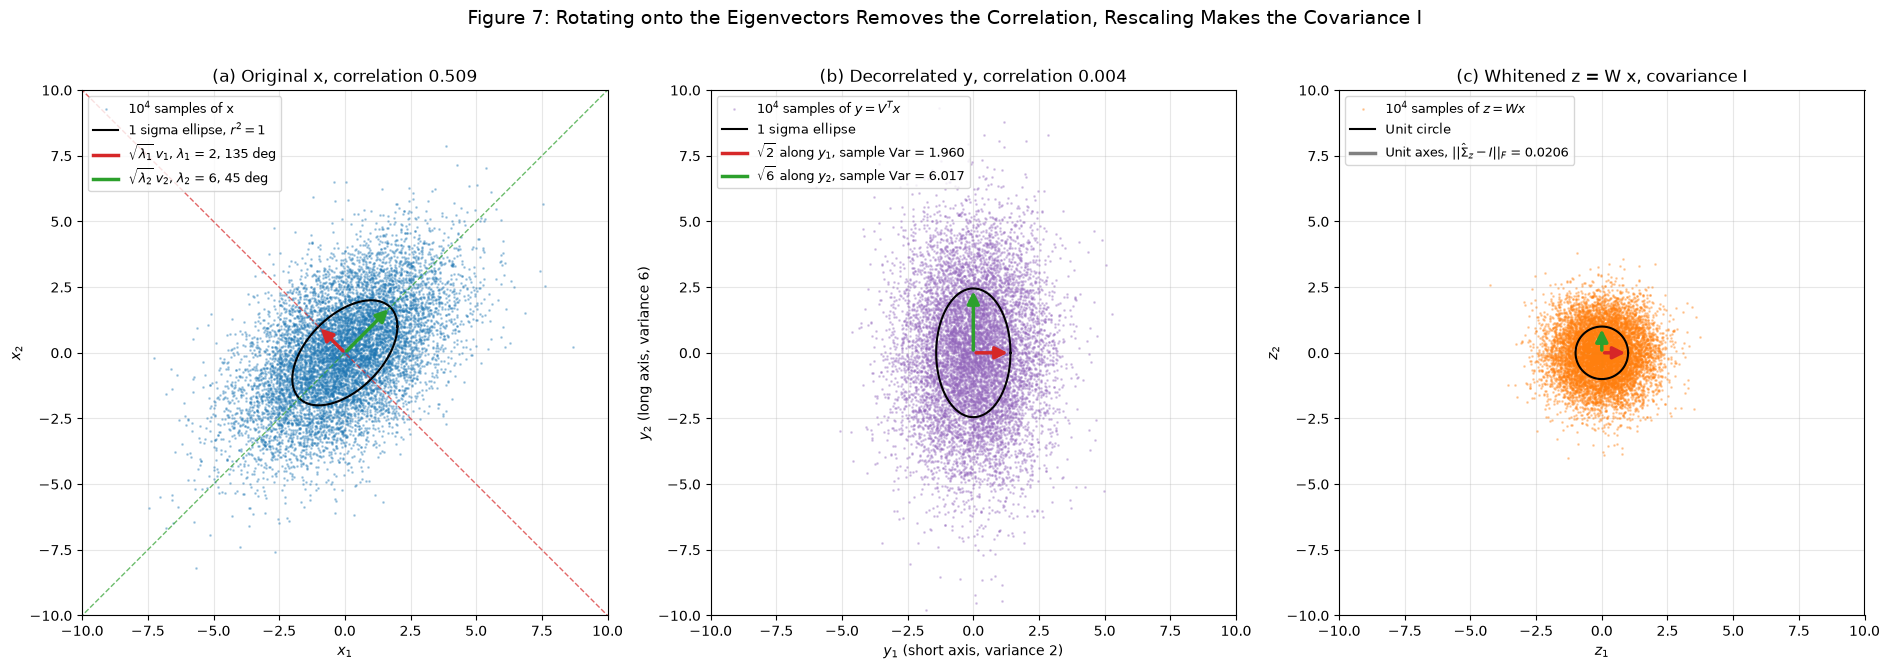

In [19]:
#Figure 7: original with eigenvector axes, decorrelated, and whitened samples, all on the same equal axes
lim_6 = 10
circle_6 = numpy.vstack([numpy.cos(theta_6), numpy.sin(theta_6)])
arrow_colors_6 = ["tab:red", "tab:green"]

def draw_arrow(tip, color):
    plt.annotate("", xy=tip, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5, mutation_scale=18))

plt.figure(figsize=(19, 6.8))

#Panel a: correlated samples, scaled eigenvectors and the 1 sigma ellipse
plt.subplot(1, 3, 1)
plt.plot(x_6[:, 0], x_6[:, 1], ".", color="tab:blue", markersize=2, alpha=0.3, label="$10^4$ samples of x")
plt.plot(ellipse_6[:, 0], ellipse_6[:, 1], color="black", linewidth=1.5, label="1 sigma ellipse, $r^2 = 1$")
for i in range(d_6):
    axis_line = numpy.outer([-lim_6 * 2, lim_6 * 2], V_6[:, i])
    plt.plot(axis_line[:, 0], axis_line[:, 1], "--", color=arrow_colors_6[i], linewidth=1, alpha=0.7)
    draw_arrow(tips_6[:, i], arrow_colors_6[i])
    plt.plot([], [], color=arrow_colors_6[i], linewidth=2.5,
             label=f"$\\sqrt{{\\lambda_{i + 1}}}\\,v_{i + 1}$, $\\lambda_{i + 1}$ = {eigenvalues_6[i]:.0f}, {angles_6[i]:.0f} deg")
plt.title(f"(a) Original x, correlation {corr_x_6:.3f}")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")

#Panel b: decorrelated samples, the axes are now the coordinate axes
plt.subplot(1, 3, 2)
plt.plot(y_6[:, 0], y_6[:, 1], ".", color="tab:purple", markersize=2, alpha=0.3, label="$10^4$ samples of $y = V^T x$")
plt.plot(numpy.sqrt(eigenvalues_6[0]) * circle_6[0], numpy.sqrt(eigenvalues_6[1]) * circle_6[1], color="black", linewidth=1.5, label="1 sigma ellipse")
draw_arrow([numpy.sqrt(eigenvalues_6[0]), 0], arrow_colors_6[0])
draw_arrow([0, numpy.sqrt(eigenvalues_6[1])], arrow_colors_6[1])
plt.plot([], [], color=arrow_colors_6[0], linewidth=2.5, label=f"$\\sqrt{{2}}$ along $y_1$, sample Var = {cov_y_6[0, 0]:.3f}")
plt.plot([], [], color=arrow_colors_6[1], linewidth=2.5, label=f"$\\sqrt{{6}}$ along $y_2$, sample Var = {cov_y_6[1, 1]:.3f}")
plt.title(f"(b) Decorrelated y, correlation {corr_y_6:.3f}")
plt.xlabel("$y_1$ (short axis, variance 2)")
plt.ylabel("$y_2$ (long axis, variance 6)")

#Panel c: whitened samples, the ellipse becomes the unit circle
plt.subplot(1, 3, 3)
plt.plot(z_6[:, 0], z_6[:, 1], ".", color="tab:orange", markersize=2, alpha=0.3, label="$10^4$ samples of $z = Wx$")
plt.plot(circle_6[0], circle_6[1], color="black", linewidth=1.5, label="Unit circle")
draw_arrow([1, 0], arrow_colors_6[0])
draw_arrow([0, 1], arrow_colors_6[1])
plt.plot([], [], color="gray", linewidth=2.5, label=f"Unit axes, $||\\hat\\Sigma_z - I||_F$ = {frob_white_6[N_6]:.4f}")
plt.title("(c) Whitened z = W x, covariance I")
plt.xlabel("$z_1$")
plt.ylabel("$z_2$")

for p in range(3):
    plt.subplot(1, 3, p + 1)
    plt.gca().set_aspect("equal")
    plt.xlim(-lim_6, lim_6)
    plt.ylim(-lim_6, lim_6)
    plt.grid(alpha=0.3)
    plt.legend(loc="upper left", fontsize=9)

plt.suptitle("Figure 7: Rotating onto the Eigenvectors Removes the Correlation, Rescaling Makes the Covariance I", fontsize=14)
plt.tight_layout()
plt.show()

### Figure 7 Explanation

    Figure 7a depicts the 10^4 samples from Step 5 with the two eigenvectors scaled by the square roots of their eigenvalues, the red arrow of length sqrt(2) at 135 degrees and the green arrow of length sqrt(6) at 45 degrees. Both arrows end on the 1 sigma ellipse, at the ends of its short and long axes, and the dashed lines show that the whole cloud is stretched along the green axis and squeezed along the red one. The sample correlation is 0.5085.

    Figure 7b depicts the same samples after y = V^T x. V^T is a rotation, so the cloud keeps its shape but turns until its long and short axes line up with the coordinate axes. It is still stretched (sample variances 1.9604 and 6.0174), but the tilt is gone and the sample correlation is 0.0035, because the correlation in (a) came from the tilt and not from the stretch.

    Figure 7c depicts the samples after z = W x, which divides each axis of (b) by its standard deviation. The ellipse becomes the unit circle and the cloud looks the same in every direction, with a sample covariance 0.0206 from I. All three panels use the same equal axes, so the shrink from (b) to (c) is real: whitening squeezes the long axis by sqrt(6) and the short axis by sqrt(2).

## Step 7: The Conditional Gaussian

**Objective:** Show that knowing one variable of a jointly Gaussian pair tells us something about the other one, and that for a Gaussian the best guess of the other one is a straight line in what we know.

$$\boldsymbol\mu=\mathbf{0} \qquad \Sigma=\begin{bmatrix}4&2\\2&4\end{bmatrix} \qquad \text{Var}(X)=\text{Var}(Y)=4,\;\; \text{Cov}(X,Y)=2,\;\; \rho=0.5$$

**Process:** In order to accomplish this objective we will divide the joint density by the marginal of $X$ and complete the square to find the conditional density of $Y$ given $X=x$. Then we will write the general formula for any Gaussian vector split into two parts and show that our answer is a special case of it. Lastly we will generate $10^6$ samples, sort them into bins of $x$, and check that the average of $y$ in each bin follows $0.5x$ and the variance of $y$ in each bin stays at 3.

### Conditional Density of Y given X = x

Determinant and inverse of $\Sigma$:

$$|\Sigma|=4\cdot4-2\cdot2=12 \qquad \Sigma^{-1}=\frac{1}{12}\begin{bmatrix}4&-2\\-2&4\end{bmatrix}$$

Exponent of the joint density:

$$\begin{bmatrix}x&y\end{bmatrix}\Sigma^{-1}\begin{bmatrix}x\\y\end{bmatrix}=\frac{4x^2-4xy+4y^2}{12}=\frac{x^2-xy+y^2}{3}$$

Joint density, and the marginal of $X$ which is $N(0,4)$ (the marginal of a Gaussian vector is Gaussian, using the matching diagonal entry of $\Sigma$):

$$f_{XY}(x,y)=\frac{1}{2\pi\sqrt{12}}\exp\!\left(-\frac{x^2-xy+y^2}{6}\right) \qquad f_X(x)=\frac{1}{\sqrt{8\pi}}\exp\!\left(-\frac{x^2}{8}\right)$$

Conditional density, the joint density divided by the marginal:

$$f_{Y|X}(y\mid x)=\frac{f_{XY}(x,y)}{f_X(x)}=\frac{\sqrt{8\pi}}{2\pi\sqrt{12}}\exp\!\left(-\frac{x^2-xy+y^2}{6}+\frac{x^2}{8}\right)$$

Exponent, take out $-\frac{1}{6}$ and complete the square in $y$:

$$-\frac{1}{6}\left(y^2-xy+x^2-\frac{3x^2}{4}\right)=-\frac{1}{6}\left(y^2-xy+\frac{x^2}{4}\right)=-\frac{(y-\frac{x}{2})^2}{2\cdot3}$$

Constant in front:

$$\frac{\sqrt{8\pi}}{2\pi\sqrt{12}}=\frac{1}{\sqrt{\pi}}\cdot\frac{\sqrt{8}}{2\sqrt{12}}=\frac{1}{\sqrt{\pi}}\cdot\frac{1}{\sqrt{6}}=\frac{1}{\sqrt{2\pi\cdot3}}$$

Result:

$$f_{Y|X}(y\mid x)=\frac{1}{\sqrt{2\pi\cdot3}}\exp\!\left(-\frac{(y-\frac{x}{2})^2}{2\cdot3}\right)$$

$$Y\mid X=x\;\sim\;N\!\left(0.5x,\;3\right) \qquad E[Y\mid X=x]=0.5x \qquad \text{Var}(Y\mid X=x)=3$$

The conditional density is Gaussian because the exponent is still a square in $y$, and the constant came out to exactly the constant of a Gaussian with variance 3, so it integrates to 1.

### General Result for a Gaussian Vector Split into Two Parts

Split the vector into the part we measure, $\mathbf{x}_a$, and the part we want to know, $\mathbf{x}_b$:

$$\begin{bmatrix}\mathbf{x}_a\\\mathbf{x}_b\end{bmatrix}\sim N\!\left(\begin{bmatrix}\boldsymbol\mu_a\\\boldsymbol\mu_b\end{bmatrix},\begin{bmatrix}\Sigma_{aa}&\Sigma_{ab}\\\Sigma_{ba}&\Sigma_{bb}\end{bmatrix}\right)$$

Then

$$\mathbf{x}_b\mid\mathbf{x}_a\;\sim\;N\!\left(\boldsymbol\mu_b+\Sigma_{ba}\Sigma_{aa}^{-1}(\mathbf{x}_a-\boldsymbol\mu_a),\;\;\Sigma_{bb}-\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{ab}\right)$$

- $\Sigma_{ba}\Sigma_{aa}^{-1}$ = how much the mean of $\mathbf{x}_b$ moves for each unit that $\mathbf{x}_a$ moves
- $\Sigma_{bb}-\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{ab}$ = the uncertainty left in $\mathbf{x}_b$ after we measure $\mathbf{x}_a$ (called the Schur complement). There is no $\mathbf{x}_a$ in it.

Why it works: define the leftover part $\mathbf{e}=\mathbf{x}_b-\boldsymbol\mu_b-\Sigma_{ba}\Sigma_{aa}^{-1}(\mathbf{x}_a-\boldsymbol\mu_a)$. It is a linear function of a Gaussian vector, so it is Gaussian. Using the rules from Step 4:

$$\text{Cov}(\mathbf{e},\mathbf{x}_a)=\Sigma_{ba}-\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{aa}=0$$

$$\text{Cov}(\mathbf{e})=\Sigma_{bb}-2\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{ab}+\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{aa}\Sigma_{aa}^{-1}\Sigma_{ab}=\Sigma_{bb}-\Sigma_{ba}\Sigma_{aa}^{-1}\Sigma_{ab}$$

$\mathbf{e}$ and $\mathbf{x}_a$ are jointly Gaussian with a covariance of 0, so from Step 2 they are independent. Knowing $\mathbf{x}_a$ does not change $\mathbf{e}$, so $\mathbf{x}_b$ is a fixed number that depends on $\mathbf{x}_a$ plus the random $\mathbf{e}$, which gives the mean and covariance above.

Our case: $\mathbf{x}_a=X$ and $\mathbf{x}_b=Y$, so every block is a single number, $\Sigma_{aa}=4$, $\Sigma_{ab}=\Sigma_{ba}=2$, $\Sigma_{bb}=4$ and $\boldsymbol\mu=\mathbf{0}$:

$$E[Y\mid X=x]=0+\frac{2}{4}(x-0)=0.5x \qquad \text{Var}(Y\mid X=x)=4-\frac{2\cdot2}{4}=3$$

which is the same answer we got by hand. Written with $\rho$:

$$E[Y\mid X=x]=\mu_Y+\rho\frac{\sigma_Y}{\sigma_X}(x-\mu_X) \qquad \text{Var}(Y\mid X)=\sigma_Y^2(1-\rho^2)=4(1-0.25)=3$$

### Numerical Check

We split the $x$ axis into bins of width 0.25 from $-6$ to $6$ (3 standard deviations of $X$) and skip bins with fewer than 200 samples. In each bin we find the average and the variance of $y$, with the same standard errors as Step 2:

$$SE_{\text{mean}}=\frac{s}{\sqrt{n}} \qquad SE_{\text{var}}=\frac{\text{std}\big((y-\bar y)^2\big)}{\sqrt{n}}$$

We plot each bin at the average $x$ inside it instead of the middle of the bin, because the average of $0.5X$ over the bin is exactly $0.5\bar x$.

We fit a straight line through the binned means with `numpy.polyfit`, weighting each bin by $1/SE$ so the bins at the edges with few samples count less. The standard error of the slope should be close to the one for a line fit to all $10^6$ points:

$$SE(\text{slope})=\sqrt{\frac{\text{Var}(Y\mid X)}{N\,\text{Var}(X)}}=\sqrt{\frac{3}{4\cdot10^6}}$$

Each bin has a width, so $0.5x$ moves a little inside it, which makes the variance we measure slightly larger than 3:

$$\text{Var}(Y\mid X\text{ in bin})=3+0.25\,\text{Var}(X\text{ in bin})\approx3+0.25\cdot\frac{0.25^2}{12}=3.0013$$

This is much smaller than the standard error of any bin, but we compare against it anyway.

Part 1 and 2: Conditional Density of Y given X = x
rho = 0.5000
E[Y | X = x] = 0.5000 x      Var(Y | X = x) = 3.0000
Largest relative difference between f(x, y)/f_X(x) and the N(0.5x, 3) density at 5 points: 3.13e-16

Part 3: Conditional Mean, N = 1000000, 48 bins of width 0.25 from x = -5.87 to 5.87
Samples per bin: smallest 670, largest 50153
Fitted slope:      0.501340   SE 0.000879   exact 0.5   |difference| / SE = 1.52
Fitted intercept:  0.000047   SE 0.001735   exact 0     |difference| / SE = 0.03
Spread of the samples around the line: sqrt(Var(Y | X)) = 1.7321
Expected slope SE from all the points, sqrt(3 / (4N)) = 0.000866
Largest |binned mean - 0.5x| / SE: 2.74   bins within 3 SE: 48 of 48

Part 4: Conditional Variance
Largest bin width correction 0.25 Var(X in bin): 0.00138
Binned variances go from 2.8123 to 3.1977
Fitted variance at x = 0: 3.0011   SE 0.0042   exact 3   |difference| / SE = 0.27
Slope of the variance against x: 0.00297   SE 0.00215   |slope| / SE = 1.38
Large

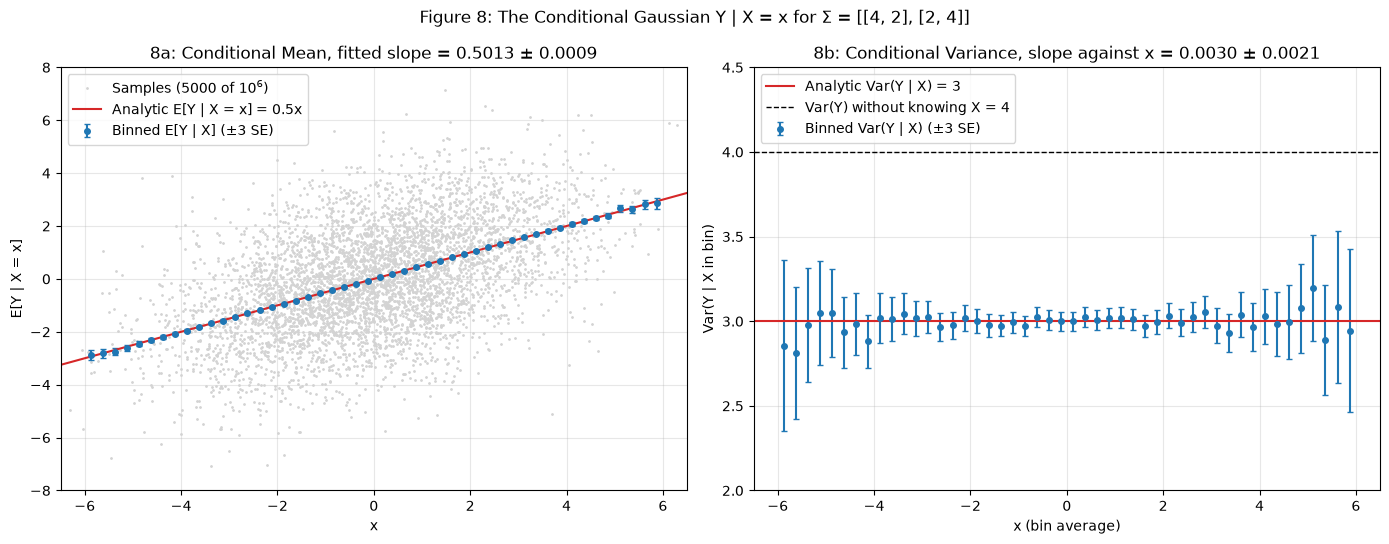

In [20]:
#Step 7: The conditional Gaussian

N_7 = 10**6 #One million samples

mu_7 = numpy.zeros(2)
Sigma_7 = Sigma_5.copy() #[[4, 2], [2, 4]]

#Hand calculated values from the partitioned formula
slope_exact_7 = Sigma_7[1, 0] / Sigma_7[0, 0]                                     #Sigma_yx / Sigma_xx = 2/4 = 0.5
cond_var_exact_7 = Sigma_7[1, 1] - Sigma_7[1, 0] * Sigma_7[0, 1] / Sigma_7[0, 0]  #Sigma_yy - Sigma_yx Sigma_xy / Sigma_xx = 4 - 1 = 3
rho_7 = Sigma_7[0, 1] / numpy.sqrt(Sigma_7[0, 0] * Sigma_7[1, 1])                 #2/4 = 0.5
assert numpy.isclose(slope_exact_7, 0.5)
assert numpy.isclose(cond_var_exact_7, 3)
assert numpy.isclose(cond_var_exact_7, Sigma_7[1, 1] * (1 - rho_7**2)) #Same thing written as sigma_y^2 (1 - rho^2)

#Part 1 check: the joint density divided by the marginal of X should be the N(x/2, 3) density at every point
points_7 = numpy.array([[0, 0], [1, -2], [-3, 1.5], [2.5, 2.5], [4, -1]], dtype=float)
joint_7 = func.gaussian_pdf(points_7, mu_7, Sigma_7)
marginal_x_7 = func.gaussian_pdf(points_7[:, :1], [0], [[4]])   #X by itself is N(0, 4)
cond_hand_7 = func.gaussian_pdf((points_7[:, 1] - 0.5 * points_7[:, 0])[:, None], [0], [[3]]) #N(0.5x, 3) density at y
largest_rel_diff_7 = numpy.max(numpy.abs(joint_7 / marginal_x_7 - cond_hand_7) / cond_hand_7)

print("Part 1 and 2: Conditional Density of Y given X = x")
print(f"rho = {rho_7:.4f}")
print(f"E[Y | X = x] = {slope_exact_7:.4f} x      Var(Y | X = x) = {cond_var_exact_7:.4f}")
print(f"Largest relative difference between f(x, y)/f_X(x) and the N(0.5x, 3) density at 5 points: {largest_rel_diff_7:.2e}")

#Part 3: Generate 10^6 samples and put them into bins of x
samples_7 = rng7.multivariate_normal(mu_7, Sigma_7, size=N_7)
x_7 = samples_7[:, 0]
y_7 = samples_7[:, 1]

#Bins of width 0.25 from -6 to 6 (3 standard deviations of X). Bins with fewer than 200 samples are skipped because they are too noisy.
edges_7 = numpy.arange(-6, 6.25, 0.25)
which_bin_7 = numpy.digitize(x_7, edges_7) - 1  #Bin number of each sample

x_bin_7 = []        #Average x in each bin, this is where we plot the bin
mean_bin_7 = []     #Average y in each bin, the conditional mean
mean_se_7 = []      #Standard error of the conditional mean, s/sqrt(n)
var_bin_7 = []      #Variance of y in each bin, the conditional variance
var_se_7 = []       #Standard error of the conditional variance
count_7 = []        #Number of samples in each bin
spread_x_7 = []     #Variance of x inside each bin, used for the small bin width correction

for b in range(len(edges_7) - 1):
    in_bin = which_bin_7 == b
    n = numpy.sum(in_bin)
    if n < 200:
        continue
    xb = x_7[in_bin]
    yb = y_7[in_bin]
    x_bin_7.append(xb.mean())
    mean_bin_7.append(yb.mean())
    mean_se_7.append(yb.std(ddof=1) / numpy.sqrt(n))
    var_bin_7.append(yb.var(ddof=1))
    #A sample variance is a sample mean of (y - mean)^2, so its SE is the std of (y - mean)^2 over sqrt(n), the same as Step 2
    var_se_7.append(numpy.std((yb - yb.mean())**2) / numpy.sqrt(n))
    count_7.append(n)
    spread_x_7.append(xb.var(ddof=1))

x_bin_7 = numpy.array(x_bin_7)
mean_bin_7 = numpy.array(mean_bin_7)
mean_se_7 = numpy.array(mean_se_7)
var_bin_7 = numpy.array(var_bin_7)
var_se_7 = numpy.array(var_se_7)
count_7 = numpy.array(count_7)
spread_x_7 = numpy.array(spread_x_7)
n_bins_7 = len(count_7)

#Straight line fit to the binned means. Each bin is weighted by 1/SE so the noisy bins at the edges count less.
#cov="unscaled" returns the covariance of the fitted slope and intercept, and the square root of its diagonal is their SE.
fit_mean_7, fit_cov_7 = numpy.polyfit(x_bin_7, mean_bin_7, 1, w=1 / mean_se_7, cov="unscaled")
slope_7, intercept_7 = fit_mean_7
slope_se_7, intercept_se_7 = numpy.sqrt(numpy.diag(fit_cov_7))

#SE we would expect for a slope fit to all 10^6 points: sqrt(Var(Y | X) / (N Var(X)))
slope_se_expected_7 = numpy.sqrt(cond_var_exact_7 / (N_7 * Sigma_7[0, 0]))

#How many standard errors each binned mean is from the line 0.5x
z_mean_7 = (mean_bin_7 - slope_exact_7 * x_bin_7) / mean_se_7

print(f"\nPart 3: Conditional Mean, N = {N_7}, {n_bins_7} bins of width 0.25 from x = {x_bin_7.min():.2f} to {x_bin_7.max():.2f}")
print(f"Samples per bin: smallest {count_7.min()}, largest {count_7.max()}")
print(f"Fitted slope:      {slope_7:.6f}   SE {slope_se_7:.6f}   exact 0.5   |difference| / SE = {abs(slope_7 - 0.5) / slope_se_7:.2f}")
print(f"Fitted intercept:  {intercept_7:.6f}   SE {intercept_se_7:.6f}   exact 0     |difference| / SE = {abs(intercept_7) / intercept_se_7:.2f}")
print(f"Spread of the samples around the line: sqrt(Var(Y | X)) = {numpy.sqrt(cond_var_exact_7):.4f}")
print(f"Expected slope SE from all the points, sqrt(3 / (4N)) = {slope_se_expected_7:.6f}")
print(f"Largest |binned mean - 0.5x| / SE: {numpy.max(numpy.abs(z_mean_7)):.2f}   bins within 3 SE: {numpy.sum(numpy.abs(z_mean_7) <= 3)} of {n_bins_7}")

#Part 4: Conditional variance in each bin
#Each bin has a width, so the mean 0.5x moves a little inside it. That adds 0.25 Var(X in bin) to the variance we measure.
expected_var_7 = cond_var_exact_7 + 0.25 * spread_x_7
z_var_7 = (var_bin_7 - expected_var_7) / var_se_7

#Straight line fit to the binned variances. If the variance does not depend on x, the slope should be 0 within its SE.
fit_var_7, fit_var_cov_7 = numpy.polyfit(x_bin_7, var_bin_7, 1, w=1 / var_se_7, cov="unscaled")
var_slope_7, var_intercept_7 = fit_var_7
var_slope_se_7, var_intercept_se_7 = numpy.sqrt(numpy.diag(fit_var_cov_7))

#Variance of Y without knowing X, for comparison
var_y_7 = y_7.var(ddof=1)

print(f"\nPart 4: Conditional Variance")
print(f"Largest bin width correction 0.25 Var(X in bin): {numpy.max(0.25 * spread_x_7):.5f}")
print(f"Binned variances go from {var_bin_7.min():.4f} to {var_bin_7.max():.4f}")
print(f"Fitted variance at x = 0: {var_intercept_7:.4f}   SE {var_intercept_se_7:.4f}   exact 3   |difference| / SE = {abs(var_intercept_7 - 3) / var_intercept_se_7:.2f}")
print(f"Slope of the variance against x: {var_slope_7:.5f}   SE {var_slope_se_7:.5f}   |slope| / SE = {abs(var_slope_7) / var_slope_se_7:.2f}")
print(f"Largest |binned variance - expected| / SE: {numpy.max(numpy.abs(z_var_7)):.2f}   bins within 3 SE: {numpy.sum(numpy.abs(z_var_7) <= 3)} of {n_bins_7}")
print(f"Var(Y) without knowing X: {var_y_7:.4f} (exact 4). Knowing X removes {100 * (1 - var_intercept_7 / var_y_7):.1f}% of the variance (exact rho^2 = 25%)")

#Figure 8: binned conditional means and binned conditional variances
x_line_7 = numpy.linspace(-6.5, 6.5, 200)

plt.figure(figsize=(14, 5.5))

plt.subplot(1, 2, 1)
plt.plot(x_7[:5000], y_7[:5000], ".", color="lightgray", markersize=2, label="Samples (5000 of $10^6$)")
plt.errorbar(x_bin_7, mean_bin_7, yerr=3 * mean_se_7, fmt="o", color="tab:blue", markersize=4, capsize=2, label="Binned E[Y | X] ($\\pm$3 SE)")
plt.plot(x_line_7, 0.5 * x_line_7, color="tab:red", linewidth=1.5, label="Analytic E[Y | X = x] = 0.5x")
plt.title(f"8a: Conditional Mean, fitted slope = {slope_7:.4f} $\\pm$ {slope_se_7:.4f}")
plt.xlabel("x")
plt.ylabel("E[Y | X = x]")
plt.xlim(-6.5, 6.5)
plt.ylim(-8, 8)
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.errorbar(x_bin_7, var_bin_7, yerr=3 * var_se_7, fmt="o", color="tab:blue", markersize=4, capsize=2, label="Binned Var(Y | X) ($\\pm$3 SE)")
plt.axhline(3, color="tab:red", linewidth=1.5, label="Analytic Var(Y | X) = 3")
plt.axhline(4, color="black", linestyle="--", linewidth=1, label="Var(Y) without knowing X = 4")
plt.title(f"8b: Conditional Variance, slope against x = {var_slope_7:.4f} $\\pm$ {var_slope_se_7:.4f}")
plt.xlabel("x (bin average)")
plt.ylabel("Var(Y | X in bin)")
plt.xlim(-6.5, 6.5)
plt.ylim(2, 4.5)
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.suptitle("Figure 8: The Conditional Gaussian Y | X = x for $\\Sigma$ = [[4, 2], [2, 4]]")
plt.tight_layout()
plt.show()


### Figure 8 Explanation

    Figure 8a depicts the 48 binned conditional means of Y with error bars of 3 standard errors, on top of 5000 of the 10^6 samples, and the line E[Y | X = x] = 0.5x in red. You will notice that every bin sits on the line from x = -5.87 to 5.87. All 48 of 48 bins were within 3 standard errors of 0.5x, and the largest was 2.74 standard errors away. The fitted slope was 0.501340 with a standard error of 0.000879, which is 1.52 standard errors from 0.5, and the fitted intercept was 0.000047, which is 0.03 standard errors from 0. The standard error of the slope is close to the 0.000866 we expected for a line fit to all the points, which means putting the samples into bins did not lose information about the slope. The gray samples show that the line is only the average, at any x the samples still spread about sqrt(3) = 1.7321 above and below it.

    Figure 8b depicts the binned conditional variance of Y. The bins are spread around the red line at 3 and not around the dashed line at Var(Y) = 4. They go from 2.8123 to 3.1977, and the ones farthest from 3 are at the edges where some bins have only 670 samples. All 48 of 48 bins were within 3 standard errors of the expected variance (largest 2.32 standard errors). The line fit to the variances gave 3.0011 at x = 0, which is 0.27 standard errors from 3, and a slope of 0.00297 with a standard error of 0.00215, which is 1.38 standard errors from 0. This means the variance does not depend on x. The bin width correction was at most 0.00138, so it does not change anything. The sample Var(Y) was 4.0053, so knowing X removed 25.1% of the variance of Y, which matches rho^2 = 25%.

### The Conditional Variance Does Not Depend on x

    The conditional variance Sigma_yy - Sigma_yx Sigma_xx^-1 Sigma_xy has no x in it, so for a Gaussian every value of x we could measure leaves the same uncertainty of 3. This is special to the Gaussian. In Step 1, f(x, y) = x + y gave E[Y | X = x] = (x/2 + 1/3)/(x + 1/2), which is a curve and not a line, and its conditional variance also changes with x. In Step 2, Y = X² had a conditional variance of 0 everywhere but a conditional mean of x², which is not a line at all. Only the Gaussian gives both a straight line for the conditional mean and the same conditional variance at every x.

### Why the Linear Estimator of Step 8 is Optimal

    The estimator with the smallest mean squared error out of every possible function of the measurements is the conditional mean E[S | X]. For jointly Gaussian data Step 7 shows that this conditional mean is a straight line in x, E[S | X = x] = Sigma_sx^T Sigma_xx^-1 x, which is exactly the LMMSE estimator w^T x with w = Sigma_xx^-1 Sigma_sx. This means the best linear estimator is also the best estimator of any kind, so for Gaussian data using a linear estimator loses nothing, while for non Gaussian data a nonlinear estimator could do better, like in Step 2 where no straight line in X can predict X².

## Step 8: Fusing Two Correlated Sensors

**Objective:** Combine two noisy sensors into one estimate of $S$ and find out how the correlation between their noise changes the best weights and the error.

$$S\sim N(0,4) \qquad X_1=S+N_1 \qquad X_2=S+N_2 \qquad \Sigma_N=\begin{bmatrix}1&c\\c&2\end{bmatrix}$$

The noise $\mathbf{N}=[N_1,N_2]^T$ has zero mean and is independent of $S$. Sensor 1 is the better sensor (noise variance 1) and sensor 2 is noisier (noise variance 2). $c$ is the covariance between the two noises, which is what happens when two sensors share a power supply, interference source or thermal environment.

**Process:** In order to accomplish this objective we will derive $\Sigma_{xx}$ and $\Sigma_{sx}$, derive the linear MMSE weights and error, and find the values of $c$ that make $\Sigma_N$ a valid covariance. Then we will make a table of the weights and the error for different values of $c$, compare them to using only the best sensor and to averaging the two sensors, and derive closed forms that explain what happens at $c=1$. Lastly we will check two rows of the table with $10^6$ Monte Carlo trials.

### Sigma_xx and Sigma_sx

Write the measurements as a vector, with $\mathbf{1}=[1,1]^T$:

$$\mathbf{x}=\begin{bmatrix}X_1\\X_2\end{bmatrix}=S\,\mathbf{1}+\mathbf{N}$$

Covariance of $\mathbf{x}$. Everything has zero mean and $S$ is independent of $\mathbf{N}$, so the cross terms $E[S\mathbf{N}^T]$ are 0:

$$\Sigma_{xx}=E[\mathbf{x}\mathbf{x}^T]=E[S^2]\,\mathbf{1}\mathbf{1}^T+E[S\mathbf{N}^T]\,\mathbf{1}+\mathbf{1}\,E[S\mathbf{N}^T]^T+E[\mathbf{N}\mathbf{N}^T]=\sigma_s^2\mathbf{1}\mathbf{1}^T+\Sigma_N$$

$$\Sigma_{xx}=4\begin{bmatrix}1&1\\1&1\end{bmatrix}+\begin{bmatrix}1&c\\c&2\end{bmatrix}=\begin{bmatrix}5&4+c\\4+c&6\end{bmatrix}$$

Covariance between $S$ and $\mathbf{x}$:

$$\Sigma_{sx}=E[S\mathbf{x}]=E[S^2]\,\mathbf{1}+E[S\mathbf{N}]=\sigma_s^2\mathbf{1}=\begin{bmatrix}4\\4\end{bmatrix}$$

### Linear MMSE Estimator

We want the weights $\mathbf{w}$ in $\hat S=\mathbf{w}^T\mathbf{x}$ that make the mean squared error as small as possible. Expand the error:

$$\text{MSE}(\mathbf{w})=E[(S-\mathbf{w}^T\mathbf{x})^2]=E[S^2]-2\mathbf{w}^TE[S\mathbf{x}]+\mathbf{w}^TE[\mathbf{x}\mathbf{x}^T]\mathbf{w}=\sigma_s^2-2\mathbf{w}^T\Sigma_{sx}+\mathbf{w}^T\Sigma_{xx}\mathbf{w}$$

This is a bowl shaped function of $\mathbf{w}$ (because $\Sigma_{xx}$ is positive definite), so the minimum is where the derivative is 0:

$$\frac{\partial\,\text{MSE}}{\partial\mathbf{w}}=-2\Sigma_{sx}+2\Sigma_{xx}\mathbf{w}=0 \;\Rightarrow\; \Sigma_{xx}\mathbf{w}=\Sigma_{sx} \;\Rightarrow\; \mathbf{w}=\Sigma_{xx}^{-1}\Sigma_{sx}$$

Put $\mathbf{w}$ back into the MSE. Since $\Sigma_{xx}\mathbf{w}=\Sigma_{sx}$, the last term is $\mathbf{w}^T\Sigma_{sx}$:

$$\text{MMSE}=\sigma_s^2-2\mathbf{w}^T\Sigma_{sx}+\mathbf{w}^T\Sigma_{sx}=\sigma_s^2-\Sigma_{sx}^T\Sigma_{xx}^{-1}\Sigma_{sx}$$

`lmmse_weights` finds $\mathbf{w}$ with `numpy.linalg.solve` instead of inverting $\Sigma_{xx}$. The MMSE is the same Schur complement as the conditional variance in Step 7, with $S$ as the part we want and $\mathbf{x}$ as the part we measure.

### Baselines

Best single sensor. Using only $X_1$, the same formula with one number gives $w=\frac{4}{5}$ and

$$\text{MSE}_1=4-\frac{4^2}{5}=0.8 \qquad \text{MSE}_2=4-\frac{4^2}{6}=1.3333$$

so sensor 1 is the best single sensor. One sensor only sees its own noise, so these do not depend on $c$.

Equal weighting. Averaging the two sensors gives $\hat S=\frac{X_1+X_2}{2}=S+\frac{N_1+N_2}{2}$, so the error is the average of the noises:

$$\text{MSE}_{\text{equal}}=\text{Var}\!\left(\frac{N_1+N_2}{2}\right)=\frac{1+2+2c}{4}=\frac{3+2c}{4}$$

### Range of c

$\Sigma_N$ is always symmetric. It also has to be positive semidefinite, which for a $2\times2$ matrix with positive numbers on the diagonal means the determinant can not be negative:

$$\det\Sigma_N=1\cdot2-c^2=2-c^2\geq0 \;\Rightarrow\; |c|\leq\sqrt{2}=1.41421$$

This is the same as saying the correlation $\rho=\frac{c}{\sqrt{1\cdot2}}$ has to be between $-1$ and 1. At $|c|=\sqrt{2}$ the determinant is 0, so $\Sigma_N$ is singular and the noise collapses onto a line like in Step 4. The Gaussian density does not exist there, so we use the open range $|c|<\sqrt{2}$.

Part 1: Covariances (shown for c = 0)
Sigma_xx = [5. 4.]   Sigma_sx = [4. 4.]
           [4. 6.]

Part 3: Admissible Range of c, |c| < sqrt(2) = 1.41421
c          det(Sigma_N) = 2 - c^2    Eigenvalues of Sigma_N    is_valid_covariance
-1.42      -0.0164                   [-0.0055  3.0055]         False
-1.41      0.0119                    [0.004 2.996]             True
0          2.0000                    [1. 2.]                   True
1.41       0.0119                    [0.004 2.996]             True
1.42       -0.0164                   [-0.0055  3.0055]         False

Part 4: LMMSE Weights and MMSE against the Two Baselines
c        w1          w2           MMSE        Best Single Sensor    Equal Weighting    Closed Form MMSE    |Difference|
-1.4     0.585198    0.413081     0.006885    0.800000              0.050000           0.006885            2.95e-16
-1.0     0.571429    0.380952     0.190476    0.800000              0.250000           0.190476            2.22e-16
-0.5     0.5

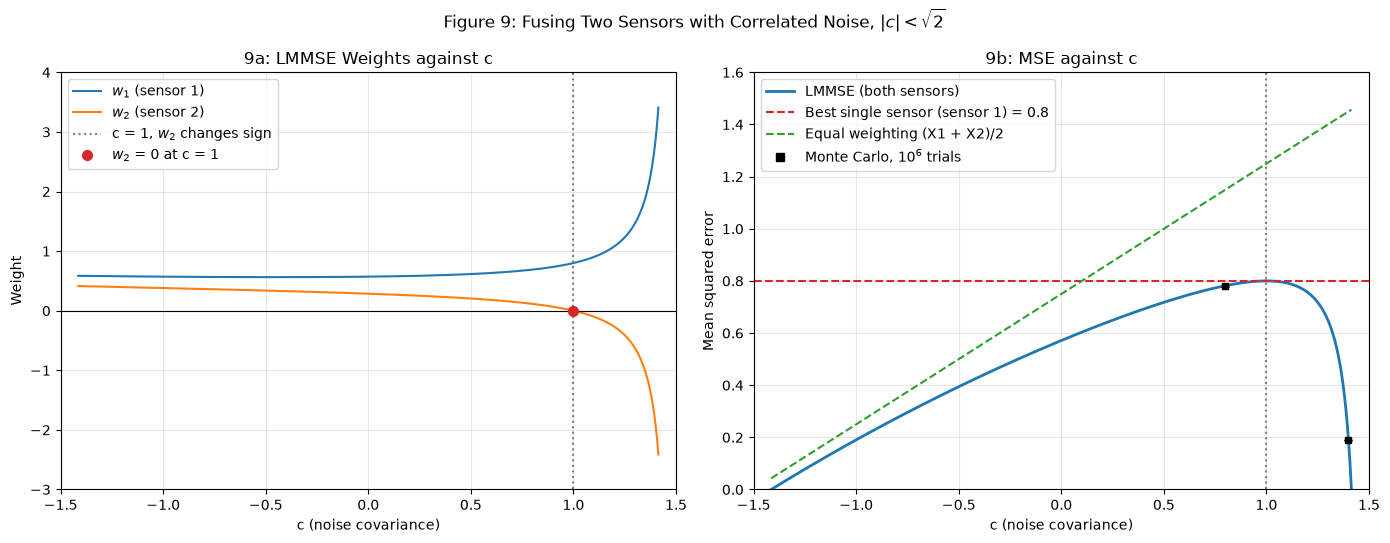

In [21]:
#Step 8: Fusing two correlated sensors

var_s_8 = 4.0                 #Variance of S
ones_8 = numpy.ones(2)        #Both sensors see S with a gain of 1

#Noise covariance for a given c
def noise_cov(c):
    return numpy.array([[1, c], [c, 2]], dtype=float)

#Part 1: Sigma_xx = var_s 1 1^T + Sigma_N and Sigma_sx = var_s 1
def sensor_covs(c):
    Sigma_xx = var_s_8 * numpy.outer(ones_8, ones_8) + noise_cov(c)
    Sigma_sx = var_s_8 * ones_8
    return Sigma_xx, Sigma_sx

#Part 2: LMMSE weights w = Sigma_xx^-1 Sigma_sx and MMSE = var_s - Sigma_sx^T w
def lmmse(c):
    Sigma_xx, Sigma_sx = sensor_covs(c)
    w = func.lmmse_weights(Sigma_xx, Sigma_sx)
    mmse = var_s_8 - Sigma_sx @ w
    return w, mmse

#Closed forms from the hand derivation in Part 5
def w_closed(c):
    D = 30 - (4 + c)**2
    return numpy.array([4 * (2 - c) / D, 4 * (1 - c) / D])

def mmse_closed(c):
    return 4 * (2 - c**2) / (14 - 8 * c - c**2)

#Baselines
#Best single sensor: sensor 1 alone with its own best weight 4/5, MSE = 4 - 4^2/5 = 0.8 for every c
#Sensor 2 alone: weight 4/6, MSE = 4 - 4^2/6 = 1.3333 for every c
#Equal weighting (X1 + X2)/2: the S parts add to S, so the error is (N1 + N2)/2 and MSE = (1 + 2 + 2c)/4
mse_sensor1_8 = var_s_8 - var_s_8**2 / 5
mse_sensor2_8 = var_s_8 - var_s_8**2 / 6
def mse_equal(c):
    return (3 + 2 * c) / 4

Sigma_xx_0, Sigma_sx_0 = sensor_covs(0)
print("Part 1: Covariances (shown for c = 0)")
print(f"Sigma_xx = {Sigma_xx_0[0]}   Sigma_sx = {Sigma_sx_0}")
print(f"           {Sigma_xx_0[1]}")

#Part 3: Admissible range of c. Sigma_N is valid when det = 2 - c^2 >= 0, so |c| <= sqrt(2)
c_max_8 = numpy.sqrt(2)
print(f"\nPart 3: Admissible Range of c, |c| < sqrt(2) = {c_max_8:.5f}")
print("c          det(Sigma_N) = 2 - c^2    Eigenvalues of Sigma_N    is_valid_covariance")
for c in [-1.42, -1.41, 0, 1.41, 1.42]:
    print(f"{c:<11}{2 - c**2:<26.4f}{str(numpy.round(numpy.linalg.eigvalsh(noise_cov(c)), 4)):<26}{func.is_valid_covariance(noise_cov(c))}")

#Part 4: Table of weights and MMSE
c_table_8 = [-1.4, -1.0, -0.5, 0, 0.5, 0.8, 1.0, 1.2, 1.4]
print("\nPart 4: LMMSE Weights and MMSE against the Two Baselines")
print("c        w1          w2           MMSE        Best Single Sensor    Equal Weighting    Closed Form MMSE    |Difference|")
for c in c_table_8:
    w, mmse = lmmse(c)
    print(f"{c:<9}{w[0]:<12.6f}{w[1]:<13.6f}{mmse:<12.6f}{mse_sensor1_8:<22.6f}{mse_equal(c):<19.6f}{mmse_closed(c):<20.6f}{abs(mmse - mmse_closed(c)):.2e}")
print(f"Sensor 2 alone gives MSE {mse_sensor2_8:.6f} for every c, so sensor 1 is the best single sensor")

#Part 5: Check the closed forms on a fine grid of c, and find where the MMSE is largest
c_grid_8 = numpy.linspace(-c_max_8 + 1e-4, c_max_8 - 1e-4, 20001)
w_grid_8 = numpy.array([lmmse(c)[0] for c in c_grid_8])
mmse_grid_8 = numpy.array([lmmse(c)[1] for c in c_grid_8])
w_closed_grid_8 = numpy.array([w_closed(c) for c in c_grid_8])

#Slope of the MMSE from the hand derivative 32(c - 1)(c - 2)/D^2, and a numerical slope at c = 1 to compare
def mmse_derivative(c):
    return 32 * (c - 1) * (c - 2) / (14 - 8 * c - c**2)**2
h_8 = 1e-5
numerical_slope_8 = (mmse_closed(1 + h_8) - mmse_closed(1 - h_8)) / (2 * h_8)
numerical_curvature_8 = (mmse_closed(1 + h_8) - 2 * mmse_closed(1) + mmse_closed(1 - h_8)) / h_8**2

print("\nPart 5: Closed Forms and the Point c = 1")
print(f"Largest |w from lmmse_weights - closed form w| over {len(c_grid_8)} values of c: {numpy.max(numpy.abs(w_grid_8 - w_closed_grid_8)):.2e}")
print(f"Largest |MMSE - closed form MMSE|: {numpy.max(numpy.abs(mmse_grid_8 - mmse_closed(c_grid_8))):.2e}")
print(f"w2 at c = 1: {w_closed(1)[1]:.6f}   w2 at c = 0.999: {w_closed(0.999)[1]:.6f}   w2 at c = 1.001: {w_closed(1.001)[1]:.6f}")
print(f"Slope of MMSE at c = 1: hand formula {mmse_derivative(1):.2e}   numerical {numerical_slope_8:.2e}")
print(f"Second derivative of MMSE at c = 1: hand formula -32/25 = {-32 / 25:.6f}   numerical {numerical_curvature_8:.6f}")
print(f"Slope of MMSE at c = 0.5: {mmse_derivative(0.5):.4f}   at c = 1.2: {mmse_derivative(1.2):.4f}")
print(f"Largest MMSE on the grid: {mmse_grid_8.max():.6f} at c = {c_grid_8[numpy.argmax(mmse_grid_8)]:.4f}")

#Part 6: Variance of X1 - X2 = N1 - N2, the S cancels so this is a measurement of the noise only
var_diff_8 = 1 + 2 - 2 * 1.4
w_14, _ = lmmse(1.4)
noise_guess_8 = (1 - 1.4) / var_diff_8      #Cov(N1, N1 - N2) / Var(N1 - N2), the Step 7 slope for guessing N1 from N1 - N2
print(f"\nPart 6: Var(X1 - X2) = 3 - 2c = {var_diff_8:.4f} at c = 1.4   and {3 - 2 * 0.8:.4f} at c = 0.8")
print(f"w1 + w2 = {w_14.sum():.6f} = 4/4.2 = {4 / 4.2:.6f}   -w2 / (w1 + w2) = {-w_14[1] / w_14.sum():.4f}")
print(f"Best guess of N1 from X1 - X2: Cov(N1, N1 - N2)/Var(N1 - N2) = {noise_guess_8:.4f} times the difference")

#Part 7 and 8: Compare MMSE values
print(f"\nPart 7 and 8: MMSE at c = 0: {mmse_closed(0):.6f}   at c = 1.4: {mmse_closed(1.4):.6f}   ratio {mmse_closed(0) / mmse_closed(1.4):.2f}")
print(f"MMSE at c = -1: {mmse_closed(-1):.6f}   at c = 1.4: {mmse_closed(1.4):.6f}   4/21 = {4 / 21:.6f}")
print(f"New information from sensor 2, (1 - c)^2/(2 - c^2): c = 0: {1 / 2:.4f}   c = 1: {0:.4f}   c = -1: {4 / 1:.4f}   c = 1.4: {0.4**2 / (2 - 1.4**2):.4f}")
print(f"MMSE near the ends: c = -1.414: {mmse_closed(-1.414):.6f}   c = 1.414: {mmse_closed(1.414):.6f}")

#Part 9: Monte Carlo with 10^6 trials at c = 0.8 and c = 1.4
N_8 = 10**6
print(f"\nPart 9: Monte Carlo, N = {N_8} trials")
print("c      Weights From Data           Simulated MSE    SE          Analytic MMSE    |Difference| / SE    Simulated Var(X1 - X2)")
mc_results_8 = {}
for c in [0.8, 1.4]:
    S = rng8.normal(0, numpy.sqrt(var_s_8), N_8)
    noise = rng8.multivariate_normal([0, 0], noise_cov(c), size=N_8)
    X = S[:, None] + noise                 #Each row is one trial [X1, X2]
    w, mmse = lmmse(c)
    error = S - X @ w                      #Estimation error of each trial
    mse_sim = numpy.mean(error**2)
    mse_se = numpy.std(error**2) / numpy.sqrt(N_8)
    #Weights estimated from the data alone: sample covariance of [S, X1, X2], then lmmse_weights
    _, cov_all = func.sample_mean_cov(numpy.column_stack([S, X]))
    w_data = func.lmmse_weights(cov_all[1:, 1:], cov_all[1:, 0])
    var_diff_sim = numpy.var(X[:, 0] - X[:, 1], ddof=1)
    mc_results_8[c] = (mse_sim, mse_se)
    print(f"{c:<7}{str(numpy.round(w_data, 4)):<28}{mse_sim:<17.6f}{mse_se:<12.6f}{mmse:<17.6f}{abs(mse_sim - mmse) / mse_se:<21.2f}{var_diff_sim:.4f}")
print(f"Analytic weights at c = 0.8: {numpy.round(lmmse(0.8)[0], 4)}   at c = 1.4: {numpy.round(lmmse(1.4)[0], 4)}")

#Figure 9: weights and MMSE over the full admissible range of c
plt.figure(figsize=(14, 5.5))

plt.subplot(1, 2, 1)
plt.plot(c_grid_8, w_grid_8[:, 0], color="tab:blue", label="$w_1$ (sensor 1)")
plt.plot(c_grid_8, w_grid_8[:, 1], color="tab:orange", label="$w_2$ (sensor 2)")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(1, color="gray", linestyle=":", label="c = 1, $w_2$ changes sign")
plt.plot(1, 0, "o", color="tab:red", markersize=7, label="$w_2$ = 0 at c = 1")
plt.title("9a: LMMSE Weights against c")
plt.xlabel("c (noise covariance)")
plt.ylabel("Weight")
plt.xlim(-1.5, 1.5)
plt.ylim(-3, 4)
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(c_grid_8, mmse_grid_8, color="tab:blue", linewidth=2, label="LMMSE (both sensors)")
plt.axhline(mse_sensor1_8, color="tab:red", linestyle="--", label=f"Best single sensor (sensor 1) = {mse_sensor1_8:.1f}")
plt.plot(c_grid_8, mse_equal(c_grid_8), color="tab:green", linestyle="--", label="Equal weighting (X1 + X2)/2")
for c, (mse_sim, mse_se) in mc_results_8.items():
    plt.errorbar(c, mse_sim, yerr=3 * mse_se, fmt="s", color="black", markersize=5, capsize=3)
plt.plot([], [], "s", color="black", label="Monte Carlo, $10^6$ trials")
plt.axvline(1, color="gray", linestyle=":")
plt.title("9b: MSE against c")
plt.xlabel("c (noise covariance)")
plt.ylabel("Mean squared error")
plt.xlim(-1.5, 1.5)
plt.ylim(0, 1.6)
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.suptitle("Figure 9: Fusing Two Sensors with Correlated Noise, $|c| < \\sqrt{2}$")
plt.tight_layout()
plt.show()


### Table Results

    The table shows the weights and the MMSE for each value of c. You will notice that the LMMSE always beats both baselines. It is below the best single sensor (0.8) for every c except c = 1, where it equals 0.800000, and it is below equal weighting for every c (for example 0.571429 against 0.750000 at c = 0). The MMSE from lmmse_weights matched the closed form below to rounding level (below 1e-13), and all of the check yourself values were reproduced: w = [0.571429, 0.285714] with MMSE 0.571429 at c = 0, w = [0.689655, 0.114943] with MMSE 0.781609 at c = 0.8, w = [0.8, 0] with MMSE 0.8 at c = 1, and w = [2.857143, -1.904762] with MMSE 0.190476 at c = 1.4. Sensor 2 alone gives 1.333333, so sensor 1 is the best single sensor. For the range of c, is_valid_covariance returned True at c = ±1.41 and False at c = ±1.42, where the determinant is -0.0164 and one eigenvalue is -0.0055, which agrees with |c| < sqrt(2).

### What Happens at c = 1

Inverse of $\Sigma_{xx}$, with $D=\det\Sigma_{xx}=5\cdot6-(4+c)^2=30-(4+c)^2=14-8c-c^2$:

$$\Sigma_{xx}^{-1}=\frac{1}{D}\begin{bmatrix}6&-(4+c)\\-(4+c)&5\end{bmatrix}$$

Weights:

$$\mathbf{w}=\Sigma_{xx}^{-1}\begin{bmatrix}4\\4\end{bmatrix}=\frac{1}{D}\begin{bmatrix}24-4(4+c)\\-4(4+c)+20\end{bmatrix}=\frac{1}{D}\begin{bmatrix}4(2-c)\\4(1-c)\end{bmatrix}$$

$$w_1=\frac{4(2-c)}{30-(4+c)^2} \qquad w_2=\frac{4(1-c)}{30-(4+c)^2}$$

$D>0$ for every allowed $c$ (it is 0 only at $c=\sqrt{30}-4=1.477$, outside the range), so the sign of $w_2$ is the sign of $1-c$. $w_2$ is positive for $c<1$, exactly 0 at $c=1$, and negative for $c>1$.

MMSE:

$$\text{MMSE}=4-\Sigma_{sx}^T\mathbf{w}=4-\frac{4\cdot4(2-c)+4\cdot4(1-c)}{D}=4-\frac{16(3-2c)}{D}=\frac{4(14-8c-c^2)-48+32c}{D}$$

$$\text{MMSE}(c)=\frac{4(2-c^2)}{14-8c-c^2}$$

Derivative with the quotient rule, top $f=4(2-c^2)$ with $f'=-8c$, bottom $g=14-8c-c^2$ with $g'=-8-2c$:

$$f'g-fg'=-8c(14-8c-c^2)+4(2-c^2)(8+2c)$$

$$=(-112c+64c^2+8c^3)+(64+16c-32c^2-8c^3)=32c^2-96c+64=32(c-1)(c-2)$$

$$\frac{d\,\text{MMSE}}{dc}=\frac{32(c-1)(c-2)}{(14-8c-c^2)^2}$$

This is 0 at $c=1$ ($c=2$ is outside the range), so $c=1$ is a stationary point. For $c<1$ both $(c-1)$ and $(c-2)$ are negative, so the slope is positive and the MMSE is going up. For $1<c<\sqrt{2}$ only $(c-2)$ is negative, so the slope is negative and the MMSE is going down. Second derivative at $c=1$, where the top of the fraction is 0 so only its derivative is left, with $D(1)=5$:

$$\frac{d^2\,\text{MMSE}}{dc^2}\bigg|_{c=1}=\frac{32(2c-3)}{D^2}\bigg|_{c=1}=\frac{-32}{25}=-1.28<0$$

so $c=1$ is a **maximum**. It is the worst correlation the noise can have, not the best.

### Why c = 1 is the Worst

Use the Step 7 formula on the noise. $N_2$ given $N_1$ has mean $\frac{c}{1}N_1$ and variance $2-\frac{c^2}{1}$, so we can write

$$N_2=cN_1+E \qquad \text{Var}(E)=2-c^2 \qquad E \text{ independent of } N_1$$

Then $X_2-cX_1=(1-c)S+E$. So sensor 2 really gives us a second measurement of $S$ with gain $(1-c)$ and noise $E$ that has nothing to do with sensor 1's noise. At $c=1$ the gain is 0 and $X_2=X_1+E$, which is sensor 1 plus extra noise, so sensor 2 tells us nothing new and $w_2=0$. Measurements with independent noise add their information (1 over the variance), which gives the same MMSE in a form that is easier to read:

$$\frac{1}{\text{MMSE}}=\underbrace{\frac{1}{4}}_{\text{prior}}+\underbrace{\frac{1}{1}}_{\text{sensor 1}}+\underbrace{\frac{(1-c)^2}{2-c^2}}_{\text{new info from sensor 2}}$$

$$c=0:\;\frac{1}{0.25+1+0.5}=0.571429 \qquad c=1:\;\frac{1}{0.25+1+0}=0.8 \qquad c=1.4:\;\frac{1}{0.25+1+\frac{0.16}{0.04}}=0.190476$$

The last term is 0 only at $c=1$ and gets very large as $c^2\to2$.

### Closed Form Results

    lmmse_weights matched the closed forms for w over 20001 values of c and the MMSE to rounding level (below 1e-13 for both). w2 goes from 0.000798 at c = 0.999 to 0.000000 at c = 1 to -0.000802 at c = 1.001, so it crosses 0 exactly at c = 1. The slope of the MMSE at c = 1 is 0 from the hand formula and -1.28e-10 numerically, and the second derivative is -1.280000 from the hand formula and -1.280002 numerically. The slope is 0.2525 at c = 0.5 and -0.5844 at c = 1.2, and the largest MMSE on the grid was 0.800000 at c = 1.0001, so c = 1 is a maximum. Most people would guess that the error is smallest when the noise is independent or that correlation always hurts, but c = 1 is the one value where adding sensor 2 does nothing.

### Why a Negative Weight is Optimal

$$X_1-X_2=(S+N_1)-(S+N_2)=N_1-N_2 \qquad \text{Var}(X_1-X_2)=1+2-2c=3-2c=0.2 \text{ at } c=1.4$$

Rewrite the estimator at $c=1.4$ using $w_1+w_2=0.952381$ and $w_2=-1.904762$:

$$\hat S=w_1X_1+w_2X_2=(w_1+w_2)X_1-w_2(X_1-X_2)=0.952381\big(X_1+2(X_1-X_2)\big)$$

    The difference X1 - X2 has no S in it at all, it only measures the noise. When c = 1.4 the two noises move together so closely that the difference has a variance of only 0.2, compared to 1 for N1 by itself. Using the Step 7 formula, the best guess of N1 from the difference is Cov(N1, N1 - N2)/Var(N1 - N2) = (1 - 1.4)/0.2 = -2 times the difference, so X1 + 2(X1 - X2) is X1 with our guess of its noise taken out. What is left is S plus noise with a variance of only 0.2, and 0.952381 = 4/4.2 is the usual shrink factor for one measurement with noise variance 0.2. The negative weight on X2 is just how a linear estimator writes "subtract the noise", so it is optimal and not a bug.

### More Correlated Noise Gives a Better Estimate

    The MMSE is 0.571429 at c = 0 and 0.190476 at c = 1.4, which is 3.00 times smaller. More correlated noise helps because what matters is not how much noise there is but how predictable it is. At c = 0 the two noises are independent, so the best we can do is average them, and averaging only cuts the noise down a little. At c = 1.4 the noise of one sensor tells us almost exactly what the noise of the other sensor is, so we can measure the noise with X1 - X2 and cancel most of it. Correlation is information about the noise, and the LMMSE uses it.

### Figure 9 Explanation

    Figure 9a depicts the weights w1 and w2 over the full range |c| < sqrt(2). You will notice that for c < 1 both weights are positive and change slowly, w1 stays between 0.563380 and 0.615385 from c = -1.4 to c = 0.5, and w2 slowly falls from 0.413081 at c = -1.4. w2 crosses 0 at c = 1 (red dot), which is where sensor 2 stops adding anything. For c > 1 w2 becomes negative and w1 grows past 1, and both get large as c goes to sqrt(2) because the estimator is using X1 - X2 to cancel the noise.

    Figure 9b depicts the MMSE against c with the best single sensor (0.8) as a horizontal line and equal weighting as a dashed green line. Equal weighting is a straight line in c instead of a horizontal line because its error (3 + 2c)/4 depends on how the two noises add. The MMSE curve is always below both baselines and only touches the best single sensor line at c = 1. The two black squares are the Monte Carlo results with error bars of 3 standard errors, and they sit on the curve.

### Shape of the MMSE Curve

    The MMSE is not monotone in c. It rises from almost 0 at c = -sqrt(2) up to its largest value of 0.8 at c = 1, and then falls very fast to almost 0 at c = sqrt(2) (0.000104 at c = -1.414 and 0.003509 at c = 1.414). c = 1 is the worst admissible c, every other value of c gives a smaller error than sensor 1 alone. At both ends Sigma_N becomes singular, so one combination of N1 and N2 has no noise at all and S can be found almost exactly, this is why the error goes to 0 at both ends. c = -1 and c = 1.4 give exactly the same MMSE of 0.190476 = 4/21, because the new information from sensor 2, (1 - c)²/(2 - c²), is 4.0000 at both c = -1 and c = 1.4.

### Monte Carlo Check

    For each c we drew 10^6 values of S from N(0, 4) and 10^6 noise pairs from N(0, Sigma_N), made X1 and X2, and found the error S - w^T x with the analytic weights. At c = 0.8 the simulated MSE was 0.781198 with a standard error of 0.001102, which is 0.37 standard errors from the analytic 0.781609. At c = 1.4 the simulated MSE was 0.190339 with a standard error of 0.000269, which is 0.51 standard errors from 0.190476. We also estimated the weights from the data alone with sample_mean_cov and lmmse_weights, and got [0.6895, 0.1149] at c = 0.8 and [2.8567, -1.9043] at c = 1.4, close to the analytic [0.6897, 0.1149] and [2.8571, -1.9048]. The simulated Var(X1 - X2) was 1.4020 at c = 0.8 (exact 1.4) and 0.1998 at c = 1.4 (exact 0.2). The MSE of a linear estimator only depends on the covariances, so these results do not need the noise to be Gaussian, but if it is Gaussian then Step 7 tells us no other estimator can do better.

### For a Systems Engineer

    If we have a choice between two sensors with independent noise and two with highly correlated noise, we would pick the correlated pair, as long as the correlation is far from the one bad value where sensor 2 tells us nothing (c = 1 here, which is where Cov(N1, N2) equals the variance of the better sensor's noise). With c = 1.4 the error was 3.00 times smaller than with independent noise. To use the correlation we need to know the full noise covariance Sigma_N, meaning both noise variances and the covariance c, and we need it to stay the same while the system runs, because the weights depend on it strongly near the ends of the range (w1 = 2.857143 and w2 = -1.904762 at c = 1.4). We can measure Sigma_N by recording both sensors when S is known or 0, like we did with sample_mean_cov in Part 9. If the correlation drifts, for example because the shared power supply or temperature changes, a large negative weight can make the estimate worse instead of better, so the correlation has to be measured and checked over time.

## Bonus A: Generating Correlated Vectors from Scratch

**Objective:** Make samples with any covariance we want using only a standard normal generator, first with a Cholesky factor and then with the eigendecomposition.

**Process:** In order to accomplish this objective we will show why L z has covariance L L^T, then generate 1 million samples with both methods for the 2 x 2 Sigma from Steps 5 to 7 and the 4 x 4 Sigma from Step 3, and estimate the covariance back with sample_mean_cov. Then we will time both methods to see which one is cheaper. Lastly we will try Cholesky on the singular covariance from Step 4 and explain why it fails.

### Why L z Has Covariance L L^T

$\mathbf{z}$ is a vector of independent standard normals, so $E[\mathbf{z}]=\mathbf{0}$ and $E[\mathbf{z}\mathbf{z}^T]=I$. With the Step 4 rule for $\mathbf{x}=L\mathbf{z}$:

$$\text{Cov}(L\mathbf{z})=E[L\mathbf{z}\mathbf{z}^TL^T]=L\,E[\mathbf{z}\mathbf{z}^T]\,L^T=L\,I\,L^T=LL^T=\Sigma$$

The Cholesky factor $L$ is the lower triangular matrix with $LL^T=\Sigma$. For our $2\times2$ $\Sigma$ we can find it by hand by matching entries:

$$\begin{bmatrix}L_{11}&0\\L_{21}&L_{22}\end{bmatrix}\begin{bmatrix}L_{11}&L_{21}\\0&L_{22}\end{bmatrix}=\begin{bmatrix}L_{11}^2&L_{11}L_{21}\\L_{11}L_{21}&L_{21}^2+L_{22}^2\end{bmatrix}=\begin{bmatrix}4&2\\2&4\end{bmatrix}$$

$$L_{11}=\sqrt{4}=2 \qquad L_{21}=\frac{2}{2}=1 \qquad L_{22}=\sqrt{4-1}=\sqrt{3} \qquad L=\begin{bmatrix}2&0\\1&\sqrt3\end{bmatrix}$$

### Eigendecomposition Version

With $\Sigma=V\Lambda V^T$ from Step 6, use $B=V\Lambda^{1/2}$ instead of $L$:

$$\text{Cov}(V\Lambda^{1/2}\mathbf{z})=V\Lambda^{1/2}\,I\,\Lambda^{1/2}V^T=V\Lambda V^T=\Sigma$$

This is the whitening from Step 6 run backwards. Whitening took correlated samples and made them standard normal, and this takes standard normal samples and makes them correlated. Any $B$ with $BB^T=\Sigma$ works, which is the same non uniqueness we saw with $QW$ in Step 6.

### Expected Error

For $N$ Gaussian samples, each entry of the sample covariance has a variance of $(\Sigma_{ij}^2+\Sigma_{ii}\Sigma_{jj})/N$. Adding these up over every entry gives the size of the error we should expect:

$$\|\hat\Sigma-\Sigma\|_F\approx\sqrt{\frac{\|\Sigma\|_F^2+(\text{trace}\,\Sigma)^2}{N}}$$

For $\Sigma=I$ this is $\sqrt{(d+d^2)/N}$, the same formula we used in Step 6.

Part 1: Cholesky and Eigendecomposition Samples, N = 1000000
Sigma     Method      ||Factor Factor^T - Sigma||_F    ||Sample Cov - Sigma||_F    Expected Error    Ratio    Largest |Mean|
2 x 2     Cholesky    4.4e-16                          0.0062                      0.0102            0.61     0.0023
2 x 2     Eigen       2.5e-15                          0.0106                      0.0102            1.04     0.0024
4 x 4     Cholesky    0.0e+00                          0.0180                      0.0165            1.09     0.0017
4 x 4     Eigen       6.0e-15                          0.0175                      0.0165            1.06     0.0024
Largest standard error of a sample mean, sqrt(largest variance / N): 0.0022
Step 3 averaged error for the 4 x 4 Sigma at N = 10^6: 0.0168

Cholesky factor of [[4, 2], [2, 4]]: [[2.0, 0.0], [1.0, 1.7321]]   by hand [[2, 0], [1, sqrt(3) = 1.7321]]

Part 2: Time to factor a 500 x 500 covariance (fastest of 5 runs)
Cholesky: 1.45 ms   eigh: 45.32 m

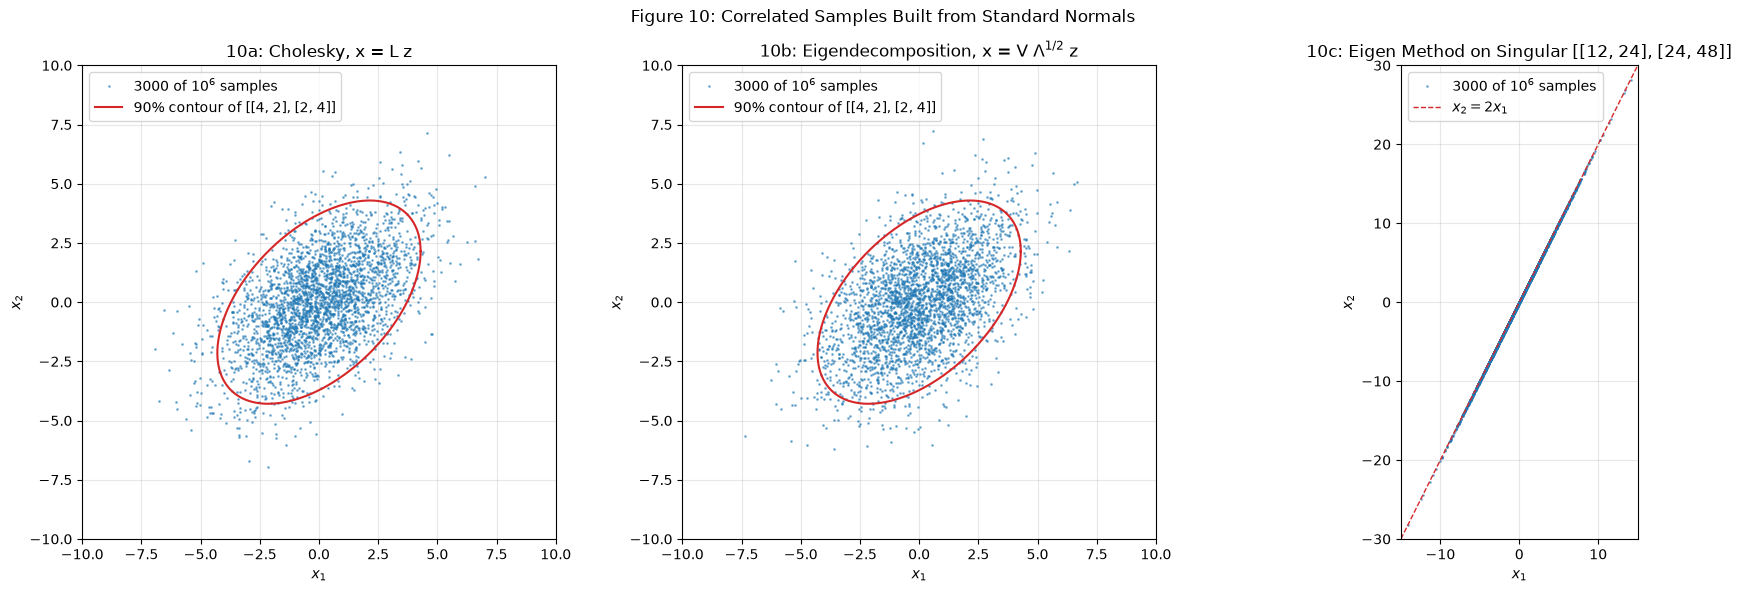

In [22]:
#Bonus A: Generating correlated vectors from scratch

N_A = 10**6 #One million samples

#Expected Frobenius error of a sample covariance from N Gaussian samples, sqrt((||Sigma||_F^2 + trace(Sigma)^2) / N)
#This is the same formula as the sqrt(d(d + 1)/N) we used in Step 6, because for Sigma = I it gives sqrt((d + d^2)/N)
def expected_cov_error(Sigma, N):
    return numpy.sqrt((numpy.sum(Sigma**2) + numpy.trace(Sigma)**2) / N)

#Method 1: Cholesky. Sigma = L L^T, then x = L z
def samples_cholesky(Sigma, N, generator):
    L = numpy.linalg.cholesky(Sigma)                   #Lower triangular L with L L^T = Sigma
    z = generator.standard_normal((N, len(Sigma)))     #Each row is one standard normal vector, covariance I
    return z @ L.T, L                                  #Each row of z @ L.T is L z for one sample

#Method 2: Eigendecomposition. Sigma = V Lambda V^T, then x = V Lambda^(1/2) z
def samples_eigen(Sigma, N, generator):
    eigenvalues, V = numpy.linalg.eigh(Sigma)
    eigenvalues = numpy.clip(eigenvalues, 0, None)     #Rounding can make a 0 eigenvalue slightly negative, sqrt needs 0 or larger
    B = V @ numpy.diag(numpy.sqrt(eigenvalues))        #B = V Lambda^(1/2), so B B^T = V Lambda V^T = Sigma
    z = generator.standard_normal((N, len(Sigma)))
    return z @ B.T, B

print(f"Part 1: Cholesky and Eigendecomposition Samples, N = {N_A}")
print("Sigma     Method      ||Factor Factor^T - Sigma||_F    ||Sample Cov - Sigma||_F    Expected Error    Ratio    Largest |Mean|")
samples_A = {}
for name, Sigma in [("2 x 2", Sigma_5), ("4 x 4", Sigma_3)]:
    for method, make in [("Cholesky", samples_cholesky), ("Eigen", samples_eigen)]:
        x, factor = make(Sigma, N_A, rngA)
        mean_x, cov_x = func.sample_mean_cov(x)
        rebuild_error = numpy.linalg.norm(factor @ factor.T - Sigma, "fro")
        cov_error = numpy.linalg.norm(cov_x - Sigma, "fro")
        expected = expected_cov_error(Sigma, N_A)
        print(f"{name:<10}{method:<12}{rebuild_error:<33.1e}{cov_error:<28.4f}{expected:<18.4f}{cov_error / expected:<9.2f}{numpy.max(numpy.abs(mean_x)):.4f}")
        samples_A[(name, method)] = x
print(f"Largest standard error of a sample mean, sqrt(largest variance / N): {numpy.sqrt(5 / N_A):.4f}")
print(f"Step 3 averaged error for the 4 x 4 Sigma at N = 10^6: {average_error_3[-1]:.4f}")

#The Cholesky factor of the 2 x 2 Sigma by hand: L = [[2, 0], [1, sqrt(3)]]
L_hand_A = numpy.array([[2, 0], [1, numpy.sqrt(3)]])
print(f"\nCholesky factor of [[4, 2], [2, 4]]: {numpy.round(numpy.linalg.cholesky(Sigma_5), 4).tolist()}   by hand [[2, 0], [1, sqrt(3) = {numpy.sqrt(3):.4f}]]")

#Part 2: Which is cheaper? Time both factorizations on a large covariance matrix
d_A = 500
A_rand = rngA.standard_normal((d_A, d_A))
Sigma_big_A = A_rand @ A_rand.T / d_A + numpy.eye(d_A)    #A A^T is positive semidefinite, adding I makes it positive definite

def best_time(f, repeats=5):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        f(Sigma_big_A)
        times.append(time.perf_counter() - t0)
    return min(times)

time_chol_A = best_time(numpy.linalg.cholesky)
time_eigh_A = best_time(numpy.linalg.eigh)
print(f"\nPart 2: Time to factor a {d_A} x {d_A} covariance (fastest of 5 runs)")
print(f"Cholesky: {1000 * time_chol_A:.2f} ms   eigh: {1000 * time_eigh_A:.2f} ms   eigh takes {time_eigh_A / time_chol_A:.1f} times as long")

#Part 3: Cholesky on the singular covariance from Step 4
Sigma_sing_A = Sigma_y2_exact_4.copy()                    #[[12, 24], [24, 48]], rank 1
L11_A = numpy.sqrt(Sigma_sing_A[0, 0])
L21_A = Sigma_sing_A[1, 0] / L11_A
L22_squared_A = Sigma_sing_A[1, 1] - L21_A**2

print(f"\nPart 3: Cholesky on the Singular Sigma = [[12, 24], [24, 48]]")
print(f"Eigenvalues: {numpy.round(numpy.linalg.eigvalsh(Sigma_sing_A), 4)}   det = {numpy.linalg.det(Sigma_sing_A):.1e}")
print(f"By hand: L11 = sqrt(12) = {L11_A:.4f}   L21 = 24 / L11 = {L21_A:.4f}   L22^2 = 48 - L21^2 = {L22_squared_A:.1e}")
try:
    numpy.linalg.cholesky(Sigma_sing_A)
    print("numpy.linalg.cholesky worked")
except numpy.linalg.LinAlgError as error:
    print(f"numpy.linalg.cholesky failed with LinAlgError: {error}")

#The eigendecomposition method still works on a singular covariance because sqrt(0) = 0 is fine
x_sing_A, B_sing_A = samples_eigen(Sigma_sing_A, N_A, rngA)
_, cov_sing_A = func.sample_mean_cov(x_sing_A)
frob_sing_A = numpy.linalg.norm(cov_sing_A - Sigma_sing_A, "fro")
print(f"Eigen method on the singular Sigma: ||Sample Cov - Sigma||_F = {frob_sing_A:.4f}   expected {expected_cov_error(Sigma_sing_A, N_A):.4f}   ratio {frob_sing_A / expected_cov_error(Sigma_sing_A, N_A):.2f}")
#With rank 1 every sample is sqrt(60) z2 times one fixed direction, so the whole error comes from one sample variance of z2
print(f"Sample variance of x1 / 12 = {cov_sing_A[0, 0] / 12:.4f}   (exact 1)")
print(f"Largest |x2 - 2 x1| over all samples: {numpy.max(numpy.abs(x_sing_A[:, 1] - 2 * x_sing_A[:, 0])):.1e}   largest |x2|: {numpy.max(numpy.abs(x_sing_A[:, 1])):.2f}")

#Figure 10: Cholesky samples, eigen samples, and the singular case
n_plot_A = 3000
theta_A = numpy.linspace(0, 2 * numpy.pi, 400)
ellipse_A = (numpy.linalg.cholesky(Sigma_5) @ numpy.vstack([numpy.cos(theta_A), numpy.sin(theta_A)])) * numpy.sqrt(k_5[1]) #90% contour from Step 5

plt.figure(figsize=(18, 6))
for p, method in enumerate(["Cholesky", "Eigen"]):
    x = samples_A[("2 x 2", method)]
    plt.subplot(1, 3, p + 1)
    plt.plot(x[:n_plot_A, 0], x[:n_plot_A, 1], ".", markersize=2, alpha=0.5, label=f"{n_plot_A} of $10^6$ samples")
    plt.plot(ellipse_A[0], ellipse_A[1], color="tab:red", label="90% contour of [[4, 2], [2, 4]]")
    plt.gca().set_aspect("equal")
    plt.xlim(-10, 10)
    plt.ylim(-10, 10)
    title = "10a: Cholesky, x = L z" if method == "Cholesky" else "10b: Eigendecomposition, x = V $\\Lambda^{1/2}$ z"
    plt.title(title)
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")
    plt.legend(loc="upper left")
    plt.grid(alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(x_sing_A[:n_plot_A, 0], x_sing_A[:n_plot_A, 1], ".", markersize=2, alpha=0.5, label=f"{n_plot_A} of $10^6$ samples")
x_line_A = numpy.linspace(-15, 15, 2)
plt.plot(x_line_A, 2 * x_line_A, color="tab:red", linestyle="--", linewidth=1, label="$x_2 = 2x_1$")
plt.gca().set_aspect("equal")
plt.xlim(-15, 15)
plt.ylim(-30, 30)
plt.title("10c: Eigen Method on Singular [[12, 24], [24, 48]]")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.suptitle("Figure 10: Correlated Samples Built from Standard Normals")
plt.tight_layout()
plt.show()


### Bonus A Results

    Both factors rebuild Sigma to rounding level (below 1e-14), and the Cholesky factor of [[4, 2], [2, 4]] came out as [[2, 0], [1, 1.7321]], which matches our hand answer with sqrt(3) = 1.7321. With 1 million samples the sample covariance was 0.0062 (Cholesky) and 0.0106 (eigen) from the 2 x 2 Sigma, against an expected error of 0.0102. For the 4 x 4 Sigma it was 0.0180 and 0.0175 against an expected 0.0165, and the averaged error in Step 3 at N = 10^6 was 0.0168, so our own generators do as well as numpy's multivariate_normal. The ratios to the expected error were 0.61, 1.04, 1.09 and 1.06. Each one is a single draw, and like the single draw errors in Step 3 it can land above or below the average. The largest sample mean was 0.0024, which is close to 0 since the standard error of a mean here is at most sqrt(5/10^6) = 0.0022 for the 4 x 4 Sigma.

### Figure 10 Explanation

    Figure 10a shows 3000 of the 1 million samples made with x = L z and Figure 10b shows samples made with x = V Lambda^(1/2) z, both with the 90% contour of [[4, 2], [2, 4]] from Step 5. You will notice that the two clouds look the same. Both are tilted at 45 degrees and fill the same ellipse, because both methods give the same covariance even though the individual samples are different. Figure 10c shows the eigen method on the singular covariance [[12, 24], [24, 48]] from Step 4. Every sample lands on the line x2 = 2x1, the same line as Figure 4.

### Which Method is Cheaper

    Cholesky is cheaper. It finds L in one pass down the matrix with about d^3/3 multiplications and no repeating. eigh has to repeat its steps until the eigenvalues settle, and it also has to build all of the eigenvectors, so it does several times more work. In our timing test on a 500 x 500 covariance, eigh took about 10 times as long as Cholesky (the exact times are printed above and change a little from run to run). L is also triangular, so L z only needs about half of the multiplications that V Lambda^(1/2) z needs, although numpy's @ does not skip the zeros. The eigen method is still useful because it works on a singular covariance, which Cholesky can not do.

### Cholesky on a Singular Covariance

Matching entries like before for $\Sigma=\begin{bmatrix}12&24\\24&48\end{bmatrix}$:

$$L_{11}=\sqrt{12}=3.4641 \qquad L_{21}=\frac{24}{3.4641}=6.9282 \qquad L_{22}^2=48-6.9282^2=48-48=0$$

    The last step needs the square root of 48 - 48 = 0. On paper that gives L22 = 0, but the computer got -7.1e-15 from rounding, and you can not take the square root of a negative number. numpy.linalg.cholesky stopped with LinAlgError: Matrix is not positive definite. Cholesky needs every one of these numbers to be greater than 0, which only happens when Sigma is positive definite. A singular Sigma has an eigenvalue of 0 (here the eigenvalues are 0 and 60), which means there is a direction with no variance at all, and in that direction the last diagonal entry of L has nothing left to be.

    The eigen method still works because it only needs the square root of each eigenvalue, and sqrt(0) = 0 is fine. Its samples had a sample covariance 0.0468 from Sigma against an expected 0.0849 (ratio 0.55). This is lower than the other ratios because with rank 1 all of the samples come from one standard normal times a fixed direction, so the whole error comes from a single sample variance. That variance came out 1.0008 times the exact value, and one number can land closer to its exact value than the expected spread, like it did here. The largest |x2 - 2x1| over all samples was exactly 0, so every sample sits on the line.

## Bonus B: Principal Components on Real Data

**Objective:** Use the eigendecomposition of a real covariance matrix to find the directions where the data changes the most, and see how the answer changes when we standardize the columns first.

**Data:** Fisher's Iris data, from R. A. Fisher (1936), "The use of multiple measurements in taxonomic problems", Annals of Eugenics, and also in the UCI Machine Learning Repository. It has 150 flowers from 3 species (50 each) with 4 numeric columns: sepal length, sepal width, petal length and petal width, all in cm. We copied the 150 rows from scikit-learn's copy of the dataset and typed them into the cell below, so the notebook does not need any extra package or file.

**Process:** In order to accomplish this objective we will estimate the covariance with sample_mean_cov, eigendecompose it, and find what fraction of the total variance the first two components hold. Then we will project the data onto the first two components and plot it. Lastly we will standardize each column, redo everything, and compare.

### Principal Components

The eigenvectors of the covariance are the directions where the data spreads out, and each eigenvalue is the variance along its eigenvector, just like the ellipse axes in Step 6. We sort them from largest to smallest and call them PC1, PC2, and so on. The total variance is the sum of the eigenvalues (the trace of $\Sigma$), so the fraction held by component $i$ is

$$\text{fraction}_i=\frac{\lambda_i}{\lambda_1+\lambda_2+\lambda_3+\lambda_4}$$

The projection of each flower onto the components is $V^T(\mathbf{x}-\bar{\mathbf{x}})$, the same decorrelating rotation as Step 6, so the projected scores are uncorrelated and have variances $\lambda_i$.

Standardizing divides each column by its standard deviation after subtracting the mean:

$$z_j=\frac{x_j-\bar x_j}{s_j}$$

Every standardized column has a variance of 1, so the covariance of the standardized data is the correlation matrix of the raw data and the total variance is 4.

In [23]:
#Bonus B data: Fisher's Iris data, 150 flowers and 4 measurements in cm
#Source: R. A. Fisher (1936), "The use of multiple measurements in taxonomic problems", Annals of Eugenics 7(2).
#Also in the UCI Machine Learning Repository (Iris dataset). We copied the 150 rows from scikit-learn's load_iris()
#and typed them in here so the notebook does not need any extra package or data file.
#Rows 0-49 are setosa, 50-99 are versicolor and 100-149 are virginica.

sepal_length_B = numpy.array([5.1, 4.9, 4.7, 4.6, 5.0, 5.4, 4.6, 5.0, 4.4, 4.9, 5.4, 4.8, 4.8, 4.3, 5.8, 5.7, 5.4, 5.1, 5.7, 5.1, 5.4, 5.1, 4.6, 5.1, 4.8,
    5.0, 5.0, 5.2, 5.2, 4.7, 4.8, 5.4, 5.2, 5.5, 4.9, 5.0, 5.5, 4.9, 4.4, 5.1, 5.0, 4.5, 4.4, 5.0, 5.1, 4.8, 5.1, 4.6, 5.3, 5.0,
    7.0, 6.4, 6.9, 5.5, 6.5, 5.7, 6.3, 4.9, 6.6, 5.2, 5.0, 5.9, 6.0, 6.1, 5.6, 6.7, 5.6, 5.8, 6.2, 5.6, 5.9, 6.1, 6.3, 6.1, 6.4,
    6.6, 6.8, 6.7, 6.0, 5.7, 5.5, 5.5, 5.8, 6.0, 5.4, 6.0, 6.7, 6.3, 5.6, 5.5, 5.5, 6.1, 5.8, 5.0, 5.6, 5.7, 5.7, 6.2, 5.1, 5.7,
    6.3, 5.8, 7.1, 6.3, 6.5, 7.6, 4.9, 7.3, 6.7, 7.2, 6.5, 6.4, 6.8, 5.7, 5.8, 6.4, 6.5, 7.7, 7.7, 6.0, 6.9, 5.6, 7.7, 6.3, 6.7,
    7.2, 6.2, 6.1, 6.4, 7.2, 7.4, 7.9, 6.4, 6.3, 6.1, 7.7, 6.3, 6.4, 6.0, 6.9, 6.7, 6.9, 5.8, 6.8, 6.7, 6.7, 6.3, 6.5, 6.2, 5.9])

sepal_width_B = numpy.array([3.5, 3.0, 3.2, 3.1, 3.6, 3.9, 3.4, 3.4, 2.9, 3.1, 3.7, 3.4, 3.0, 3.0, 4.0, 4.4, 3.9, 3.5, 3.8, 3.8, 3.4, 3.7, 3.6, 3.3, 3.4,
    3.0, 3.4, 3.5, 3.4, 3.2, 3.1, 3.4, 4.1, 4.2, 3.1, 3.2, 3.5, 3.6, 3.0, 3.4, 3.5, 2.3, 3.2, 3.5, 3.8, 3.0, 3.8, 3.2, 3.7, 3.3,
    3.2, 3.2, 3.1, 2.3, 2.8, 2.8, 3.3, 2.4, 2.9, 2.7, 2.0, 3.0, 2.2, 2.9, 2.9, 3.1, 3.0, 2.7, 2.2, 2.5, 3.2, 2.8, 2.5, 2.8, 2.9,
    3.0, 2.8, 3.0, 2.9, 2.6, 2.4, 2.4, 2.7, 2.7, 3.0, 3.4, 3.1, 2.3, 3.0, 2.5, 2.6, 3.0, 2.6, 2.3, 2.7, 3.0, 2.9, 2.9, 2.5, 2.8,
    3.3, 2.7, 3.0, 2.9, 3.0, 3.0, 2.5, 2.9, 2.5, 3.6, 3.2, 2.7, 3.0, 2.5, 2.8, 3.2, 3.0, 3.8, 2.6, 2.2, 3.2, 2.8, 2.8, 2.7, 3.3,
    3.2, 2.8, 3.0, 2.8, 3.0, 2.8, 3.8, 2.8, 2.8, 2.6, 3.0, 3.4, 3.1, 3.0, 3.1, 3.1, 3.1, 2.7, 3.2, 3.3, 3.0, 2.5, 3.0, 3.4, 3.0])

petal_length_B = numpy.array([1.4, 1.4, 1.3, 1.5, 1.4, 1.7, 1.4, 1.5, 1.4, 1.5, 1.5, 1.6, 1.4, 1.1, 1.2, 1.5, 1.3, 1.4, 1.7, 1.5, 1.7, 1.5, 1.0, 1.7, 1.9,
    1.6, 1.6, 1.5, 1.4, 1.6, 1.6, 1.5, 1.5, 1.4, 1.5, 1.2, 1.3, 1.4, 1.3, 1.5, 1.3, 1.3, 1.3, 1.6, 1.9, 1.4, 1.6, 1.4, 1.5, 1.4,
    4.7, 4.5, 4.9, 4.0, 4.6, 4.5, 4.7, 3.3, 4.6, 3.9, 3.5, 4.2, 4.0, 4.7, 3.6, 4.4, 4.5, 4.1, 4.5, 3.9, 4.8, 4.0, 4.9, 4.7, 4.3,
    4.4, 4.8, 5.0, 4.5, 3.5, 3.8, 3.7, 3.9, 5.1, 4.5, 4.5, 4.7, 4.4, 4.1, 4.0, 4.4, 4.6, 4.0, 3.3, 4.2, 4.2, 4.2, 4.3, 3.0, 4.1,
    6.0, 5.1, 5.9, 5.6, 5.8, 6.6, 4.5, 6.3, 5.8, 6.1, 5.1, 5.3, 5.5, 5.0, 5.1, 5.3, 5.5, 6.7, 6.9, 5.0, 5.7, 4.9, 6.7, 4.9, 5.7,
    6.0, 4.8, 4.9, 5.6, 5.8, 6.1, 6.4, 5.6, 5.1, 5.6, 6.1, 5.6, 5.5, 4.8, 5.4, 5.6, 5.1, 5.1, 5.9, 5.7, 5.2, 5.0, 5.2, 5.4, 5.1])

petal_width_B = numpy.array([0.2, 0.2, 0.2, 0.2, 0.2, 0.4, 0.3, 0.2, 0.2, 0.1, 0.2, 0.2, 0.1, 0.1, 0.2, 0.4, 0.4, 0.3, 0.3, 0.3, 0.2, 0.4, 0.2, 0.5, 0.2,
    0.2, 0.4, 0.2, 0.2, 0.2, 0.2, 0.4, 0.1, 0.2, 0.2, 0.2, 0.2, 0.1, 0.2, 0.2, 0.3, 0.3, 0.2, 0.6, 0.4, 0.3, 0.2, 0.2, 0.2, 0.2,
    1.4, 1.5, 1.5, 1.3, 1.5, 1.3, 1.6, 1.0, 1.3, 1.4, 1.0, 1.5, 1.0, 1.4, 1.3, 1.4, 1.5, 1.0, 1.5, 1.1, 1.8, 1.3, 1.5, 1.2, 1.3,
    1.4, 1.4, 1.7, 1.5, 1.0, 1.1, 1.0, 1.2, 1.6, 1.5, 1.6, 1.5, 1.3, 1.3, 1.3, 1.2, 1.4, 1.2, 1.0, 1.3, 1.2, 1.3, 1.3, 1.1, 1.3,
    2.5, 1.9, 2.1, 1.8, 2.2, 2.1, 1.7, 1.8, 1.8, 2.5, 2.0, 1.9, 2.1, 2.0, 2.4, 2.3, 1.8, 2.2, 2.3, 1.5, 2.3, 2.0, 2.0, 1.8, 2.1,
    1.8, 1.8, 1.8, 2.1, 1.6, 1.9, 2.0, 2.2, 1.5, 1.4, 2.3, 2.4, 1.8, 1.8, 2.1, 2.4, 2.3, 1.9, 2.3, 2.5, 2.3, 1.9, 2.0, 2.3, 1.8])

#Each row is one flower and each column is one measurement
X_B = numpy.column_stack([sepal_length_B, sepal_width_B, petal_length_B, petal_width_B])
names_B = ["Sepal length", "Sepal width", "Petal length", "Petal width"]
species_B = numpy.repeat(["Setosa", "Versicolor", "Virginica"], 50)
print(f"Iris data: {X_B.shape[0]} flowers and {X_B.shape[1]} numeric columns (cm)")


Iris data: 150 flowers and 4 numeric columns (cm)


Column variances (cm^2):  Sepal length 0.6857   Sepal width 0.1900   Petal length 3.1163   Petal width 0.5810
Largest |covariance of standardized data - correlation matrix|: 1.3e-15

Raw (cm)
Eigenvalues:            [4.2282 0.2427 0.0782 0.0238]   total variance 4.5730
Fraction of variance:   [0.9246 0.0531 0.0171 0.0052]
First two components:   0.9777   (PC1 92.46%, PC2 5.31%, together 97.77%)
Column            PC1 Weight    PC2 Weight
Sepal length      -0.361        0.657
Sepal width       0.085         0.730
Petal length      -0.857        -0.173
Petal width       -0.358        -0.075
Variance of the PC1 and PC2 scores: 4.2282 and 0.2427   covariance between them: 4.0e-16

Standardized
Eigenvalues:            [2.9185 0.914  0.1468 0.0207]   total variance 4.0000
Fraction of variance:   [0.7296 0.2285 0.0367 0.0052]
First two components:   0.9581   (PC1 72.96%, PC2 22.85%, together 95.81%)
Column            PC1 Weight    PC2 Weight
Sepal length      -0.521        0.377
Sepal width   

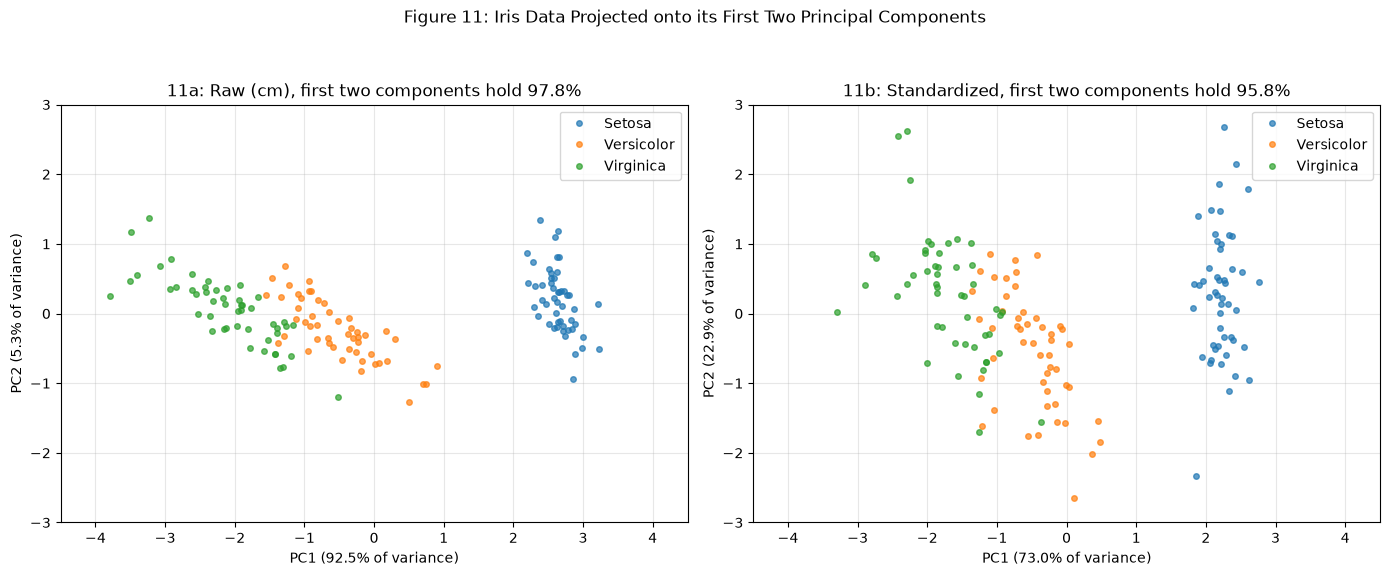

In [24]:
#Bonus B: Principal components on real data

#PCA: eigendecompose the covariance and sort the eigenvalues from largest to smallest
def pca(data):
    mean, cov = func.sample_mean_cov(data)
    eigenvalues, V = numpy.linalg.eigh(cov)        #eigh gives the eigenvalues from smallest to largest
    order = numpy.argsort(eigenvalues)[::-1]       #Flip so the largest comes first
    eigenvalues = eigenvalues[order]
    V = V[:, order]
    scores = (data - mean) @ V                     #Coordinates of each flower along the components
    return cov, eigenvalues, V, scores

#Raw data in cm
cov_raw_B, eig_raw_B, V_raw_B, scores_raw_B = pca(X_B)

#Standardized data: subtract the mean of each column and divide by its standard deviation, so every column has variance 1
mean_B, _ = func.sample_mean_cov(X_B)
std_B = X_B.std(axis=0, ddof=1)
Z_B = (X_B - mean_B) / std_B
cov_std_B, eig_std_B, V_std_B, scores_std_B = pca(Z_B)

#The covariance of standardized data is the correlation matrix of the raw data
corr_B = numpy.corrcoef(X_B.T)

print("Column variances (cm^2):  " + "   ".join(f"{n} {v:.4f}" for n, v in zip(names_B, numpy.diag(cov_raw_B))))
print(f"Largest |covariance of standardized data - correlation matrix|: {numpy.max(numpy.abs(cov_std_B - corr_B)):.1e}")

for label, eig, V, scores in [("Raw (cm)", eig_raw_B, V_raw_B, scores_raw_B), ("Standardized", eig_std_B, V_std_B, scores_std_B)]:
    fraction = eig / eig.sum()
    _, cov_scores = func.sample_mean_cov(scores[:, :2])
    print(f"\n{label}")
    print(f"Eigenvalues:            {numpy.round(eig, 4)}   total variance {eig.sum():.4f}")
    print(f"Fraction of variance:   {numpy.round(fraction, 4)}")
    print(f"First two components:   {fraction[0] + fraction[1]:.4f}   (PC1 {100 * fraction[0]:.2f}%, PC2 {100 * fraction[1]:.2f}%, together {100 * (fraction[0] + fraction[1]):.2f}%)")
    print("Column            PC1 Weight    PC2 Weight")
    for j in range(4):
        print(f"{names_B[j]:<18}{V[j, 0]:<14.3f}{V[j, 1]:.3f}")
    print(f"Variance of the PC1 and PC2 scores: {cov_scores[0, 0]:.4f} and {cov_scores[1, 1]:.4f}   covariance between them: {abs(cov_scores[0, 1]):.1e}")

#Share of PC1 that comes from petal length (its weight squared, since the weights squared add to 1)
print(f"\nPetal length share of PC1: raw {100 * V_raw_B[2, 0]**2:.2f}%   standardized {100 * V_std_B[2, 0]**2:.2f}%")

#Figure 11: data projected onto the first two components, raw and standardized
colors_B = {"Setosa": "tab:blue", "Versicolor": "tab:orange", "Virginica": "tab:green"}
plt.figure(figsize=(14, 6))
for p, (label, eig, scores) in enumerate([("Raw (cm)", eig_raw_B, scores_raw_B), ("Standardized", eig_std_B, scores_std_B)]):
    fraction = eig / eig.sum()
    plt.subplot(1, 2, p + 1)
    for s in colors_B:
        rows = species_B == s
        plt.plot(scores[rows, 0], scores[rows, 1], "o", color=colors_B[s], markersize=4, alpha=0.7, label=s)
    plt.gca().set_aspect("equal")
    plt.xlim(-4.5, 4.5)
    plt.ylim(-3, 3)
    plt.title(f"11{'ab'[p]}: {label}, first two components hold {100 * (fraction[0] + fraction[1]):.1f}%")
    plt.xlabel(f"PC1 ({100 * fraction[0]:.1f}% of variance)")
    plt.ylabel(f"PC2 ({100 * fraction[1]:.1f}% of variance)")
    plt.legend(loc="upper right")
    plt.grid(alpha=0.3)

plt.suptitle("Figure 11: Iris Data Projected onto its First Two Principal Components")
plt.tight_layout()
plt.show()


### Bonus B Results

    For the raw data the eigenvalues were 4.2282, 0.2427, 0.0782 and 0.0238. PC1 holds 92.46% of the variance and PC2 holds 5.31%, so the first two components hold 97.77%. PC1 has a weight of -0.857 on petal length, so 73.39% of PC1 comes from petal length alone. This is because petal length has the largest variance of the four columns (3.1163 cm^2, against 0.1900 for sepal width).

    For the standardized data the eigenvalues were 2.9185, 0.9140, 0.1468 and 0.0207, which add up to 4. PC1 holds 72.96% and PC2 holds 22.85%, so the first two components hold 95.81%. Now PC1 has about the same weight on sepal length, petal length and petal width (-0.521, -0.580 and -0.565), and only 33.69% of it comes from petal length. PC2 is mostly sepal width (0.923). The signs of the weights do not matter, an eigenvector is only defined up to sign like in Step 6. In both cases the projected scores had variances equal to the eigenvalues and a covariance between PC1 and PC2 at rounding level (below 1e-15), so the projection decorrelates the data like in Step 6. The covariance of the standardized data matched the correlation matrix to rounding level.

### Figure 11 Explanation

    Figure 11a shows the 150 flowers projected onto the first two components of the raw data, and Figure 11b shows the same for the standardized data. In both, setosa (blue) is far away from the other two species along PC1, and versicolor and virginica overlap a little. You will notice that 11a is spread out mostly from left to right, because PC2 only holds 5.31% of the variance, while 11b has more spread from top to bottom because PC2 holds 22.85%. Both panels use equal axes so the spread in each direction can be compared.

### Raw or Standardized?

    The answer changes because PCA on raw data looks for the columns with the largest variance, and the variance depends on the units. Petal length has the largest variance in cm^2, so raw PC1 is 73.39% petal length, and raw PCA mostly tells us which column has the largest numbers. If we measured petal length in mm, its variance would be 100 times larger and raw PC1 would be almost only petal length, even though the flowers did not change. Standardizing gives every column a variance of 1, so the result does not depend on the units, and it shows the real structure: sepal length, petal length and petal width grow together (the overall size of the flower, PC1) while sepal width is mostly its own direction (PC2). We would trust the standardized version. All four columns here are in cm, so the raw version is not wrong, but the standardized version is the one that would give the same answer if someone measured the flowers in different units.

In [25]:
#Total notebook runtime
total_runtime = time.time() - T_START

print("Total notebook runtime:", round(total_runtime / 60, 2), "minutes")

#Youtube unlisted demo video
#youtube.com/watch?v=nrKGP9_ngF4&feature=youtu.be

Total notebook runtime: 0.2 minutes
